# Individual Differences in Bayesian Prior Updating Across Mice

**How quickly does each mouse update its expectations from past choices — and do mice fall into discrete "fast" and "slow" updater types, or vary along a continuum?**

*A project from [Neuromatch Academy: Computational Neuroscience](https://compneuro.neuromatch.io/), analyzing open behavioral data from the [International Brain Laboratory (IBL) Brain-Wide Map](https://www.internationalbrainlab.com/brainwide-map).*

**Author:** [omidiz](https://github.com/omidiz)

---

## Summary

In the IBL decision-making task, mice report whether a visual grating appeared on the left or the right. Unannounced blocks make one side more likely (80 : 20), so a mouse that keeps track of recent history can guess better when the stimulus is hard to see. Following Findling et al. (2025), we model the mouse's subjective prior as an **action kernel** — an exponentially weighted average of its own past choices — with update rate α and timescale **τ = −1 / ln(1 − α)** trials.

For every mouse with at least two Brain-Wide Map sessions, we fit **one α shared across all of its sessions** (sensory noise and lapse rates are free for each session) by maximum likelihood, measure the uncertainty with profile likelihood, and then ask whether the population of timescales forms discrete groups or a continuum.

| | Result |
|---|---|
| **Data** | 107 mice with ≥ 2 sessions (out of 139 in the Brain-Wide Map); 107 / 107 fits succeeded and 106 passed quality control |
| **Prior use** | In an example session the hidden block prior strongly shifts choices: at 0 % contrast, P(right) = 0.93 in right-biased vs 0.41 in left-biased blocks; adding the block to a stimulus-only logistic model gives ΔAIC = −19.1 |
| **Stable trait** | For the example mouse (13 sessions), one shared α beats session-specific α values (ΔAIC = −13.4) |
| **Individual differences** | τ ranges from 2.7 to 41 trials across mice (median 5.5, IQR 4.2 – 7.0); the median closely matches the 5.45 trials reported by Findling et al. (2025) |
| **Groups or continuum?** | BIC mildly prefers two Gaussian components on log τ (ΔBIC = 4.6), but the components overlap (separation D = 1.7 < 2) and the preference is fragile: K = 2 wins in only 46 % of bootstrap resamples, and K = 1 wins 41 % of the time once estimation uncertainty is included |
| **Conclusion** | Prior-updating speed differs substantially between mice, but it is best described as a **continuous computational phenotype**, not as discrete classes |

## Background

### The IBL decision-making task

Head-fixed mice see a grating on the left or right side of a screen and report its location by turning a wheel. Correct choices are rewarded with a drop of sugar water; errors are followed by a noise burst and a timeout. The contrast of the grating changes from trial to trial (100, 25, 12.5, 6.25 or 0 %), so on many trials the visual evidence is weak or absent.

Each session starts with 90 unbiased trials. After that, the stimulus appears on the left with probability **0.8 or 0.2**, in blocks of 20 – 100 trials (about 51 on average) that switch **without any cue** (IBL et al., 2021). On difficult trials, a mouse can therefore do better than chance only by *estimating* which block it is in — that is, by keeping a **prior belief** about the stimulus side and updating it from experience.

### How do mice estimate the prior?

An ideal observer would infer the hidden block from the sequence of past stimuli. The IBL found, however, that mouse choices are better explained by an **action kernel**: the prior is an exponentially weighted average of the mouse's *own past choices* (Findling et al., 2025). Its single parameter — the update rate α, or equivalently the timescale τ — sets how far back into its history the mouse effectively looks.

### Why individual differences?

Models fitted to the "average mouse" hide how much individual animals differ. Some mice might react mostly to the last one or two trials, while others integrate over many. If such differences are stable, τ is a **computational phenotype**: an individual trait that can later be related to the brain activity recorded from the same mice in the Brain-Wide Map. This raises a second question: do mice adopt **discrete strategies** (for example "fast" and "slow" updaters), or does τ vary **continuously**?

## Research question and hypotheses

> **Do individual mice differ in the timescale over which they update prior beliefs from past choices — and is this variation discrete or continuous?**

| | Hypothesis | How it is tested |
|---|---|---|
| **H1** | Mice use the block prior: choices are biased toward the more likely side, most strongly when the stimulus is weak. | Psychometric curves and logistic regression for one session (Steps 5 – 6) |
| **H2** | The update rate is a stable trait: one α per mouse describes its sessions as well as one α per session. | Shared vs session-specific α, compared with AIC (Step 13) |
| **H3** | Mice differ in τ beyond estimation uncertainty. | Population fit with profile-likelihood intervals (Steps 15 – 17) |
| **H4** | If mice adopt discrete strategies, log τ is multimodal and a mixture of well-separated components is *robustly* preferred; otherwise τ is a continuous phenotype. | Gaussian mixture models with bootstrap, measurement-uncertainty and leave-one-out checks (Steps 18 – 19) |

## Notebook outline

| Part | Steps | Content |
|---|---|---|
| 0 · Setup | 1 | Install the IBL Brain-Wide Map code and connect to the public database |
| 1 · Dataset | 2 | What the Brain-Wide Map contains and which mice can be modeled |
| 2 · One example session | 3 – 6 | Pre-processing, block structure, psychometric curves, logistic regression |
| 3 · Model | 7 – 9 | Action-kernel prior, Bayesian observer with lapses, likelihood |
| 4 · One mouse in depth | 10 – 14 | Profile likelihood, pooling sessions, shared vs session-specific α, final pipeline |
| 5 · Population | 15 – 16 | Fitting all 107 mice and quality control |
| 6 · Groups or continuum? | 17 – 19 | Distribution of τ, Gaussian mixture models, robustness checks |
| 7 · Output | 20 | Frozen table of behavioral phenotypes |
| — | — | Conclusions, limitations, next steps and references |

> **About the saved outputs.** All outputs are stored in this notebook, so it can be read without running anything. Data are streamed from the public IBL server through the [ONE API](https://int-brain-lab.github.io/ONE/). The population fit in Step 15 is slow (about 4.4 hours in total, 1 – 8 minutes per mouse); it saves a checkpoint after every mouse and resumes where it stopped.
>
> After the run, the notebook was tidied up: Markdown and code comments were rewritten, leftover scratch cells were removed, the installation output was cleared, and two defensive fixes were added (consistent return values in `fit_mouse_action_kernel` when a fit fails, and reloading the checkpoint before quality control). None of these changes affects any result shown.

---

## Part 0 · Setup

### Step 1 — Install the IBL tools and connect to the database

* [`paper-brain-wide-map`](https://github.com/int-brain-lab/paper-brain-wide-map) is the official code of the Brain-Wide Map paper. Two of its functions are used here:
  * `bwm_query` — the table of sessions and probe insertions in the Brain-Wide Map release;
  * `load_trials_and_mask` — a session's trial table plus the standard Brain-Wide Map **trial-inclusion mask** (here: reaction time between 0.08 and 2 s, no missing values in the key trial events).
* [`ONE`](https://int-brain-lab.github.io/ONE/) connects to **OpenAlyx**, the IBL's public database. The credentials in the code are the public ones published by the IBL.

The installation cell clones the repository into the current folder and moves into it, so everything the notebook saves later goes to `paper-brain-wide-map/results/`.

In [1]:
# ============================================================
# STEP 1 — Basic Python libraries
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# ============================================================
# STEP 1 — Install official Brain-Wide Map code
# ============================================================
# Clone the IBL repository and install it in editable mode.
# Run once per environment. The notebook then works from inside
# the cloned folder, so results are saved to
# paper-brain-wide-map/results/ (see Step 15).

!git clone -q https://github.com/int-brain-lab/paper-brain-wide-map.git
%cd paper-brain-wide-map
!pip install -q --upgrade setuptools wheel
!pip install -q --no-build-isolation -e .

In [5]:
# ============================================================
# STEP 1 — Import IBL tools
# ============================================================

from one.api import ONE
from brainwidemap import bwm_query, load_trials_and_mask

In [6]:
# ============================================================
# STEP 1 — Connect to public IBL database
# ============================================================
# OpenAlyx is the IBL's public, read-only database; these are
# the public credentials published by the IBL.

one = ONE(
    base_url="https://openalyx.internationalbrainlab.org",
    password="international"
)

print(one)

Connected to https://openalyx.internationalbrainlab.org as user "intbrainlab"
One (online, https://openalyx.internationalbrainlab.org)


---

## Part 1 · The Brain-Wide Map dataset

### Step 2 — What does the release contain?

`bwm_query` returns one row per **probe insertion** (`pid`). Each insertion belongs to a **session** (`eid`), a **mouse** (`subject`) and a **lab**; a session can have one or two probes. Because the mouse is our unit of analysis, we count sessions per mouse.

In [7]:
# ============================================================
# STEP 2 — Load the Brain-Wide Map index
# ============================================================

bwm_df = bwm_query(one)

print("Brain-Wide Map table loaded.")

Loading bwm_query results from fixtures/2023_12_bwm_release.csv
Brain-Wide Map table loaded.


In [8]:
# ============================================================
# STEP 2 — Basic shape of the BWM table
# ============================================================

print("Shape of bwm_df:")
print(bwm_df.shape)

Shape of bwm_df:
(699, 7)


In [9]:
# ============================================================
# STEP 2 — Inspect column names
# ============================================================

print("Columns:")
print(bwm_df.columns.tolist())

Columns:
['pid', 'eid', 'probe_name', 'session_number', 'date', 'subject', 'lab']


In [10]:
# ============================================================
# STEP 2 — Look at the first rows
# ============================================================

display(bwm_df.head())

,pid,eid,probe_name,session_number,date,subject,lab
0,56f2a378-78d2-4132-b3c8-8c1ba82be598,6713a4a7-faed-4df2-acab-ee4e63326f8d,probe00,1,2020-02-18,NYU-11,angelakilab
1,47be9ae4-290f-46ab-b047-952bc3a1a509,56956777-dca5-468c-87cb-78150432cc57,probe01,1,2020-02-21,NYU-11,angelakilab
2,6be21156-33b0-4f70-9a0f-65b3e3cd6d4a,56956777-dca5-468c-87cb-78150432cc57,probe00,1,2020-02-21,NYU-11,angelakilab
3,8dfb86c8-d45c-46c4-90ec-33078014d434,4364a246-f8d7-4ce7-ba23-a098104b96e4,probe01,1,2020-01-20,NYU-12,angelakilab
4,c893c0a3-5597-49cf-baa1-60efdfdef542,b182b754-3c3e-4942-8144-6ee790926b58,probe01,1,2020-01-21,NYU-12,angelakilab


In [11]:
# ============================================================
# STEP 2 — Main Brain-Wide Map data audit
# ============================================================

n_probe_insertions = len(bwm_df)

n_sessions = bwm_df["eid"].nunique()

n_mice = bwm_df["subject"].nunique()

n_labs = bwm_df["lab"].nunique()


print("=" * 60)
print("BRAIN-WIDE MAP DATA AUDIT")
print("=" * 60)

print(f"Probe insertions : {n_probe_insertions}")
print(f"Unique sessions  : {n_sessions}")
print(f"Unique mice      : {n_mice}")
print(f"Unique labs      : {n_labs}")

print("=" * 60)

BRAIN-WIDE MAP DATA AUDIT
Probe insertions : 699
Unique sessions  : 459
Unique mice      : 139
Unique labs      : 12


These numbers match the published Brain-Wide Map: 699 Neuropixels insertions in 139 mice from 12 laboratories (IBL et al., 2025). The table is read from the release file `2023_12_bwm_release.csv`.

In [12]:
# ============================================================
# STEP 2 — Build a mouse-level overview
# ============================================================

mouse_overview = (
    bwm_df
    .groupby("subject")
    .agg(
        n_sessions=("eid", "nunique"),
        n_probes=("pid", "nunique")
    )
    .reset_index()
    .sort_values(
        "n_sessions",
        ascending=False
    )
)

display(mouse_overview.head(20))

,subject,n_sessions,n_probes
77,PL033,13,13
20,DY_009,9,9
81,PL050,9,11
137,ibl_witten_29,9,11
27,DY_020,8,16
14,CSH_ZAD_022,8,12
75,PL030,8,8
18,CSH_ZAD_029,7,14
86,SWC_052,7,13
16,CSH_ZAD_025,7,12


In [13]:
# ============================================================
# STEP 2 — How many sessions does each mouse have?
# ============================================================

print(
    mouse_overview["n_sessions"]
    .value_counts()
    .sort_index()
)

n_sessions
1     32
2     25
3     29
4     20
5     16
6      4
7      6
8      3
9      3
13     1
Name: count, dtype: int64


In [14]:
# ============================================================
# STEP 2 — Candidate mice for mouse-level modeling
# ============================================================

n_mice_2plus = (
    mouse_overview["n_sessions"] >= 2
).sum()

print(
    "Number of mice with at least 2 sessions:",
    n_mice_2plus
)

Number of mice with at least 2 sessions: 107


In [15]:
# ============================================================
# STEP 2 — Final summary to share
# ============================================================

print("=" * 60)
print("STEP 2 SUMMARY")
print("=" * 60)

print(
    "BWM table shape:",
    bwm_df.shape
)

print(
    "Unique sessions:",
    bwm_df["eid"].nunique()
)

print(
    "Unique mice:",
    bwm_df["subject"].nunique()
)

print(
    "Probe insertions:",
    bwm_df["pid"].nunique()
)

print(
    "Mice with >= 2 sessions:",
    (
        mouse_overview["n_sessions"] >= 2
    ).sum()
)

print("=" * 60)

print("\nTop 10 mice by number of sessions:")

display(
    mouse_overview.head(10)
)

STEP 2 SUMMARY
BWM table shape: (699, 7)
Unique sessions: 459
Unique mice: 139
Probe insertions: 699
Mice with >= 2 sessions: 107

Top 10 mice by number of sessions:


,subject,n_sessions,n_probes
77,PL033,13,13
20,DY_009,9,9
81,PL050,9,11
137,ibl_witten_29,9,11
27,DY_020,8,16
14,CSH_ZAD_022,8,12
75,PL030,8,8
18,CSH_ZAD_029,7,14
86,SWC_052,7,13
16,CSH_ZAD_025,7,12


**Which mice can be modeled?** Most mice contribute only a few sessions: 32 have a single session and the median is 3. Our approach estimates one timescale per mouse by pooling *all* of its sessions, so we keep the **107 mice with at least two sessions**. Pooling across days gives more trials per estimate and describes the mouse rather than a single day.

---

## Part 2 · A first look at one mouse

### Step 3 — Load one behavioral session

We start with **PL033**, the mouse with the most sessions (13), and look at its first session (4 October 2022).

`load_trials_and_mask` returns two objects:

* `trials` — one row per trial, in chronological order;
* `mask` — `True` for trials that pass the Brain-Wide Map inclusion criteria.

**Design choice: no trial is ever deleted.** The mouse experienced *every* trial, so its belief about the next stimulus should be updated after every choice it made. The mask is only used later, to decide which trials enter the **likelihood** (Step 9).

In [16]:
# ============================================================
# STEP 3 — Select one example mouse
# ============================================================

example_mouse = (
    mouse_overview
    .loc[mouse_overview["n_sessions"] >= 2, "subject"]
    .iloc[0]
)

print("Example mouse:")
print(example_mouse)

Example mouse:
PL033


In [17]:
# ============================================================
# STEP 3 — Find sessions belonging to the example mouse
# ============================================================

example_sessions = (
    bwm_df
    .loc[
        bwm_df["subject"] == example_mouse,
        ["eid", "date", "session_number"]
    ]
    .drop_duplicates(subset="eid")
    .sort_values(["date", "session_number"])
    .reset_index(drop=True)
)

print(
    "Number of sessions for",
    example_mouse,
    ":",
    len(example_sessions)
)

display(example_sessions)

Number of sessions for PL033 : 13


,eid,date,session_number
0,62902992-8432-46fb-af12-6392012e58c7,2022-10-04,2
1,4546cd60-fa2a-4d20-a9b6-d091e01d16f2,2022-10-05,1
2,cef05f87-161b-4031-932c-6f47daf89698,2022-10-06,1
3,75db708a-9952-4452-a5b1-a851d88f8e28,2022-10-07,1
4,7f150b7c-c261-46e6-9edb-cc391c9d9f03,2022-10-10,1
5,837b4e6a-ccfd-49b0-a1dd-3aa53fbf2ecb,2022-10-11,1
6,9fc31d79-b56f-46d0-92a0-e9563caf4a7a,2022-10-12,1
7,a34b4013-414b-42ed-9318-e93fbbc71e7b,2022-10-25,1
8,49250fba-801c-4867-a0a7-a1e19538cb61,2022-10-26,1
9,2ab7d2c2-bcb7-4ae6-9626-f3786c22d970,2022-10-28,1


In [18]:
# ============================================================
# STEP 3 — Select one example session
# ============================================================

example_eid = example_sessions["eid"].iloc[0]

example_date = example_sessions["date"].iloc[0]

print("Example mouse:", example_mouse)
print("Example date :", example_date)
print("Example eid  :", example_eid)

Example mouse: PL033
Example date : 2022-10-04
Example eid  : 62902992-8432-46fb-af12-6392012e58c7


In [19]:
# ============================================================
# STEP 3 — Load behavioral trials
# ============================================================

trials, mask = load_trials_and_mask(
    one,
    example_eid,
    min_rt=0.08,
    max_rt=2.0,
    nan_exclude="default"
)

print("Behavioral data loaded.")

Behavioral data loaded.


In [20]:
# ============================================================
# STEP 3 — Behavioral table shape
# ============================================================

print("Trials shape:")
print(trials.shape)

print("\nMask shape:")
print(mask.shape)

print("\nTotal trials:")
print(len(trials))

print("\nTrials passing BWM mask:")
print(mask.sum())

print("\nFraction passing mask:")
print(mask.mean())

Trials shape:
(659, 18)

Mask shape:
(659,)

Total trials:
659

Trials passing BWM mask:
375

Fraction passing mask:
0.5690440060698028


In [21]:
# ============================================================
# STEP 3 — Inspect behavioral variables
# ============================================================

print("Behavioral columns:")

for col in trials.columns:
    print(col)

Behavioral columns:
goCueTrigger_times
intervals_bpod_0
intervals_bpod_1
quiescencePeriod
stimOff_times
goCue_times
response_times
choice
stimOn_times
contrastLeft
contrastRight
probabilityLeft
feedback_times
feedbackType
rewardVolume
firstMovement_times
intervals_0
intervals_1


In [22]:
# ============================================================
# STEP 3 — Inspect first behavioral trials
# ============================================================

display(trials.head())

,goCueTrigger_times,intervals_bpod_0,intervals_bpod_1,quiescencePeriod,stimOff_times,goCue_times,response_times,choice,stimOn_times,contrastLeft,contrastRight,probabilityLeft,feedback_times,feedbackType,rewardVolume,firstMovement_times,intervals_0,intervals_1
0,112.684634,0.0000,4.999902,0.441705,114.192580,112.685664,113.130234,1.0,112.756290,1.00,NaN,0.5,113.130319,1.0,1.5,112.764715,109.692730,114.692638
1,117.172938,5.5906,9.313602,0.410087,118.506315,117.173581,117.453439,-1.0,117.172815,NaN,0.125,0.5,117.453520,1.0,1.5,117.326715,115.283337,119.006342
2,120.692340,9.8951,12.980102,0.446345,122.172748,120.693196,121.121341,1.0,120.692163,0.25,NaN,0.5,121.121420,1.0,1.5,120.871715,119.587840,122.672843
3,123.776038,13.5495,15.846803,0.467037,125.039461,123.776821,123.994136,-1.0,123.775855,NaN,1.000,0.5,123.994233,1.0,1.5,123.819715,123.242241,125.539529
4,126.625522,16.4027,19.846602,0.479629,129.039261,126.626436,126.990122,-1.0,126.625336,0.00,NaN,0.5,126.991100,-1.0,0.0,126.794715,126.095423,129.539323


In [23]:
# ============================================================
# STEP 3 — Focus on key behavioral variables
# ============================================================

key_columns = [
    "choice",
    "contrastLeft",
    "contrastRight",
    "probabilityLeft",
    "feedbackType"
]

available_key_columns = [
    col for col in key_columns
    if col in trials.columns
]

display(
    trials[available_key_columns].head(20)
)

,choice,contrastLeft,contrastRight,probabilityLeft,feedbackType
0,1.0,1.000,NaN,0.5,1.0
1,-1.0,NaN,0.1250,0.5,1.0
2,1.0,0.250,NaN,0.5,1.0
3,-1.0,NaN,1.0000,0.5,1.0
4,-1.0,0.000,NaN,0.5,-1.0
5,-1.0,NaN,0.0000,0.5,1.0
6,-1.0,NaN,1.0000,0.5,1.0
7,-1.0,NaN,0.1250,0.5,1.0
8,-1.0,1.000,NaN,0.5,-1.0
9,-1.0,NaN,0.1250,0.5,1.0


In [24]:
# ============================================================
# STEP 3 — Audit important behavioral variables
# ============================================================

important_columns = [
    "choice",
    "contrastLeft",
    "contrastRight",
    "probabilityLeft",
    "feedbackType"
]


print("=" * 70)
print("BEHAVIORAL VARIABLE AUDIT")
print("=" * 70)


for col in important_columns:

    print(f"\n--- {col} ---")

    if col not in trials.columns:

        print("Column not found.")
        continue

    print(
        "Missing values:",
        trials[col].isna().sum()
    )

    print(
        "Unique values:"
    )

    values = (
        trials[col]
        .dropna()
        .unique()
    )

    print(
        np.sort(values)
    )

BEHAVIORAL VARIABLE AUDIT

--- choice ---
Missing values: 0
Unique values:
[-1.  1.]

--- contrastLeft ---
Missing values: 279
Unique values:
[0.     0.0625 0.125  0.25   1.    ]

--- contrastRight ---
Missing values: 380
Unique values:
[0.     0.0625 0.125  0.25   1.    ]

--- probabilityLeft ---
Missing values: 0
Unique values:
[0.2 0.5 0.8]

--- feedbackType ---
Missing values: 0
Unique values:
[-1.  1.]


In [25]:
# ============================================================
# STEP 3 — Final summary
# ============================================================

print("=" * 70)
print("STEP 3 SUMMARY — BEHAVIORAL DATA")
print("=" * 70)

print(
    f"Example mouse: {example_mouse}"
)

print(
    f"Example session date: {example_date}"
)

print(
    f"Total trials: {len(trials)}"
)

print(
    f"Trials passing BWM mask: {mask.sum()}"
)

print(
    f"Fraction passing mask: {mask.mean():.3f}"
)

print("\nChoice values:")

print(
    np.sort(
        trials["choice"]
        .dropna()
        .unique()
    )
)

print("\nProbability-left values:")

print(
    np.sort(
        trials["probabilityLeft"]
        .dropna()
        .unique()
    )
)

print("\nContrast-left values:")

print(
    np.sort(
        trials["contrastLeft"]
        .dropna()
        .unique()
    )
)

print("\nContrast-right values:")

print(
    np.sort(
        trials["contrastRight"]
        .dropna()
        .unique()
    )
)

print("=" * 70)

STEP 3 SUMMARY — BEHAVIORAL DATA
Example mouse: PL033
Example session date: 2022-10-04
Total trials: 659
Trials passing BWM mask: 375
Fraction passing mask: 0.569

Choice values:
[-1.  1.]

Probability-left values:
[0.2 0.5 0.8]

Contrast-left values:
[0.     0.0625 0.125  0.25   1.    ]

Contrast-right values:
[0.     0.0625 0.125  0.25   1.    ]


**Key variables**

| Column | Meaning | Values in this session |
|---|---|---|
| `choice` | the mouse's response | −1 or +1, never missing (which sign means "right" is checked from the data in Step 4) |
| `contrastLeft`, `contrastRight` | contrast of the grating on each side; `NaN` on the side without a stimulus | 0, 0.0625, 0.125, 0.25, 1 |
| `probabilityLeft` | the experimenter's block prior, P(stimulus on the left) — **hidden from the mouse** | 0.5 (first 90 trials), then 0.2 or 0.8 |
| `feedbackType` | outcome of the trial | +1 rewarded, −1 error |

Of the 659 trials in this session, 375 (57 %) pass the Brain-Wide Map mask.

### Step 4 — Pre-processing: signed contrast, stimulus side and block structure

We work on a copy of the trial table and add:

* the **signed contrast** c = contrastRight − contrastLeft (negative = stimulus on the left, positive = on the right, 0 = no visible stimulus);
* the **stimulus side** (left / right / zero);
* the **mask**, as a `valid_trial` column.

We then check how `choice` is coded and look at the block structure of the session.

In [26]:
# ============================================================
# STEP 4 — Create a clean behavioral working table
# ============================================================

beh = trials.copy()

print("Original trials shape:", trials.shape)
print("Working copy shape:", beh.shape)

Original trials shape: (659, 18)
Working copy shape: (659, 18)


In [27]:
# ============================================================
# STEP 4 — Create signed contrast
# ============================================================

beh["signed_contrast"] = (
    beh["contrastRight"].fillna(0)
    - beh["contrastLeft"].fillna(0)
)

print("Signed contrast values:")

print(
    np.sort(
        beh["signed_contrast"].unique()
    )
)

Signed contrast values:
[-1.     -0.25   -0.125  -0.0625  0.      0.0625  0.125   0.25    1.    ]


In [28]:
# ============================================================
# STEP 4 — Label stimulus side
# ============================================================

beh["stimulus_side"] = np.select(
    [
        beh["signed_contrast"] < 0,
        beh["signed_contrast"] > 0
    ],
    [
        "left",
        "right"
    ],
    default="zero"
)

print(
    beh["stimulus_side"]
    .value_counts()
)

stimulus_side
left     336
right    243
zero      80
Name: count, dtype: int64


In [29]:
# ============================================================
# STEP 4 — Attach BWM quality-control mask
# ============================================================

beh["valid_trial"] = mask

print(
    beh["valid_trial"]
    .value_counts()
)

valid_trial
True     375
False    284
Name: count, dtype: int64


In [30]:
# ============================================================
# STEP 4 — Verify choice coding from the data
# ============================================================

correct_nonzero = beh[
    (beh["feedbackType"] == 1)
    &
    (beh["signed_contrast"] != 0)
].copy()

choice_mapping = pd.crosstab(
    correct_nonzero["stimulus_side"],
    correct_nonzero["choice"],
    margins=True
)

print("Choice coding on correct non-zero-contrast trials:")

display(choice_mapping)

Choice coding on correct non-zero-contrast trials:


choice,-1.0,1.0,All
stimulus_side,,,
left,0,230,230
right,239,0,239
All,239,230,469


**Choice coding, verified from the data.** On rewarded trials with a visible stimulus, every left stimulus goes with `choice = +1` (230 / 230) and every right stimulus with `choice = −1` (239 / 239). So in IBL data **`choice = −1` is a rightward choice**, and in Step 5 we define `chose_right = (choice == −1)`. Checking this instead of assuming it protects every later result against a sign error.

In [32]:
# ============================================================
# STEP 4 — Find block transitions
# ============================================================

block_change = (
    beh["probabilityLeft"]
    .ne(
        beh["probabilityLeft"].shift()
    )
)

block_starts = beh.loc[
    block_change,
    ["probabilityLeft"]
].copy()

block_starts["trial_index"] = (
    block_starts.index
)

print("Number of block starts:")
print(len(block_starts))

display(
    block_starts.head(20)
)

Number of block starts:
13


,probabilityLeft,trial_index
0,0.5,0
90,0.2,90
123,0.8,123
209,0.2,209
234,0.8,234
330,0.2,330
394,0.8,394
437,0.2,437
467,0.8,467
518,0.2,518


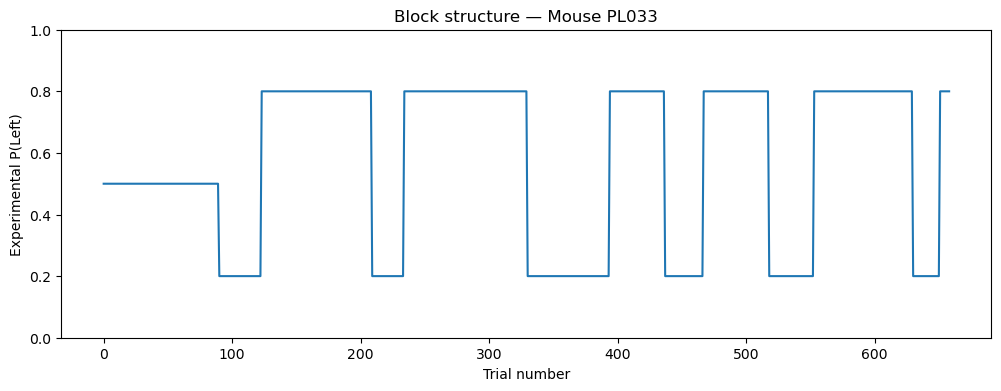

In [33]:
# ============================================================
# STEP 4 — Visualize task prior across the session
# ============================================================

plt.figure(figsize=(12, 4))

plt.plot(
    beh.index,
    beh["probabilityLeft"]
)

plt.xlabel("Trial number")

plt.ylabel(
    "Experimental P(Left)"
)

plt.title(
    f"Block structure — Mouse {example_mouse}"
)

plt.ylim(0, 1)

plt.show()

The session begins with 90 unbiased trials (P(Left) = 0.5) and then alternates between P(Left) = 0.2 and 0.8. Here the blocks last 21 – 96 trials (51 on average; the last block is cut short by the end of the session). Nothing tells the mouse that a block has switched: it can only infer the current block from what happened recently.

### Step 5 — Psychometric curves: does the block prior shift choices?

A psychometric curve shows P(choose right) as a function of the signed contrast. If the mouse uses the prior, the curve should move **up in right-biased blocks** (P(Left) = 0.2) and **down in left-biased blocks** (P(Left) = 0.8) — mainly at low contrast, where the stimulus says little.

For this descriptive analysis we keep only valid trials from the two biased block types (the 90 unbiased trials are left out).

In [34]:
# ============================================================
# STEP 5 — Convert choice to a binary Right-choice variable
# ============================================================

# In IBL data, choice = -1 is a Right choice and +1 a Left
# choice (verified on correct trials in Step 4).
beh["chose_right"] = (
    beh["choice"] == -1
).astype(int)

print("Raw choice counts:")
print(
    beh["choice"]
    .value_counts()
    .sort_index()
)

print("\nBinary chose_right counts:")
print(
    beh["chose_right"]
    .value_counts()
    .sort_index()
)

Raw choice counts:
choice
-1.0    398
 1.0    261
Name: count, dtype: int64

Binary chose_right counts:
chose_right
0    261
1    398
Name: count, dtype: int64


In [35]:
# ============================================================
# STEP 5 — Add experimental probability of Right
# ============================================================

beh["probabilityRight"] = (
    1 - beh["probabilityLeft"]
)

print(
    beh[
        ["probabilityLeft", "probabilityRight"]
    ]
    .drop_duplicates()
    .sort_values("probabilityLeft")
)

     probabilityLeft  probabilityRight
90               0.2               0.8
0                0.5               0.5
123              0.8               0.2


In [36]:
# ============================================================
# STEP 5 — Prepare trials for psychometric analysis
# ============================================================

psy = beh[
    beh["valid_trial"]
    &
    beh["probabilityLeft"].isin([0.2, 0.8])
].copy()

print("Total trials in behavioral session:")
print(len(beh))

print("\nTrials used for psychometric analysis:")
print(len(psy))

print("\nTrials by prior block:")
print(
    psy["probabilityLeft"]
    .value_counts()
    .sort_index()
)

Total trials in behavioral session:
659

Trials used for psychometric analysis:
326

Trials by prior block:
probabilityLeft
0.2    101
0.8    225
Name: count, dtype: int64


In [37]:
# ============================================================
# STEP 5 — Compute empirical psychometric data
# ============================================================

psychometric = (
    psy
    .groupby(
        [
            "probabilityLeft",
            "signed_contrast"
        ]
    )
    ["chose_right"]
    .agg(
        p_choose_right="mean",
        n_trials="size"
    )
    .reset_index()
)

display(psychometric)

,probabilityLeft,signed_contrast,p_choose_right,n_trials
0,0.2,-1.0000,0.000000,4
1,0.2,-0.2500,0.250000,4
2,0.2,-0.1250,0.500000,4
3,0.2,-0.0625,1.000000,6
4,0.2,0.0000,0.928571,14
5,0.2,0.0625,1.000000,17
6,0.2,0.1250,1.000000,20
7,0.2,0.2500,1.000000,18
8,0.2,1.0000,1.000000,14
9,0.8,-1.0000,0.000000,52


In [38]:
# ============================================================
# STEP 5 — Add approximate binomial standard error
# ============================================================

psychometric["sem"] = np.sqrt(
    psychometric["p_choose_right"]
    *
    (1 - psychometric["p_choose_right"])
    /
    psychometric["n_trials"]
)

display(psychometric)

,probabilityLeft,signed_contrast,p_choose_right,n_trials,sem
0,0.2,-1.0000,0.000000,4,0.000000
1,0.2,-0.2500,0.250000,4,0.216506
2,0.2,-0.1250,0.500000,4,0.250000
3,0.2,-0.0625,1.000000,6,0.000000
4,0.2,0.0000,0.928571,14,0.068830
5,0.2,0.0625,1.000000,17,0.000000
6,0.2,0.1250,1.000000,20,0.000000
7,0.2,0.2500,1.000000,18,0.000000
8,0.2,1.0000,1.000000,14,0.000000
9,0.8,-1.0000,0.000000,52,0.000000


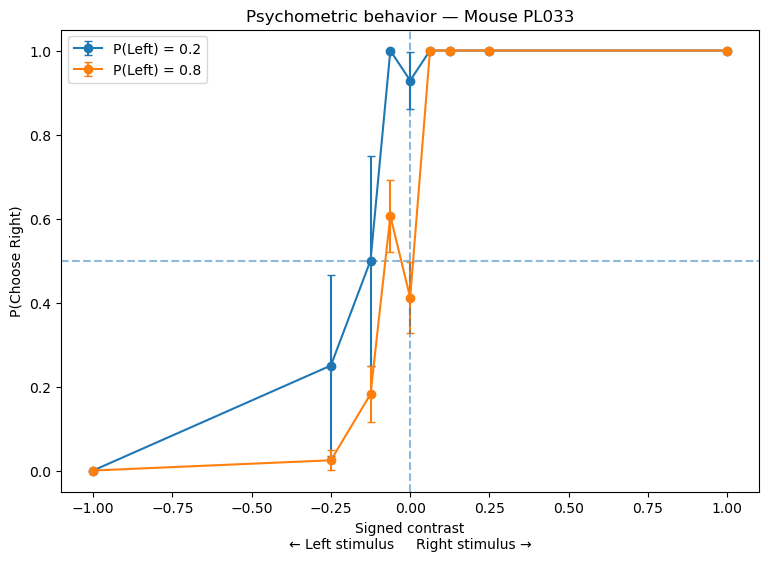

In [39]:
# ============================================================
# STEP 5 — Plot psychometric curves
# ============================================================

plt.figure(figsize=(9, 6))

for p_left in [0.2, 0.8]:

    d = psychometric[
        psychometric["probabilityLeft"] == p_left
    ].sort_values(
        "signed_contrast"
    )

    plt.errorbar(
        d["signed_contrast"],
        d["p_choose_right"],
        yerr=d["sem"],
        marker="o",
        capsize=3,
        label=f"P(Left) = {p_left}"
    )

plt.axvline(
    0,
    linestyle="--",
    alpha=0.5
)

plt.axhline(
    0.5,
    linestyle="--",
    alpha=0.5
)

plt.xlabel(
    "Signed contrast\n"
    "← Left stimulus     Right stimulus →"
)

plt.ylabel(
    "P(Choose Right)"
)

plt.title(
    f"Psychometric behavior — Mouse {example_mouse}"
)

plt.ylim(
    -0.05,
    1.05
)

plt.legend()

plt.show()

**The prior clearly shifts the psychometric curve.** At the same contrast, the mouse chooses right more often in the right-biased block (blue) than in the left-biased block (orange). The difference is largest where vision helps least: at 0 % contrast, P(right) = 0.93 in the right-biased block versus 0.41 in the left-biased block. At high contrast the stimulus dominates and both curves saturate.

Error bars are binomial standard errors; some points in the right-biased block rest on only 4 – 6 trials.

In [40]:
# ============================================================
# STEP 5 — Inspect zero-contrast behavior
# ============================================================

zero_trials = psy[
    psy["signed_contrast"] == 0
].copy()

zero_summary = (
    zero_trials
    .groupby("probabilityLeft")
    ["chose_right"]
    .agg(
        p_choose_right="mean",
        n_trials="size"
    )
)

print("ZERO-CONTRAST BEHAVIOR")

display(zero_summary)

ZERO-CONTRAST BEHAVIOR


,p_choose_right,n_trials
probabilityLeft,,
0.2,0.928571,14
0.8,0.411765,34


In [41]:
# ============================================================
# STEP 5 — Overall choice bias by block
# ============================================================

block_choice_summary = (
    psy
    .groupby("probabilityLeft")
    ["chose_right"]
    .agg(
        p_choose_right="mean",
        n_trials="size"
    )
)

print("Overall Right-choice probability by block:")

display(block_choice_summary)

Overall Right-choice probability by block:


,p_choose_right,n_trials
probabilityLeft,,
0.2,0.900990,101
0.8,0.324444,225


Overall, the mouse chose right on 90 % of trials in the right-biased block and on 32 % in the left-biased block. Part of this gap simply reflects that more right-side stimuli are shown in the right-biased block; the logistic regression below separates the effect of the prior from that of the stimulus.

PL033 also has a general rightward tendency (398 of its 659 choices in this session were rightward), which is why P(right) at 0 % contrast is still 0.41 even when left is the more likely side.

### Step 6 — Quantifying the prior effect with logistic regression

We compare two logistic regression models of P(choose right):

* **Model 0 (stimulus only):** logit P(right) = β₀ + β₁ · c
* **Model 1 (stimulus + prior):** logit P(right) = β₀ + β₁ · c + β₂ · log[P(Right) / P(Left)]

The block log-odds is +1.39 in right-biased and −1.39 in left-biased blocks. If the mouse uses the prior, β₂ should be positive and Model 1 should have a lower AIC.

In [42]:
# ============================================================
# STEP 6 — Build experimental prior predictor
# ============================================================

glm_df = psy.copy()

# Experimental probability of Right
glm_df["probabilityRight"] = (
    1 - glm_df["probabilityLeft"]
)

# Convert probability to log-odds
glm_df["block_logodds_right"] = np.log(
    glm_df["probabilityRight"]
    /
    (1 - glm_df["probabilityRight"])
)

print("Experimental prior coding:")

display(
    glm_df[
        [
            "probabilityLeft",
            "probabilityRight",
            "block_logodds_right"
        ]
    ]
    .drop_duplicates()
    .sort_values("probabilityLeft")
)

Experimental prior coding:


,probabilityLeft,probabilityRight,block_logodds_right
91,0.2,0.8,1.386294
127,0.8,0.2,-1.386294


In [43]:
# ============================================================
# STEP 6 — Statistical modeling library
# ============================================================

import statsmodels.api as sm

In [44]:
# ============================================================
# STEP 6 — MODEL 0: Stimulus-only
# ============================================================

X0 = glm_df[
    ["signed_contrast"]
].copy()

# Add intercept
X0 = sm.add_constant(
    X0,
    has_constant="add"
)

y = glm_df[
    "chose_right"
]

model_stimulus = sm.Logit(
    y,
    X0
).fit()

print(
    model_stimulus.summary()
)

Optimization terminated successfully.
         Current function value: 0.292312
         Iterations 9
                           Logit Regression Results                           
Dep. Variable:            chose_right   No. Observations:                  326
Model:                          Logit   Df Residuals:                      324
Method:                           MLE   Df Model:                            1
Date:                Thu, 20 Aug 2026   Pseudo R-squ.:                  0.5783
Time:                        16:39:47   Log-Likelihood:                -95.294
converged:                       True   LL-Null:                       -225.96
Covariance Type:            nonrobust   LLR p-value:                 8.793e-59
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               1.1002      0.215      5.123      0.000       0.679       1.521
signed_contras

In [45]:
# ============================================================
# STEP 6 — MODEL 1: Stimulus + experimental prior
# ============================================================

X1 = glm_df[
    [
        "signed_contrast",
        "block_logodds_right"
    ]
].copy()

X1 = sm.add_constant(
    X1,
    has_constant="add"
)

model_stimulus_prior = sm.Logit(
    y,
    X1
).fit()

print(
    model_stimulus_prior.summary()
)

Optimization terminated successfully.
         Current function value: 0.259877
         Iterations 9
                           Logit Regression Results                           
Dep. Variable:            chose_right   No. Observations:                  326
Model:                          Logit   Df Residuals:                      323
Method:                           MLE   Df Model:                            2
Date:                Thu, 20 Aug 2026   Pseudo R-squ.:                  0.6251
Time:                        16:39:47   Log-Likelihood:                -84.720
converged:                       True   LL-Null:                       -225.96
Covariance Type:            nonrobust   LLR p-value:                 4.573e-62
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                   1.7834      0.336      5.306      0.000       1.125       2.442
si

In [46]:
# ============================================================
# STEP 6 — Compare models
# ============================================================

stimulus_aic = model_stimulus.aic
prior_aic = model_stimulus_prior.aic

delta_aic = (
    prior_aic - stimulus_aic
)

prior_coef = (
    model_stimulus_prior
    .params["block_logodds_right"]
)

prior_pvalue = (
    model_stimulus_prior
    .pvalues["block_logodds_right"]
)


print("=" * 70)
print("STEP 6 — PRIOR EFFECT MODEL COMPARISON")
print("=" * 70)

print(
    f"Stimulus-only AIC: "
    f"{stimulus_aic:.3f}"
)

print(
    f"Stimulus + prior AIC: "
    f"{prior_aic:.3f}"
)

print(
    f"\nΔAIC (prior - stimulus): "
    f"{delta_aic:.3f}"
)

print(
    f"\nPrior coefficient: "
    f"{prior_coef:.4f}"
)

print(
    f"Prior p-value: "
    f"{prior_pvalue:.6f}"
)

print("=" * 70)

STEP 6 — PRIOR EFFECT MODEL COMPARISON
Stimulus-only AIC: 194.587
Stimulus + prior AIC: 175.439

ΔAIC (prior - stimulus): -19.148

Prior coefficient: 0.8506
Prior p-value: 0.000064


**H1 is supported.** Adding the block prior improves the model substantially (AIC 194.6 → 175.4, **ΔAIC = −19.1**), and its coefficient is positive and highly significant (β₂ = 0.85, p = 6.4 × 10⁻⁵).

*Technical note:* statsmodels warns about quasi-separation because this mouse is almost perfect at high contrast. The contrast slope is therefore poorly determined, but the comparison of the prior term remains informative.

**The catch:** the mouse cannot see `probabilityLeft`. The regression shows that its choices *correlate* with the true block, so the mouse must be **estimating** the block from its own experience. The rest of the notebook models *how* it does so — and how fast.

---

## Part 3 · A generative model of choices

Each choice is described by a two-stage model.

**1. Subjective prior — the action kernel.** Before trial t, the mouse believes that the stimulus will be on the right with probability π(t). After it chooses a(t) (1 = right, 0 = left), the belief moves a fraction α toward that choice:

$$\pi(t+1) = (1-\alpha)\,\pi(t) + \alpha\,a(t), \qquad \pi(1) = 0.5$$

Unrolling the recursion shows that π(t) is an exponentially weighted average of past choices: the choice made k trials back has weight α(1 − α)<sup>k−1</sup>. Writing (1 − α)<sup>k</sup> = e<sup>−k/τ</sup> defines the **updating timescale**

$$\tau = -\frac{1}{\ln(1-\alpha)} \qquad \left(\approx \frac{1}{\alpha} \text{ for small } \alpha\right)$$

which is the number of trials over which the influence of a choice decays by a factor e. A small τ means fast, "forgetful" updating; a large τ means slow, persistent integration.

**2. Perceptual decision — a Bayesian observer with lapses.** The mouse receives a noisy measurement of the signed contrast c (Gaussian noise with standard deviation ζ) and combines it with its prior π(t). Choosing the side with the higher posterior probability gives

$$P_{\text{no lapse}}(\text{right}) = \Phi\!\left(\frac{c}{\zeta} - \frac{\zeta}{\sigma_{\text{post}}}\,\Phi^{-1}\big(1-\pi(t)\big)\right), \qquad \frac{1}{\sigma_{\text{post}}^{2}} = \frac{1}{\sigma^{2}} + \frac{1}{\zeta^{2}}$$

where Φ is the standard normal cumulative distribution function and σ² = 0.24 is the fixed variance of the observer's Gaussian prior over signed contrast. On a fraction λ of trials the mouse *lapses* and guesses at random; λ may differ between right-side (λ<sub>R</sub>) and left-side (λ<sub>L</sub>) stimuli:

$$P(\text{right}) = (1-\lambda)\,P_{\text{no lapse}}(\text{right}) + \frac{\lambda}{2}$$

**Parameters.** α is the parameter of interest. Sensory noise ζ and the lapse rates λ<sub>R</sub> and λ<sub>L</sub> are **nuisance parameters**: they describe how well the mouse sees and how attentive it is on a given day, and they are fitted separately for every session.

---

### Step 7 — The action-kernel prior

Each response is coded as 1 (right), 0 (left) or `NaN` (no response, in which case the prior is left unchanged). The prior stored for trial t uses **only the choices before t**, so it is causal.

In [47]:
# ============================================================
# STEP 7 — Encode actions for the Action Kernel
# ============================================================

beh["action_right"] = np.where(
    beh["choice"] == -1,
    1.0,
    np.where(
        beh["choice"] == 1,
        0.0,
        np.nan
    )
)

print("Action coding:")
print(
    beh[
        ["choice", "action_right"]
    ]
    .drop_duplicates()
    .sort_values("choice")
)

Action coding:
   choice  action_right
1    -1.0           1.0
0     1.0           0.0


In [48]:
# ============================================================
# STEP 7 — Action-kernel subjective prior
# ============================================================

def compute_action_prior(
    actions,
    alpha,
    initial_prior=0.5
):
    """
    Compute a causal subjective prior for Right.

    Parameters
    ----------
    actions : array
        Right = 1
        Left  = 0
        No response = NaN

    alpha : float
        Update rate between 0 and 1.

    initial_prior : float
        Prior at the beginning of the session.

    Returns
    -------
    prior : array
        Subjective prior available BEFORE each trial.
    """

    actions = np.asarray(
        actions,
        dtype=float
    )

    prior = np.zeros(
        len(actions),
        dtype=float
    )

    p = initial_prior

    for t in range(len(actions)):

        # Store prior BEFORE observing action on trial t
        prior[t] = p

        # Update only after the trial
        if not np.isnan(actions[t]):

            p = (
                (1 - alpha) * p
                + alpha * actions[t]
            )

    return prior

In [49]:
# ============================================================
# STEP 7 — Small sanity check of the Action Kernel
# ============================================================

example_actions = np.array(
    [1, 1, 0, 1],
    dtype=float
)

example_prior = compute_action_prior(
    example_actions,
    alpha=0.2,
    initial_prior=0.5
)

print("Actions:")
print(example_actions)

print("\nPrior BEFORE each trial:")
print(example_prior)

Actions:
[1. 1. 0. 1.]

Prior BEFORE each trial:
[0.5   0.6   0.68  0.544]


With α = 0.2 and the choices right, right, left, right, the prior before each trial goes 0.5 → 0.6 → 0.68 → 0.544: each choice pulls the belief 20 % of the way toward itself, and the prior for trial t never depends on choice t.

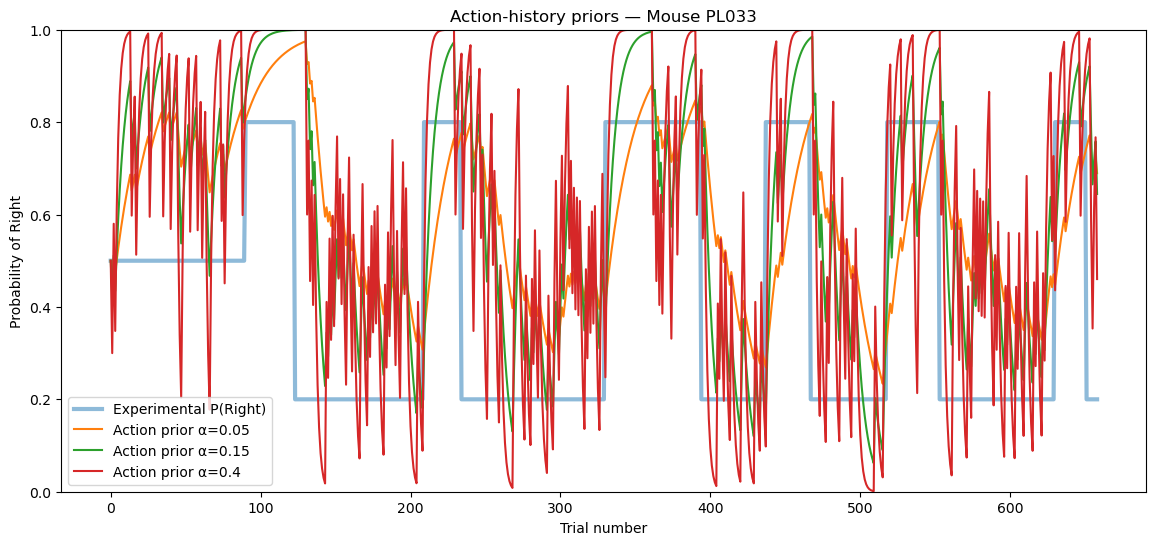

In [50]:
# ============================================================
# STEP 7 — Visualize different update rates
# ============================================================

example_alphas = [
    0.05,
    0.15,
    0.40
]

plt.figure(
    figsize=(14, 6)
)

# Experimental probability of Right
true_prob_right = (
    1 - beh["probabilityLeft"]
)

plt.plot(
    beh.index,
    true_prob_right,
    linewidth=3,
    alpha=0.5,
    label="Experimental P(Right)"
)

for alpha in example_alphas:

    prior = compute_action_prior(
        beh["action_right"].values,
        alpha=alpha,
        initial_prior=0.5
    )

    plt.plot(
        beh.index,
        prior,
        linewidth=1.5,
        label=f"Action prior α={alpha}"
    )

plt.xlabel(
    "Trial number"
)

plt.ylabel(
    "Probability of Right"
)

plt.title(
    f"Action-history priors — Mouse {example_mouse}"
)

plt.ylim(
    0,
    1
)

plt.legend()

plt.show()

**What α does.** The thick line is the true (hidden) P(Right). With a small α (orange, α = 0.05) the prior is smooth but lags behind block switches by tens of trials; with a large α (red, α = 0.4) it reacts within a few trials but jumps after every single choice. The data decide where each mouse sits between these extremes.

The prior follows the mouse's *own* choices. Because choices mostly follow the stimuli, and the stimuli follow the block, this history carries information about the block — but it also inherits the mouse's biases: the early rise toward 1 reflects PL033's many rightward choices during the unbiased block.

In [51]:
# ============================================================
# STEP 7 — Convert alpha to timescale tau
# ============================================================

def alpha_to_tau(alpha):

    return (
        -1 /
        np.log(1 - alpha)
    )


for alpha in example_alphas:

    tau = alpha_to_tau(alpha)

    print(
        f"alpha = {alpha:.2f}"
        f"  -->  tau = {tau:.2f} trials"
    )

alpha = 0.05  -->  tau = 19.50 trials
alpha = 0.15  -->  tau = 6.15 trials
alpha = 0.40  -->  tau = 1.96 trials


Converting α to τ makes the parameter easy to interpret: α = 0.05, 0.15 and 0.40 correspond to memories of about 20, 6 and 2 trials. From here on, results are reported mainly as τ.

### Step 8 — From prior and contrast to a choice probability

`right_choice_probability` implements the observer of Part 3. The observer assumes that signed contrasts come from a zero-mean Gaussian with variance σ² = 0.24 (`SIGMA2`), split between the two sides in proportion to its current prior π(t). Given its noisy measurement, it picks the side with the higher posterior probability; averaging over the measurement noise gives the formula above. In the code, σ<sub>post</sub> is `sigma_star`, and the factor ζ/σ<sub>post</sub> is written as (ζ²/σ² + 1)·σ<sub>post</sub>/ζ, which is algebraically the same.

Lapses are applied last: λ<sub>R</sub> on right-stimulus trials, λ<sub>L</sub> on left-stimulus trials, and their average on 0 % contrast trials.

Two sanity checks follow: with a neutral prior the psychometric curve should be symmetric, and at 0 % contrast the prior alone should determine the choice.

In [52]:
# ============================================================
# STEP 8 — Libraries for the behavioural likelihood model
# ============================================================

from scipy.stats import norm

In [53]:
# ============================================================
# STEP 8 — Probability of choosing Right
# ============================================================

# Variance of the observer's Gaussian prior over signed contrast
# (held fixed; only zeta and the lapse rates are fitted).
SIGMA2 = 0.24


def right_choice_probability(
    signed_contrast,
    prior_right,
    sensory_noise,
    lapse_right_stimulus,
    lapse_left_stimulus
):
    """
    Probability of a Right choice under the
    IBL paper-inspired behavioural model.

    Parameters
    ----------
    signed_contrast : array
        Negative = Left stimulus
        Positive = Right stimulus

    prior_right : array
        Subjective prior probability of Right.

    sensory_noise : float
        zeta; uncertainty in sensory evidence.

    lapse_right_stimulus : float
        Lapse probability for positive/right contrasts.

    lapse_left_stimulus : float
        Lapse probability for negative/left contrasts.
    """

    c = np.asarray(
        signed_contrast,
        dtype=float
    )

    prior = np.clip(
        np.asarray(prior_right, dtype=float),
        1e-6,
        1 - 1e-6
    )

    zeta = sensory_noise

    # Effective sensory uncertainty
    sigma_star = np.sqrt(
        1.0 /
        (
            1.0 / SIGMA2
            +
            1.0 / zeta**2
        )
    )

    # Prior-dependent decision threshold
    prior_threshold = norm.ppf(
        1 - prior
    )

    decision_variable = (
        c / zeta
        -
        (
            (zeta**2 / SIGMA2 + 1)
            *
            (sigma_star / zeta)
            *
            prior_threshold
        )
    )

    # Right-choice probability before lapses
    p_right_no_lapse = norm.cdf(
        decision_variable
    )

    # Stimulus-side-dependent lapse
    lapse = np.where(
        c > 0,
        lapse_right_stimulus,
        np.where(
            c < 0,
            lapse_left_stimulus,
            0.5 * (
                lapse_right_stimulus
                +
                lapse_left_stimulus
            )
        )
    )

    # During a lapse, choose randomly
    p_right = (
        p_right_no_lapse
        * (1 - lapse)
        +
        0.5 * lapse
    )

    return np.clip(
        p_right,
        1e-8,
        1 - 1e-8
    )

In [54]:
# ============================================================
# STEP 8 — Sanity check of the decision model
# ============================================================

test_contrasts = np.array([
    -1.0,
    -0.25,
    0.0,
    0.25,
    1.0
])

test_prior = np.full(
    len(test_contrasts),
    0.5
)

test_p_right = right_choice_probability(
    signed_contrast=test_contrasts,
    prior_right=test_prior,
    sensory_noise=0.1,
    lapse_right_stimulus=0.02,
    lapse_left_stimulus=0.02
)

print("Contrast   P(Right)")

for c, p in zip(
    test_contrasts,
    test_p_right
):

    print(
        f"{c:>7.2f}    {p:.3f}"
    )

Contrast   P(Right)
  -1.00    0.010
  -0.25    0.016
   0.00    0.500
   0.25    0.984
   1.00    0.990


In [55]:
# ============================================================
# STEP 8 — Sanity check: effect of prior
# ============================================================

test_priors = np.array([
    0.2,
    0.35,
    0.5,
    0.65,
    0.8
])

zero_contrasts = np.zeros(
    len(test_priors)
)

prior_test_p_right = right_choice_probability(
    signed_contrast=zero_contrasts,
    prior_right=test_priors,
    sensory_noise=0.1,
    lapse_right_stimulus=0.02,
    lapse_left_stimulus=0.02
)

print("PriorRight   P(Right)")

for prior, p in zip(
    test_priors,
    prior_test_p_right
):

    print(
        f"{prior:>8.2f}    {p:.3f}"
    )

PriorRight   P(Right)
    0.20    0.201
    0.35    0.350
    0.50    0.500
    0.65    0.650
    0.80    0.799


Both checks behave as expected:

* With a neutral prior the curve is symmetric around 0 and saturates at λ/2 = 0.01 and 1 − λ/2 = 0.99.
* At 0 % contrast the predicted P(right) is almost exactly the prior itself (0.20 → 0.201, 0.80 → 0.799). This follows from the formula: with c = 0 and small sensory noise (ζ/σ<sub>post</sub> ≈ 1), P(right) ≈ Φ(Φ⁻¹(π)) = π. The observer therefore **probability-matches** on trials without visual evidence — exactly where the block prior had its largest effect in Step 5.

### Step 9 — Likelihood of the observed choices

For a given set of parameters, the **negative log-likelihood** (NLL) of a session is

$$\text{NLL} = -\sum_{t} \log P\big(\text{observed choice on trial } t\big)$$

summed over the trials that pass the mask and have a left or right response. Two details matter:

1. The prior is computed from **all** trials in chronological order (including masked ones), because the mouse experienced all of them; only the likelihood is restricted to valid trials.
2. Parameters outside their allowed range return an infinite NLL: 0.001 ≤ α ≤ 0.95, 0.005 ≤ ζ ≤ 1 and 0 ≤ λ ≤ 0.5.

A lower NLL means a better fit.

In [56]:
# ============================================================
# STEP 9 — Negative log-likelihood for one session
# ============================================================

def session_negative_loglik(
    params,
    session_df
):
    """
    Negative log-likelihood of observed choices
    for one behavioral session.

    Parameters
    ----------
    params :
        [alpha,
         sensory_noise,
         lapse_right_stimulus,
         lapse_left_stimulus]

    session_df :
        Behavioral DataFrame in chronological order.
    """

    alpha, sensory_noise, lapse_r, lapse_l = params

    # --------------------------------------------------------
    # 1. Reject impossible parameter values
    # --------------------------------------------------------

    if not (
        0.001 <= alpha <= 0.95
        and 0.005 <= sensory_noise <= 1.0
        and 0.0 <= lapse_r <= 0.5
        and 0.0 <= lapse_l <= 0.5
    ):
        return np.inf

    # --------------------------------------------------------
    # 2. Build subjective prior from ALL chronological actions
    # --------------------------------------------------------

    prior_right = compute_action_prior(
        session_df["action_right"].values,
        alpha=alpha,
        initial_prior=0.5
    )

    # --------------------------------------------------------
    # 3. Decide which trials enter the likelihood
    # --------------------------------------------------------

    keep = (
        session_df["valid_trial"]
        &
        session_df["choice"].isin([-1, 1])
    )

    # --------------------------------------------------------
    # 4. Extract sensory evidence and observed choices
    # --------------------------------------------------------

    contrast = session_df.loc[
        keep,
        "signed_contrast"
    ].values

    observed_right = session_df.loc[
        keep,
        "chose_right"
    ].values

    prior_kept = prior_right[
        keep.to_numpy()
    ]

    # --------------------------------------------------------
    # 5. Model probability of a Right choice
    # --------------------------------------------------------

    p_right = right_choice_probability(
        signed_contrast=contrast,
        prior_right=prior_kept,
        sensory_noise=sensory_noise,
        lapse_right_stimulus=lapse_r,
        lapse_left_stimulus=lapse_l
    )

    # --------------------------------------------------------
    # 6. Probability of the choice that was ACTUALLY observed
    # --------------------------------------------------------

    p_observed = np.where(
        observed_right == 1,
        p_right,
        1 - p_right
    )

    p_observed = np.clip(
        p_observed,
        1e-12,
        1.0
    )

    # --------------------------------------------------------
    # 7. Negative log-likelihood
    # --------------------------------------------------------

    nll = -np.sum(
        np.log(p_observed)
    )

    return nll

In [57]:
# ============================================================
# STEP 9 — Manually compare a few parameter sets
# ============================================================

test_parameter_sets = [
    [0.05, 0.10, 0.02, 0.02],
    [0.15, 0.10, 0.02, 0.02],
    [0.40, 0.10, 0.02, 0.02],
]

for params in test_parameter_sets:

    nll = session_negative_loglik(
        params,
        beh
    )

    print(
        f"alpha={params[0]:.2f}, "
        f"zeta={params[1]:.2f}, "
        f"lapses=({params[2]:.2f},{params[3]:.2f}) "
        f"--> NLL={nll:.3f}"
    )

alpha=0.05, zeta=0.10, lapses=(0.02,0.02) --> NLL=114.792
alpha=0.15, zeta=0.10, lapses=(0.02,0.02) --> NLL=116.550
alpha=0.40, zeta=0.10, lapses=(0.02,0.02) --> NLL=136.181


With the nuisance parameters fixed at plausible values, α = 0.05 fits this session slightly better than α = 0.15, and α = 0.40 is clearly worse. A fair comparison between α values, however, requires the nuisance parameters to be **re-optimized for every α**; otherwise we would partly be comparing badly chosen noise and lapse values.

**Profile likelihood.** For a fixed α, the NLL is minimized over the three nuisance parameters (ζ, λ<sub>R</sub>, λ<sub>L</sub>) with bounded L-BFGS-B, starting from five different points to avoid poor local minima. Repeating this over many α values gives the **profile likelihood** of α: the best fit that can be achieved at each α.

In [58]:
# ============================================================
# STEP 9 — Optimization tools
# ============================================================

from scipy.optimize import minimize

In [59]:
# ============================================================
# STEP 9 — Optimize nuisance parameters for fixed alpha
# ============================================================

nuisance_bounds = [
    (0.005, 1.0),   # sensory noise
    (0.0, 0.5),     # lapse on Right-stimulus trials
    (0.0, 0.5),     # lapse on Left-stimulus trials
]


def optimize_nuisance_given_alpha(
    session_df,
    alpha
):
    """
    For a fixed alpha, find the nuisance parameters
    that minimize the session negative log-likelihood.

    Multiple starting points are used for robustness.
    """

    starting_points = [
        [0.05, 0.02, 0.02],
        [0.10, 0.05, 0.05],
        [0.20, 0.10, 0.10],
        [0.05, 0.15, 0.02],
        [0.05, 0.02, 0.15],
    ]

    best_result = None

    def objective(nuisance):

        sensory_noise, lapse_r, lapse_l = nuisance

        params = [
            alpha,
            sensory_noise,
            lapse_r,
            lapse_l
        ]

        return session_negative_loglik(
            params,
            session_df
        )

    for start in starting_points:

        result = minimize(
            objective,
            x0=start,
            method="L-BFGS-B",
            bounds=nuisance_bounds
        )

        if (
            result.success
            and np.isfinite(result.fun)
        ):

            if (
                best_result is None
                or result.fun < best_result.fun
            ):
                best_result = result

    return best_result

In [60]:
# ============================================================
# STEP 9 — Test nuisance optimization at alpha = 0.15
# ============================================================

test_alpha = 0.15

test_fit = optimize_nuisance_given_alpha(
    beh,
    test_alpha
)

print("Optimization successful:")
print(test_fit.success)

print("\nFixed alpha:")
print(test_alpha)

print("\nBest nuisance parameters:")
print(
    "sensory noise =",
    test_fit.x[0]
)

print(
    "Right-stimulus lapse =",
    test_fit.x[1]
)

print(
    "Left-stimulus lapse =",
    test_fit.x[2]
)

print("\nNLL:")
print(test_fit.fun)

Optimization successful:
True

Fixed alpha:
0.15

Best nuisance parameters:
sensory noise = 0.0844728849574913
Right-stimulus lapse = 0.0
Left-stimulus lapse = 0.12522616352697424

NLL:
112.7849737926174


At α = 0.15, optimizing the nuisance parameters lowers the NLL from 116.6 (hand-picked values) to 112.8. The fitted lapses are strongly asymmetric (λ<sub>R</sub> ≈ 0, λ<sub>L</sub> ≈ 0.13): random guesses on left-stimulus trials produce extra rightward errors, in line with this mouse's rightward tendency.

---

## Part 4 · How well can α be estimated? One mouse in depth

### Step 10 — Profile likelihood for a single session

The profile NLL is evaluated at 80 values of α between 0.02 and 0.50. Besides the best α, the profile shows how **precisely** α is determined. By Wilks' theorem, an approximate 95 % confidence interval contains every α whose profile NLL lies within

$$\Delta\text{NLL} \le \tfrac{1}{2}\,\chi^2_{1,\;0.95} = 3.84 / 2 = 1.92$$

of the minimum (`PROFILE_THRESHOLD = 1.9207`). Because τ decreases as α increases, the τ interval is obtained by transforming the two α limits.

In [61]:
# ============================================================
# STEP 10 — Build a profile likelihood over alpha
# ============================================================

alpha_grid = np.linspace(
    0.02,
    0.50,
    80
)

print("Number of alpha values:")
print(len(alpha_grid))

print("\nFirst five:")
print(alpha_grid[:5])

print("\nLast five:")
print(alpha_grid[-5:])

Number of alpha values:
80

First five:
[0.02       0.02607595 0.0321519  0.03822785 0.0443038 ]

Last five:
[0.4756962  0.48177215 0.4878481  0.49392405 0.5       ]


In [62]:
# ============================================================
# STEP 10 — Compute the profile likelihood
# ============================================================

profile_nll = []

profile_nuisance = []

for i, alpha in enumerate(alpha_grid):

    result = optimize_nuisance_given_alpha(
        beh,
        alpha
    )

    if result is None:

        profile_nll.append(np.nan)
        profile_nuisance.append(
            [np.nan, np.nan, np.nan]
        )

    else:

        profile_nll.append(
            result.fun
        )

        profile_nuisance.append(
            result.x
        )

    if (i + 1) % 10 == 0:

        print(
            f"Completed "
            f"{i+1}/{len(alpha_grid)}"
        )


profile_nll = np.asarray(
    profile_nll
)

profile_nuisance = np.asarray(
    profile_nuisance
)

print("\nProfile calculation finished.")

Completed 10/80
Completed 20/80
Completed 30/80
Completed 40/80
Completed 50/80
Completed 60/80
Completed 70/80
Completed 80/80

Profile calculation finished.


In [63]:
# ============================================================
# STEP 10 — Find the best alpha
# ============================================================

valid = np.isfinite(
    profile_nll
)

best_index = np.nanargmin(
    profile_nll
)

best_alpha_session = (
    alpha_grid[best_index]
)

best_nll_session = (
    profile_nll[best_index]
)

best_tau_session = alpha_to_tau(
    best_alpha_session
)

best_nuisance_session = (
    profile_nuisance[best_index]
)


print("=" * 70)
print("SESSION-LEVEL PROFILE FIT")
print("=" * 70)

print(
    f"\nExample mouse: "
    f"{example_mouse}"
)

print(
    f"Session date: "
    f"{example_date}"
)

print(
    f"\nBest alpha: "
    f"{best_alpha_session:.4f}"
)

print(
    f"Corresponding tau: "
    f"{best_tau_session:.3f} trials"
)

print(
    f"Best NLL: "
    f"{best_nll_session:.3f}"
)

print("\nNuisance parameters at optimum:")

print(
    f"Sensory noise: "
    f"{best_nuisance_session[0]:.4f}"
)

print(
    f"Right-stimulus lapse: "
    f"{best_nuisance_session[1]:.4f}"
)

print(
    f"Left-stimulus lapse: "
    f"{best_nuisance_session[2]:.4f}"
)

SESSION-LEVEL PROFILE FIT

Example mouse: PL033
Session date: 2022-10-04

Best alpha: 0.0868
Corresponding tau: 11.008 trials
Best NLL: 111.538

Nuisance parameters at optimum:
Sensory noise: 0.0949
Right-stimulus lapse: 0.0000
Left-stimulus lapse: 0.0830


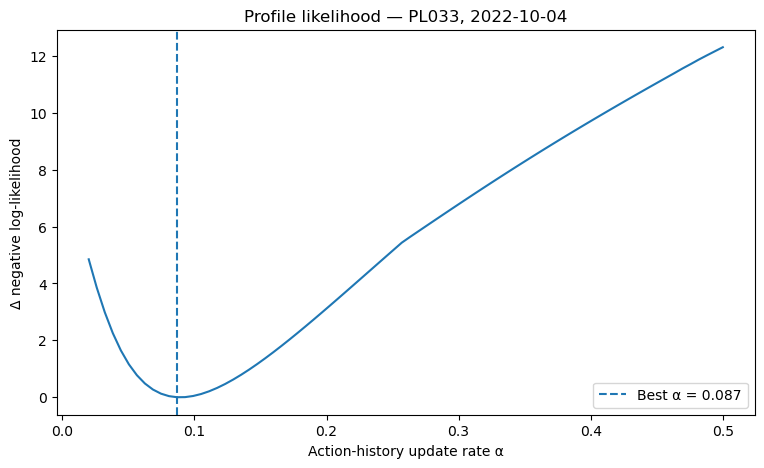

In [64]:
# ============================================================
# STEP 10 — Plot alpha profile likelihood
# ============================================================

delta_nll = (
    profile_nll
    - np.nanmin(profile_nll)
)

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    alpha_grid,
    delta_nll
)

plt.axvline(
    best_alpha_session,
    linestyle="--",
    label=(
        f"Best α = "
        f"{best_alpha_session:.3f}"
    )
)

plt.xlabel(
    "Action-history update rate α"
)

plt.ylabel(
    "Δ negative log-likelihood"
)

plt.title(
    f"Profile likelihood — "
    f"{example_mouse}, {example_date}"
)

plt.legend()

plt.show()

In [65]:
# ============================================================
# STEP 10 — Approximate 95% profile-likelihood interval
# ============================================================

# Likelihood-ratio cut-off on the NLL scale:
# 95% quantile of chi2(df=1) / 2 = 3.8415 / 2
PROFILE_THRESHOLD = 1.9207

inside_interval = (
    delta_nll
    <= PROFILE_THRESHOLD
)

alpha_inside = (
    alpha_grid[inside_interval]
)

if len(alpha_inside) > 0:

    alpha_ci_low = (
        alpha_inside.min()
    )

    alpha_ci_high = (
        alpha_inside.max()
    )

    tau_at_alpha_low = (
        alpha_to_tau(alpha_ci_low)
    )

    tau_at_alpha_high = (
        alpha_to_tau(alpha_ci_high)
    )

    # alpha and tau move in opposite directions
    tau_ci_low = min(
        tau_at_alpha_low,
        tau_at_alpha_high
    )

    tau_ci_high = max(
        tau_at_alpha_low,
        tau_at_alpha_high
    )

    print("=" * 70)
    print("APPROXIMATE 95% PROFILE INTERVAL")
    print("=" * 70)

    print(
        f"\nAlpha estimate: "
        f"{best_alpha_session:.4f}"
    )

    print(
        f"Alpha interval: "
        f"[{alpha_ci_low:.4f}, "
        f"{alpha_ci_high:.4f}]"
    )

    print(
        f"\nTau estimate: "
        f"{best_tau_session:.3f} trials"
    )

    print(
        f"Tau interval: "
        f"[{tau_ci_low:.3f}, "
        f"{tau_ci_high:.3f}] trials"
    )

APPROXIMATE 95% PROFILE INTERVAL

Alpha estimate: 0.0868
Alpha interval: [0.0443, 0.1658]

Tau estimate: 11.008 trials
Tau interval: [5.515, 22.068] trials


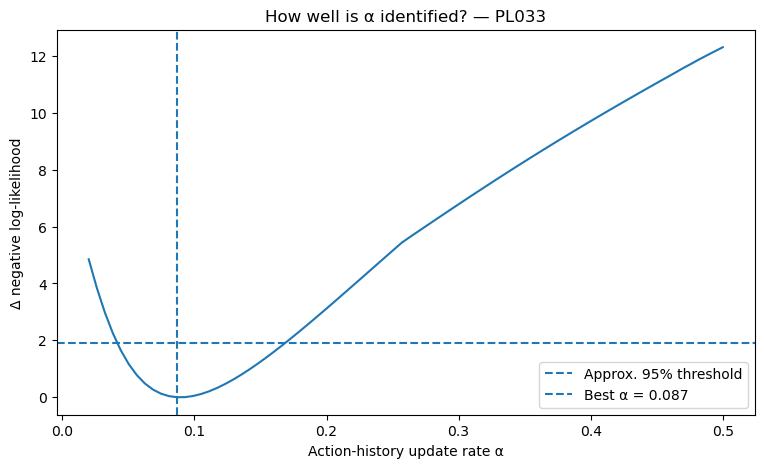

In [66]:
# ============================================================
# STEP 10 — Profile likelihood with uncertainty threshold
# ============================================================

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    alpha_grid,
    delta_nll
)

plt.axhline(
    PROFILE_THRESHOLD,
    linestyle="--",
    label="Approx. 95% threshold"
)

plt.axvline(
    best_alpha_session,
    linestyle="--",
    label=(
        f"Best α = "
        f"{best_alpha_session:.3f}"
    )
)

plt.xlabel(
    "Action-history update rate α"
)

plt.ylabel(
    "Δ negative log-likelihood"
)

plt.title(
    f"How well is α identified? — "
    f"{example_mouse}"
)

plt.legend()

plt.show()

**Result for one session.** The profile has a clear minimum at α = 0.087 (τ = 11.0 trials), but the 95 % interval is wide: α from 0.044 to 0.166, i.e. **τ from 5.5 to 22 trials**. A single session (375 valid trials) is not enough to pin down the timescale, which motivates pooling all sessions of the mouse.

The small kink near α ≈ 0.26 comes from the inner optimization of the nuisance parameters; it lies far outside the interval and does not affect the estimate.

### Step 11 — Load all 13 sessions of PL033

`prepare_behavior_session` packages the pre-processing of Steps 3 – 5 so that it can be applied to any session: signed contrast, `chose_right` and `action_right` (1 = right, 0 = left, `NaN` = no response), the validity mask and a within-session trial counter. As before, no trial is deleted.

In [67]:
# ============================================================
# STEP 11 — Standard preprocessing for one behavioral session
# ============================================================

def prepare_behavior_session(
    one,
    eid,
    date=None
):
    """
    Load and prepare one IBL behavioral session.

    This function:
    1. loads trials and the BWM quality mask,
    2. preserves chronological trial order,
    3. creates signed contrast,
    4. converts raw choices into model-friendly variables,
    5. stores the BWM validity mask.

    No trials are deleted here.
    """

    # --------------------------------------------------------
    # Load raw behavioral data
    # --------------------------------------------------------

    trials_i, mask_i = load_trials_and_mask(
        one,
        eid,
        min_rt=0.08,
        max_rt=2.0,
        nan_exclude="default"
    )

    df = trials_i.copy()

    # --------------------------------------------------------
    # Metadata
    # --------------------------------------------------------

    df["eid"] = str(eid)

    if date is not None:
        df["date"] = date

    df["trial_in_session"] = np.arange(
        len(df)
    )

    # --------------------------------------------------------
    # Signed sensory contrast
    #
    # negative = Left stimulus
    # positive = Right stimulus
    # --------------------------------------------------------

    df["signed_contrast"] = (
        df["contrastRight"].fillna(0)
        -
        df["contrastLeft"].fillna(0)
    )

    # --------------------------------------------------------
    # Action coding for the Action Kernel
    #
    # Right = 1
    # Left  = 0
    # No response = NaN
    # --------------------------------------------------------

    df["action_right"] = np.where(
        df["choice"] == -1,
        1.0,
        np.where(
            df["choice"] == 1,
            0.0,
            np.nan
        )
    )

    # --------------------------------------------------------
    # Choice variable to be predicted
    #
    # Right = 1
    # Left  = 0
    # No response = NaN
    # --------------------------------------------------------

    df["chose_right"] = np.where(
        df["choice"] == -1,
        1.0,
        np.where(
            df["choice"] == 1,
            0.0,
            np.nan
        )
    )

    # --------------------------------------------------------
    # BWM quality-control mask
    # --------------------------------------------------------

    df["valid_trial"] = mask_i

    return df

In [68]:
# ============================================================
# STEP 11 — Load ALL sessions for the example mouse
# ============================================================

mouse_id = example_mouse

mouse_session_data = []

session_audit_rows = []


for i, row in example_sessions.iterrows():

    eid_i = row["eid"]
    date_i = row["date"]

    print(
        f"Loading session "
        f"{i+1}/{len(example_sessions)} "
        f"| date = {date_i}"
    )

    df_i = prepare_behavior_session(
        one,
        eid_i,
        date=date_i
    )

    mouse_session_data.append(
        df_i
    )

    # Trials that can enter the likelihood
    valid_response = (
        df_i["valid_trial"]
        &
        df_i["choice"].isin([-1, 1])
    )

    # Number of contiguous blocks
    n_blocks = (
        df_i["probabilityLeft"]
        .ne(
            df_i["probabilityLeft"].shift()
        )
        .sum()
    )

    session_audit_rows.append(
        {
            "date": date_i,
            "eid": str(eid_i),

            "n_trials":
                len(df_i),

            "n_valid_trials":
                int(valid_response.sum()),

            "valid_fraction":
                valid_response.mean(),

            "n_left_choices":
                int(
                    (df_i["choice"] == 1).sum()
                ),

            "n_right_choices":
                int(
                    (df_i["choice"] == -1).sum()
                ),

            "n_no_response":
                int(
                    (~df_i["choice"].isin([-1, 1])).sum()
                ),

            "n_blocks":
                int(n_blocks),

            "n_zero_contrast":
                int(
                    (
                        df_i["signed_contrast"] == 0
                    ).sum()
                )
        }
    )


session_audit = pd.DataFrame(
    session_audit_rows
)

Loading session 1/13 | date = 2022-10-04
Loading session 2/13 | date = 2022-10-05
Loading session 3/13 | date = 2022-10-06
Loading session 4/13 | date = 2022-10-07
Loading session 5/13 | date = 2022-10-10
Loading session 6/13 | date = 2022-10-11
Loading session 7/13 | date = 2022-10-12
Loading session 8/13 | date = 2022-10-25
Loading session 9/13 | date = 2022-10-26
Loading session 10/13 | date = 2022-10-28
Loading session 11/13 | date = 2022-10-29
Loading session 12/13 | date = 2022-11-02
Loading session 13/13 | date = 2022-11-03


In [69]:
# ============================================================
# STEP 11 — Inspect all sessions of PL033
# ============================================================

display(
    session_audit
)

,date,eid,n_trials,n_valid_trials,valid_fraction,n_left_choices,n_right_choices,n_no_response,n_blocks,n_zero_contrast
0,2022-10-04,62902992-8432-46fb-af12-6392012e58c7,659,375,0.569044,261,398,0,13,80
1,2022-10-05,4546cd60-fa2a-4d20-a9b6-d091e01d16f2,550,311,0.565455,229,321,0,10,60
2,2022-10-06,cef05f87-161b-4031-932c-6f47daf89698,586,355,0.605802,253,333,0,11,74
3,2022-10-07,75db708a-9952-4452-a5b1-a851d88f8e28,551,312,0.566243,252,299,0,13,63
4,2022-10-10,7f150b7c-c261-46e6-9edb-cc391c9d9f03,656,341,0.519817,193,463,0,13,83
5,2022-10-11,837b4e6a-ccfd-49b0-a1dd-3aa53fbf2ecb,560,345,0.616071,153,407,0,12,61
6,2022-10-12,9fc31d79-b56f-46d0-92a0-e9563caf4a7a,420,283,0.673810,170,249,1,6,52
7,2022-10-25,a34b4013-414b-42ed-9318-e93fbbc71e7b,711,267,0.375527,246,465,0,13,62
8,2022-10-26,49250fba-801c-4867-a0a7-a1e19538cb61,678,378,0.557522,322,356,0,14,84
9,2022-10-28,2ab7d2c2-bcb7-4ae6-9626-f3786c22d970,591,311,0.526227,232,358,1,11,65


In [70]:
# ============================================================
# STEP 11 — Multi-session audit summary
# ============================================================

print("=" * 70)
print("STEP 11 — MULTI-SESSION AUDIT")
print("=" * 70)

print(
    f"\nMouse: {mouse_id}"
)

print(
    f"Number of loaded sessions: "
    f"{len(mouse_session_data)}"
)

print(
    f"\nTotal trials across sessions: "
    f"{session_audit['n_trials'].sum()}"
)

print(
    f"Total valid trials: "
    f"{session_audit['n_valid_trials'].sum()}"
)

print(
    f"\nMedian trials per session: "
    f"{session_audit['n_trials'].median():.1f}"
)

print(
    f"Median valid fraction: "
    f"{session_audit['valid_fraction'].median():.3f}"
)

print(
    f"\nMinimum valid trials in one session: "
    f"{session_audit['n_valid_trials'].min()}"
)

print(
    f"Maximum valid trials in one session: "
    f"{session_audit['n_valid_trials'].max()}"
)

print("=" * 70)

STEP 11 — MULTI-SESSION AUDIT

Mouse: PL033
Number of loaded sessions: 13

Total trials across sessions: 7501
Total valid trials: 4233

Median trials per session: 586.0
Median valid fraction: 0.569

Minimum valid trials in one session: 258
Maximum valid trials in one session: 381


PL033 contributes **7,501 trials**, of which **4,233** enter the likelihood (median 57 % per session). One session (25 October 2022) keeps only 38 % of its trials, trials without a response are rare (at most one per session), and each session contains 6 – 14 blocks, counting the unbiased start.

### Step 12 — One α shared across sessions

We now assume that the **updating timescale is a property of the mouse**, while sensory noise and lapse rates may change from day to day (motivation, satiety, rig). The mouse-level profile NLL is the sum over sessions s = 1, …, S of each session's NLL, minimized over that session's own nuisance parameters at the shared α:

$$\text{NLL}^{\text{mouse}}(\alpha) = \sum_{s=1}^{S} \; \min_{\zeta,\, \lambda_R,\, \lambda_L} \text{NLL}^{(s)}(\alpha, \zeta, \lambda_R, \lambda_L)$$

The model has 1 shared parameter plus 3 per session, i.e. 40 parameters for 13 sessions.

In [71]:
# ============================================================
# STEP 12 — Mouse-level profile NLL for a shared alpha
# ============================================================

def mouse_profile_nll(
    alpha,
    sessions,
    return_details=False
):
    """
    Compute the mouse-level profile negative log-likelihood
    for one shared alpha across all sessions.

    The update rate alpha is shared across sessions.

    Each session gets its own nuisance parameters:
        sensory noise
        Right-stimulus lapse
        Left-stimulus lapse
    """

    total_nll = 0.0

    session_details = []

    for session_index, session_df in enumerate(sessions):

        result = optimize_nuisance_given_alpha(
            session_df,
            alpha
        )

        # If optimization failed for any session,
        # this alpha cannot be evaluated reliably.
        if result is None:

            if return_details:
                return np.inf, []

            return np.inf

        total_nll += result.fun

        session_details.append(
            {
                "session_index": session_index,
                "date": (
                    session_df["date"].iloc[0]
                    if "date" in session_df.columns
                    else None
                ),
                "nll": result.fun,
                "sensory_noise": result.x[0],
                "lapse_right_stimulus": result.x[1],
                "lapse_left_stimulus": result.x[2]
            }
        )

    if return_details:

        return (
            total_nll,
            pd.DataFrame(session_details)
        )

    return total_nll

In [72]:
# ============================================================
# STEP 12 — Sanity check at a few mouse-level alpha values
# ============================================================

mouse_test_alphas = [
    0.05,
    0.10,
    0.20
]

for alpha in mouse_test_alphas:

    nll = mouse_profile_nll(
        alpha,
        mouse_session_data
    )

    print(
        f"alpha = {alpha:.2f}"
        f"  --> mouse NLL = {nll:.3f}"
    )

alpha = 0.05  --> mouse NLL = 970.128
alpha = 0.10  --> mouse NLL = 955.868
alpha = 0.20  --> mouse NLL = 973.488


In [73]:
# ============================================================
# STEP 12 — Build mouse-level alpha profile
# ============================================================

mouse_alpha_grid = np.linspace(
    0.02,
    0.40,
    60
)

mouse_profile_values = []

for i, alpha in enumerate(mouse_alpha_grid):

    nll = mouse_profile_nll(
        alpha,
        mouse_session_data
    )

    mouse_profile_values.append(
        nll
    )

    if (i + 1) % 10 == 0:

        print(
            f"Completed "
            f"{i+1}/{len(mouse_alpha_grid)}"
        )


mouse_profile_values = np.asarray(
    mouse_profile_values
)

print("\nMouse-level profile finished.")

Completed 10/60
Completed 20/60
Completed 30/60
Completed 40/60
Completed 50/60
Completed 60/60

Mouse-level profile finished.


In [74]:
# ============================================================
# STEP 12 — Best mouse-level alpha and tau
# ============================================================

mouse_best_index = np.nanargmin(
    mouse_profile_values
)

mouse_best_alpha = (
    mouse_alpha_grid[
        mouse_best_index
    ]
)

mouse_best_nll = (
    mouse_profile_values[
        mouse_best_index
    ]
)

mouse_best_tau = alpha_to_tau(
    mouse_best_alpha
)


print("=" * 70)
print("MOUSE-LEVEL ACTION-KERNEL FIT")
print("=" * 70)

print(
    f"\nMouse: {mouse_id}"
)

print(
    f"Number of sessions: "
    f"{len(mouse_session_data)}"
)

print(
    f"\nBest shared alpha: "
    f"{mouse_best_alpha:.4f}"
)

print(
    f"Corresponding tau: "
    f"{mouse_best_tau:.3f} trials"
)

print(
    f"Total profile NLL: "
    f"{mouse_best_nll:.3f}"
)

print("=" * 70)

MOUSE-LEVEL ACTION-KERNEL FIT

Mouse: PL033
Number of sessions: 13

Best shared alpha: 0.1037
Corresponding tau: 9.131 trials
Total profile NLL: 955.799


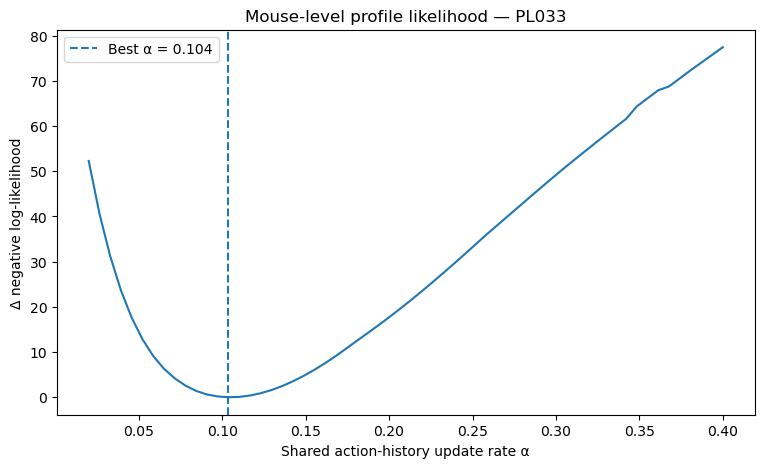

In [75]:
# ============================================================
# STEP 12 — Mouse-level profile likelihood figure
# ============================================================

mouse_delta_nll = (
    mouse_profile_values
    -
    np.nanmin(mouse_profile_values)
)

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    mouse_alpha_grid,
    mouse_delta_nll
)

plt.axvline(
    mouse_best_alpha,
    linestyle="--",
    label=(
        f"Best α = "
        f"{mouse_best_alpha:.3f}"
    )
)

plt.xlabel(
    "Shared action-history update rate α"
)

plt.ylabel(
    "Δ negative log-likelihood"
)

plt.title(
    f"Mouse-level profile likelihood — {mouse_id}"
)

plt.legend()

plt.show()

In [76]:
# ============================================================
# STEP 12 — Approximate mouse-level 95% profile interval
# ============================================================

PROFILE_THRESHOLD = 1.9207

mouse_inside = (
    mouse_delta_nll
    <= PROFILE_THRESHOLD
)

mouse_alpha_inside = (
    mouse_alpha_grid[
        mouse_inside
    ]
)

if len(mouse_alpha_inside) > 0:

    mouse_alpha_ci_low = (
        mouse_alpha_inside.min()
    )

    mouse_alpha_ci_high = (
        mouse_alpha_inside.max()
    )

    tau_a = alpha_to_tau(
        mouse_alpha_ci_low
    )

    tau_b = alpha_to_tau(
        mouse_alpha_ci_high
    )

    mouse_tau_ci_low = min(
        tau_a,
        tau_b
    )

    mouse_tau_ci_high = max(
        tau_a,
        tau_b
    )

    print("=" * 70)
    print("MOUSE-LEVEL PROFILE INTERVAL")
    print("=" * 70)

    print(
        f"\nAlpha estimate: "
        f"{mouse_best_alpha:.4f}"
    )

    print(
        f"Alpha interval: "
        f"[{mouse_alpha_ci_low:.4f}, "
        f"{mouse_alpha_ci_high:.4f}]"
    )

    print(
        f"\nTau estimate: "
        f"{mouse_best_tau:.3f} trials"
    )

    print(
        f"Tau interval: "
        f"[{mouse_tau_ci_low:.3f}, "
        f"{mouse_tau_ci_high:.3f}] trials"
    )

MOUSE-LEVEL PROFILE INTERVAL

Alpha estimate: 0.1037
Alpha interval: [0.0844, 0.1295]

Tau estimate: 9.131 trials
Tau interval: [7.211, 11.340] trials


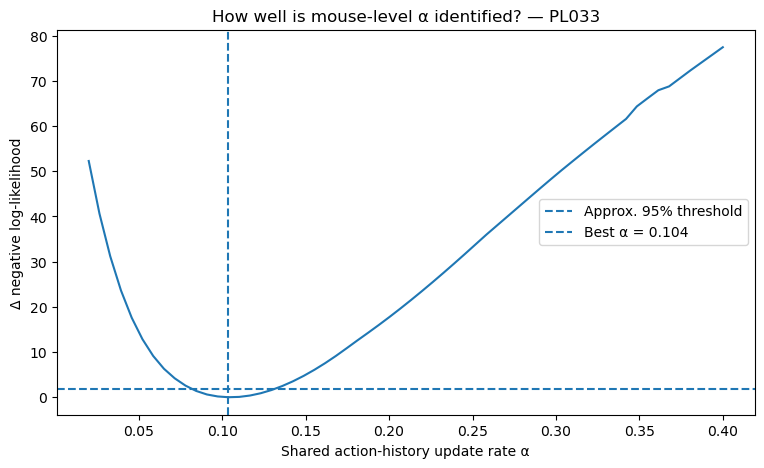

In [77]:
# ============================================================
# STEP 12 — Mouse-level profile with uncertainty threshold
# ============================================================

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    mouse_alpha_grid,
    mouse_delta_nll
)

plt.axhline(
    PROFILE_THRESHOLD,
    linestyle="--",
    label="Approx. 95% threshold"
)

plt.axvline(
    mouse_best_alpha,
    linestyle="--",
    label=(
        f"Best α = "
        f"{mouse_best_alpha:.3f}"
    )
)

plt.xlabel(
    "Shared action-history update rate α"
)

plt.ylabel(
    "Δ negative log-likelihood"
)

plt.title(
    f"How well is mouse-level α identified? — {mouse_id}"
)

plt.legend()

plt.show()

**Pooling sessions sharpens the estimate.** With one α shared across all 13 sessions, the best grid value is α = 0.104 (τ = 9.1 trials) and the 95 % interval is **τ = 7.2 – 11.3 trials** — about four times narrower than from a single session (5.5 – 22.1). The minimum is also much deeper, because a wrong α is now penalized by every session at once.

### Step 13 — Is the update rate stable across sessions? (H2)

Sharing α is only justified if the mouse's timescale does not change much from day to day. This is tested directly:

1. fit a **separate α for every session** (coarse grid of 30 values between 0.01 and 0.50, refined with bounded scalar minimization, plus a profile interval);
2. refine the **shared α** in the same way;
3. compare the two models with AIC: the shared model has 1 + 3 × 13 = 40 parameters, the separate model 4 × 13 = 52.

In [78]:
# ============================================================
# STEP 13 — Profile NLL for one session at a fixed alpha
# ============================================================

def session_profile_nll(
    alpha,
    session_df,
    return_nuisance=False
):
    """
    For a fixed alpha, optimize the nuisance parameters
    of one session and return the best NLL.
    """

    result = optimize_nuisance_given_alpha(
        session_df,
        alpha
    )

    if result is None:

        if return_nuisance:
            return np.inf, None

        return np.inf

    if return_nuisance:

        return (
            result.fun,
            result.x
        )

    return result.fun

In [79]:
# ============================================================
# STEP 13 — Robust fit of alpha for ONE session
# ============================================================

from scipy.optimize import minimize_scalar


def fit_one_session_alpha(
    session_df,
    alpha_min=0.01,
    alpha_max=0.50,
    n_grid=30
):
    """
    Robustly estimate alpha for one session.

    Strategy:
    1. Evaluate a coarse alpha grid.
    2. Find the best grid region.
    3. Refine the minimum locally.
    4. Estimate an approximate profile interval.
    """

    # --------------------------------------------------------
    # 1. Coarse profile
    # --------------------------------------------------------

    grid = np.linspace(
        alpha_min,
        alpha_max,
        n_grid
    )

    nll_values = []

    for alpha in grid:

        nll = session_profile_nll(
            alpha,
            session_df
        )

        nll_values.append(nll)

    nll_values = np.asarray(
        nll_values
    )

    # --------------------------------------------------------
    # 2. Best coarse point
    # --------------------------------------------------------

    best_grid_index = np.nanargmin(
        nll_values
    )

    # --------------------------------------------------------
    # 3. Define local interval around coarse minimum
    # --------------------------------------------------------

    left_index = max(
        best_grid_index - 1,
        0
    )

    right_index = min(
        best_grid_index + 1,
        len(grid) - 1
    )

    local_low = grid[left_index]
    local_high = grid[right_index]

    # If minimum landed exactly on an edge,
    # allow the refinement a wider range.
    if best_grid_index == 0:
        local_low = alpha_min
        local_high = grid[1]

    if best_grid_index == len(grid) - 1:
        local_low = grid[-2]
        local_high = alpha_max

    # --------------------------------------------------------
    # 4. Refine alpha continuously
    # --------------------------------------------------------

    refined = minimize_scalar(
        lambda a: session_profile_nll(
            a,
            session_df
        ),
        bounds=(
            local_low,
            local_high
        ),
        method="bounded",
        options={
            "xatol": 1e-4
        }
    )

    best_alpha = refined.x
    best_nll = refined.fun

    best_tau = alpha_to_tau(
        best_alpha
    )

    # --------------------------------------------------------
    # 5. Get nuisance parameters at final alpha
    # --------------------------------------------------------

    _, nuisance = session_profile_nll(
        best_alpha,
        session_df,
        return_nuisance=True
    )

    # --------------------------------------------------------
    # 6. Approximate profile interval from coarse grid
    # --------------------------------------------------------

    delta = (
        nll_values
        - np.nanmin(nll_values)
    )

    inside = (
        delta <= 1.9207
    )

    alpha_inside = grid[
        inside
    ]

    if len(alpha_inside) > 0:

        alpha_low = alpha_inside.min()
        alpha_high = alpha_inside.max()

        tau_a = alpha_to_tau(
            alpha_low
        )

        tau_b = alpha_to_tau(
            alpha_high
        )

        tau_low = min(
            tau_a,
            tau_b
        )

        tau_high = max(
            tau_a,
            tau_b
        )

    else:

        alpha_low = np.nan
        alpha_high = np.nan
        tau_low = np.nan
        tau_high = np.nan

    # --------------------------------------------------------
    # 7. Boundary diagnostic
    # --------------------------------------------------------

    near_boundary = (
        best_alpha <= alpha_min + 0.01
        or
        best_alpha >= alpha_max - 0.01
    )

    return {
        "best_alpha": best_alpha,
        "best_tau": best_tau,
        "best_nll": best_nll,

        "alpha_ci_low": alpha_low,
        "alpha_ci_high": alpha_high,

        "tau_ci_low": tau_low,
        "tau_ci_high": tau_high,

        "sensory_noise": nuisance[0],
        "lapse_right_stimulus": nuisance[1],
        "lapse_left_stimulus": nuisance[2],

        "near_boundary": near_boundary,

        "grid": grid,
        "profile_nll": nll_values
    }

In [80]:
# ============================================================
# STEP 13 — Fit alpha separately for every PL033 session
# ============================================================

session_fit_rows = []

session_fit_objects = []


for i, session_df in enumerate(
    mouse_session_data
):

    date_i = session_df["date"].iloc[0]

    print(
        f"Fitting session "
        f"{i+1}/{len(mouse_session_data)} "
        f"| {date_i}"
    )

    fit_i = fit_one_session_alpha(
        session_df
    )

    session_fit_objects.append(
        fit_i
    )

    valid_response = (
        session_df["valid_trial"]
        &
        session_df["choice"].isin([-1, 1])
    )

    session_fit_rows.append(
        {
            "date": date_i,

            "n_valid_trials":
                int(valid_response.sum()),

            "alpha":
                fit_i["best_alpha"],

            "tau":
                fit_i["best_tau"],

            "alpha_ci_low":
                fit_i["alpha_ci_low"],

            "alpha_ci_high":
                fit_i["alpha_ci_high"],

            "tau_ci_low":
                fit_i["tau_ci_low"],

            "tau_ci_high":
                fit_i["tau_ci_high"],

            "nll":
                fit_i["best_nll"],

            "sensory_noise":
                fit_i["sensory_noise"],

            "lapse_right":
                fit_i["lapse_right_stimulus"],

            "lapse_left":
                fit_i["lapse_left_stimulus"],

            "near_boundary":
                fit_i["near_boundary"]
        }
    )


session_fit_summary = pd.DataFrame(
    session_fit_rows
)

display(
    session_fit_summary
)

Fitting session 1/13 | 2022-10-04
Fitting session 2/13 | 2022-10-05
Fitting session 3/13 | 2022-10-06
Fitting session 4/13 | 2022-10-07
Fitting session 5/13 | 2022-10-10
Fitting session 6/13 | 2022-10-11
Fitting session 7/13 | 2022-10-12
Fitting session 8/13 | 2022-10-25
Fitting session 9/13 | 2022-10-26
Fitting session 10/13 | 2022-10-28
Fitting session 11/13 | 2022-10-29
Fitting session 12/13 | 2022-11-02
Fitting session 13/13 | 2022-11-03


,date,n_valid_trials,alpha,tau,alpha_ci_low,alpha_ci_high,tau_ci_low,tau_ci_high,nll,sensory_noise,lapse_right,lapse_left,near_boundary
0,2022-10-04,375,0.089262,10.695228,0.043793,0.162069,5.655485,22.330914,111.534332,0.094467,0.000000e+00,8.463303e-02,False
1,2022-10-05,311,0.077694,12.364298,0.026897,0.297241,2.834935,36.677215,54.751800,0.039268,0.000000e+00,7.929329e-02,False
2,2022-10-06,355,0.100765,9.415258,0.043793,0.195862,4.587483,22.330914,74.684709,0.057503,0.000000e+00,5.587868e-02,False
3,2022-10-07,312,0.191256,4.710916,0.094483,0.500000,1.442695,10.075672,36.937965,0.027763,0.000000e+00,4.215826e-02,False
4,2022-10-10,341,0.035961,27.304858,0.026897,0.128276,7.284262,36.677215,78.724171,0.074318,0.000000e+00,6.731356e-02,False
5,2022-10-11,345,0.071835,13.414573,0.026897,0.178966,5.071247,36.677215,77.432749,0.090008,1.462843e-02,2.712126e-02,False
6,2022-10-12,283,0.062323,15.540188,0.026897,0.178966,5.071247,36.677215,66.448867,0.061649,1.639640e-08,1.174497e-01,False
7,2022-10-25,267,0.091302,10.444649,0.060690,0.246552,3.532384,15.972056,44.353981,0.079881,0.000000e+00,2.000127e-08,False
8,2022-10-26,378,0.096386,9.866559,0.043793,0.178966,5.071247,22.330914,79.605600,0.051481,0.000000e+00,8.077456e-02,False
9,2022-10-28,311,0.164119,5.578207,0.077586,0.297241,2.834935,12.382160,77.109809,0.066367,0.000000e+00,1.329713e-01,False


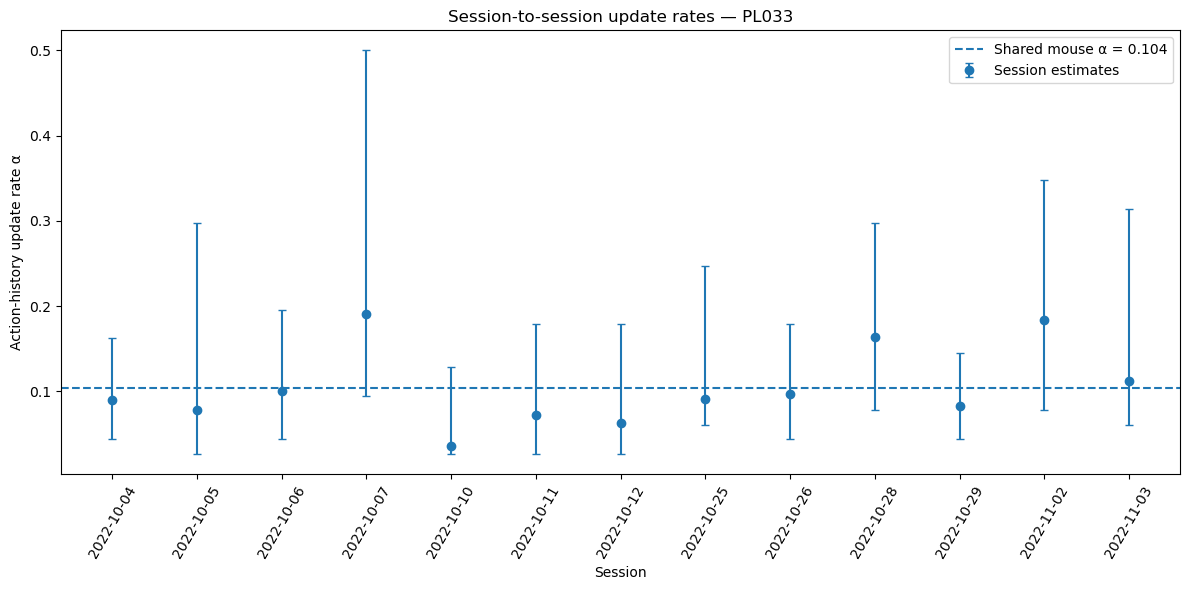

In [81]:
# ============================================================
# STEP 13 — Visualize session-to-session alpha variability
# ============================================================

x = np.arange(
    len(session_fit_summary)
)

alpha_est = (
    session_fit_summary["alpha"].values
)

alpha_low = (
    session_fit_summary["alpha_ci_low"].values
)

alpha_high = (
    session_fit_summary["alpha_ci_high"].values
)

lower_error = (
    alpha_est - alpha_low
)

upper_error = (
    alpha_high - alpha_est
)


plt.figure(
    figsize=(12, 6)
)

plt.errorbar(
    x,
    alpha_est,
    yerr=[
        lower_error,
        upper_error
    ],
    marker="o",
    linestyle="none",
    capsize=3,
    label="Session estimates"
)

plt.axhline(
    mouse_best_alpha,
    linestyle="--",
    label=(
        f"Shared mouse α = "
        f"{mouse_best_alpha:.3f}"
    )
)

plt.xticks(
    x,
    session_fit_summary["date"].astype(str),
    rotation=60
)

plt.xlabel(
    "Session"
)

plt.ylabel(
    "Action-history update rate α"
)

plt.title(
    f"Session-to-session update rates — {mouse_id}"
)

plt.legend()

plt.tight_layout()

plt.show()

The session-by-session estimates range from α = 0.036 to 0.19 (τ ≈ 5 – 27 trials), but their intervals are wide and **all 13 intervals contain the shared value** (dashed line). The scatter is what estimation noise around one common rate would produce.

In [82]:
# ============================================================
# STEP 13 — Refine the shared mouse alpha
# ============================================================

left_index = max(
    mouse_best_index - 1,
    0
)

right_index = min(
    mouse_best_index + 1,
    len(mouse_alpha_grid) - 1
)

shared_refined = minimize_scalar(
    lambda a: mouse_profile_nll(
        a,
        mouse_session_data
    ),
    bounds=(
        mouse_alpha_grid[left_index],
        mouse_alpha_grid[right_index]
    ),
    method="bounded",
    options={
        "xatol": 1e-4
    }
)

refined_shared_alpha = (
    shared_refined.x
)

refined_shared_tau = alpha_to_tau(
    refined_shared_alpha
)

refined_shared_nll = (
    shared_refined.fun
)


print(
    "Refined shared alpha:",
    refined_shared_alpha
)

print(
    "Refined shared tau:",
    refined_shared_tau
)

print(
    "Refined shared NLL:",
    refined_shared_nll
)

Refined shared alpha: 0.10497537862878854
Refined shared tau: 9.016803168296732
Refined shared NLL: 955.7949967622387


In [83]:
# ============================================================
# STEP 13 — Compare shared-alpha vs separate-alpha models
# ============================================================

n_sessions_mouse = len(
    mouse_session_data
)

# ------------------------------------------------------------
# Separate-alpha model
# ------------------------------------------------------------

separate_nll = (
    session_fit_summary["nll"]
    .sum()
)

k_separate = (
    4 * n_sessions_mouse
)

aic_separate = (
    2 * k_separate
    +
    2 * separate_nll
)

# ------------------------------------------------------------
# Shared-alpha model
# ------------------------------------------------------------

shared_nll = (
    refined_shared_nll
)

k_shared = (
    1
    +
    3 * n_sessions_mouse
)

aic_shared = (
    2 * k_shared
    +
    2 * shared_nll
)

# ------------------------------------------------------------
# Comparison
# ------------------------------------------------------------

delta_aic = (
    aic_shared
    -
    aic_separate
)

nll_gain_separate = (
    shared_nll
    -
    separate_nll
)


print("=" * 75)
print("STEP 13 — SHARED vs SESSION-SPECIFIC UPDATE RATE")
print("=" * 75)

print(
    f"\nNumber of sessions: "
    f"{n_sessions_mouse}"
)

print(
    f"\nShared model parameters: "
    f"{k_shared}"
)

print(
    f"Separate model parameters: "
    f"{k_separate}"
)

print(
    f"\nShared-model NLL: "
    f"{shared_nll:.3f}"
)

print(
    f"Separate-model NLL: "
    f"{separate_nll:.3f}"
)

print(
    f"\nNLL improvement from separate alpha: "
    f"{nll_gain_separate:.3f}"
)

print(
    f"\nShared-alpha AIC: "
    f"{aic_shared:.3f}"
)

print(
    f"Separate-alpha AIC: "
    f"{aic_separate:.3f}"
)

print(
    f"\nΔAIC "
    f"(shared - separate): "
    f"{delta_aic:.3f}"
)

print(
    f"\nRefined shared alpha: "
    f"{refined_shared_alpha:.4f}"
)

print(
    f"Refined shared tau: "
    f"{refined_shared_tau:.3f} trials"
)

STEP 13 — SHARED vs SESSION-SPECIFIC UPDATE RATE

Number of sessions: 13

Shared model parameters: 40
Separate model parameters: 52

Shared-model NLL: 955.795
Separate-model NLL: 950.510

NLL improvement from separate alpha: 5.285

Shared-alpha AIC: 1991.590
Separate-alpha AIC: 2005.021

ΔAIC (shared - separate): -13.431

Refined shared alpha: 0.1050
Refined shared tau: 9.017 trials


**H2 is supported for PL033.** Giving every session its own α (12 extra parameters) improves the NLL by only 5.3 units. AIC requires an improvement of more than 1 NLL unit per added parameter, so the shared model is clearly preferred (**ΔAIC = −13.4**). The prior-updating rate behaves like a **stable trait** of the mouse, which justifies summarizing each mouse by a single τ in the population analysis (refined shared estimate: α = 0.1050, τ = 9.02 trials).

### Step 14 — A reusable mouse-level fitting pipeline

`fit_mouse_action_kernel` turns Steps 11 – 13 into one function that works for any mouse:

1. load and pre-process all Brain-Wide Map sessions of the mouse;
2. compute the mouse-level profile NLL on a grid of 60 α values in **[0.005, 0.80]** (τ from about 0.6 to 200 trials — wide enough not to constrain any plausible mouse);
3. refine the best α with bounded scalar minimization between the neighboring grid points;
4. derive the approximate 95 % profile interval from the grid;
5. flag **boundary problems**: an estimate within one grid step of the range limits, or an interval that runs into a limit (that side of the interval is then not identified);
6. return the session-specific nuisance parameters at the final α.

As a check, the pipeline is run again on PL033.

In [84]:
# ============================================================
# STEP 14 — Final behavioral fitting configuration
# ============================================================

# alpha in [0.005, 0.80] covers tau from ~0.6 to ~200 trials
ALPHA_MIN = 0.005
ALPHA_MAX = 0.80

# 95% quantile of chi2(df=1) / 2 (approximate 95% profile interval)
PROFILE_THRESHOLD = 1.9207

N_ALPHA_GRID = 60

In [85]:
# ============================================================
# STEP 14 — Find unique BWM sessions for one mouse
# ============================================================

def get_mouse_sessions(
    bwm_df,
    subject
):
    """
    Return unique BWM sessions belonging to one mouse.
    """

    sessions = (
        bwm_df
        .loc[
            bwm_df["subject"] == subject,
            [
                "eid",
                "date",
                "session_number"
            ]
        ]
        .drop_duplicates(
            subset="eid"
        )
        .sort_values(
            ["date", "session_number"]
        )
        .reset_index(
            drop=True
        )
    )

    return sessions

In [86]:
# ============================================================
# STEP 14 — Load all behavioral sessions for one mouse
# ============================================================

def load_mouse_behavior(
    one,
    bwm_df,
    subject
):
    """
    Load and preprocess all BWM sessions for one mouse.
    """

    session_table = get_mouse_sessions(
        bwm_df,
        subject
    )

    sessions = []

    for _, row in session_table.iterrows():

        df = prepare_behavior_session(
            one,
            row["eid"],
            date=row["date"]
        )

        sessions.append(
            df
        )

    return session_table, sessions

In [87]:
# ============================================================
# STEP 14 — Build robust mouse-level alpha profile
# ============================================================

def compute_mouse_alpha_profile(
    sessions,
    alpha_min=ALPHA_MIN,
    alpha_max=ALPHA_MAX,
    n_grid=N_ALPHA_GRID
):
    """
    Evaluate the mouse-level profile NLL on a grid of alpha values.
    """

    alpha_grid = np.linspace(
        alpha_min,
        alpha_max,
        n_grid
    )

    nll_values = []

    for alpha in alpha_grid:

        nll = mouse_profile_nll(
            alpha,
            sessions
        )

        nll_values.append(
            nll
        )

    return (
        alpha_grid,
        np.asarray(nll_values)
    )

In [88]:
# ============================================================
# STEP 14 — Extract approximate profile-likelihood interval
# ============================================================

def get_profile_interval(
    alpha_grid,
    profile_nll,
    threshold=PROFILE_THRESHOLD
):
    """
    Extract an approximate profile-likelihood interval
    from an alpha profile.

    Returns
    -------
    dictionary containing:
        alpha lower/upper limits
        tau lower/upper limits
        boundary flags
    """

    alpha_grid = np.asarray(
        alpha_grid,
        dtype=float
    )

    profile_nll = np.asarray(
        profile_nll,
        dtype=float
    )

    valid = np.isfinite(
        profile_nll
    )

    if valid.sum() == 0:

        return {
            "alpha_ci_low": np.nan,
            "alpha_ci_high": np.nan,
            "tau_ci_low": np.nan,
            "tau_ci_high": np.nan,
            "ci_hits_lower_boundary": True,
            "ci_hits_upper_boundary": True
        }

    delta_nll = (
        profile_nll
        - np.nanmin(profile_nll)
    )

    inside = (
        valid
        &
        (delta_nll <= threshold)
    )

    if inside.sum() == 0:

        return {
            "alpha_ci_low": np.nan,
            "alpha_ci_high": np.nan,
            "tau_ci_low": np.nan,
            "tau_ci_high": np.nan,
            "ci_hits_lower_boundary": True,
            "ci_hits_upper_boundary": True
        }

    alpha_inside = (
        alpha_grid[inside]
    )

    alpha_ci_low = (
        alpha_inside.min()
    )

    alpha_ci_high = (
        alpha_inside.max()
    )

    tau_a = alpha_to_tau(
        alpha_ci_low
    )

    tau_b = alpha_to_tau(
        alpha_ci_high
    )

    tau_ci_low = min(
        tau_a,
        tau_b
    )

    tau_ci_high = max(
        tau_a,
        tau_b
    )

    ci_hits_lower_boundary = np.isclose(
        alpha_ci_low,
        alpha_grid.min()
    )

    ci_hits_upper_boundary = np.isclose(
        alpha_ci_high,
        alpha_grid.max()
    )

    return {
        "alpha_ci_low": alpha_ci_low,
        "alpha_ci_high": alpha_ci_high,

        "tau_ci_low": tau_ci_low,
        "tau_ci_high": tau_ci_high,

        "ci_hits_lower_boundary":
            ci_hits_lower_boundary,

        "ci_hits_upper_boundary":
            ci_hits_upper_boundary
    }

In [89]:
# ============================================================
# STEP 14 — FINAL mouse-level Action Kernel fitting function
# ============================================================

from scipy.optimize import minimize_scalar


def fit_mouse_action_kernel(
    one,
    bwm_df,
    subject,
    alpha_min=ALPHA_MIN,
    alpha_max=ALPHA_MAX,
    n_grid=N_ALPHA_GRID,
    verbose=True
):
    """
    Fit one shared action-history update rate (alpha)
    across all BWM sessions of one mouse.

    Session-specific nuisance parameters:
        sensory noise
        Right-stimulus lapse
        Left-stimulus lapse

    Returns
    -------
    result : dict
        Mouse-level fit summary and QC metrics.

    profile : DataFrame
        Alpha profile and corresponding mouse NLL values.

    sessions : list
        Preprocessed behavioral DataFrames.

    nuisance_table : DataFrame or None
        Session-specific nuisance parameters at the final alpha
        (None if the fit did not succeed).
    """

    # ========================================================
    # 1. Load all sessions
    # ========================================================

    session_table, sessions = (
        load_mouse_behavior(
            one,
            bwm_df,
            subject
        )
    )

    n_sessions = len(
        sessions
    )

    if verbose:
        print("=" * 70)
        print(f"FITTING MOUSE: {subject}")
        print("=" * 70)

        print(
            f"Number of sessions: "
            f"{n_sessions}"
        )

    # --------------------------------------------------------
    # Require at least two sessions for our primary analysis
    # --------------------------------------------------------

    if n_sessions < 2:

        result = {
            "subject": subject,
            "fit_success": False,
            "failure_reason":
                "fewer_than_2_sessions"
        }

        return (
            result,
            None,
            sessions,
            None
        )

    # ========================================================
    # 2. Count trials
    # ========================================================

    n_trials = sum(
        len(df)
        for df in sessions
    )

    n_valid_trials = 0

    for df in sessions:

        valid_response = (
            df["valid_trial"]
            &
            df["choice"].isin([-1, 1])
        )

        n_valid_trials += int(
            valid_response.sum()
        )

    if verbose:

        print(
            f"Total trials: "
            f"{n_trials}"
        )

        print(
            f"Valid likelihood trials: "
            f"{n_valid_trials}"
        )

    # ========================================================
    # 3. Build coarse mouse-level alpha profile
    # ========================================================

    alpha_grid, profile_nll = (
        compute_mouse_alpha_profile(
            sessions,
            alpha_min=alpha_min,
            alpha_max=alpha_max,
            n_grid=n_grid
        )
    )

    finite_profile = np.isfinite(
        profile_nll
    )

    if finite_profile.sum() == 0:

        result = {
            "subject": subject,
            "n_sessions": n_sessions,
            "n_trials": n_trials,
            "n_valid_trials": n_valid_trials,
            "fit_success": False,
            "failure_reason":
                "no_finite_profile_values"
        }

        return (
            result,
            None,
            sessions,
            None
        )

    # ========================================================
    # 4. Find best coarse alpha
    # ========================================================

    best_grid_index = np.nanargmin(
        profile_nll
    )

    coarse_best_alpha = (
        alpha_grid[
            best_grid_index
        ]
    )

    # ========================================================
    # 5. Refine alpha continuously
    # ========================================================

    left_index = max(
        best_grid_index - 1,
        0
    )

    right_index = min(
        best_grid_index + 1,
        len(alpha_grid) - 1
    )

    local_low = (
        alpha_grid[left_index]
    )

    local_high = (
        alpha_grid[right_index]
    )

    # If coarse minimum lies on edge,
    # use the first/last grid interval.
    if best_grid_index == 0:

        local_low = alpha_min
        local_high = alpha_grid[1]

    elif best_grid_index == (
        len(alpha_grid) - 1
    ):

        local_low = alpha_grid[-2]
        local_high = alpha_max

    refined = minimize_scalar(
        lambda a: mouse_profile_nll(
            a,
            sessions
        ),
        bounds=(
            local_low,
            local_high
        ),
        method="bounded",
        options={
            "xatol": 1e-4
        }
    )

    fit_success = (
        refined.success
        and np.isfinite(refined.fun)
    )

    if not fit_success:

        result = {
            "subject": subject,
            "n_sessions": n_sessions,
            "n_trials": n_trials,
            "n_valid_trials": n_valid_trials,
            "fit_success": False,
            "failure_reason":
                "alpha_refinement_failed"
        }

        return (
            result,
            None,
            sessions,
            None
        )

    best_alpha = (
        refined.x
    )

    best_tau = alpha_to_tau(
        best_alpha
    )

    best_nll = (
        refined.fun
    )

    # ========================================================
    # 6. Profile-likelihood interval
    # ========================================================

    interval = get_profile_interval(
        alpha_grid,
        profile_nll,
        threshold=PROFILE_THRESHOLD
    )

    # ========================================================
    # 7. Boundary diagnostic
    # ========================================================

    grid_step = np.median(
        np.diff(alpha_grid)
    )

    best_near_boundary = (
        best_alpha
        <= alpha_min + grid_step
        or
        best_alpha
        >= alpha_max - grid_step
    )

    # ========================================================
    # 8. Nuisance parameters at final shared alpha
    # ========================================================

    final_nll_check, nuisance_table = (
        mouse_profile_nll(
            best_alpha,
            sessions,
            return_details=True
        )
    )

    # ========================================================
    # 9. Assemble profile table
    # ========================================================

    profile_table = pd.DataFrame({
        "alpha": alpha_grid,
        "nll": profile_nll
    })

    profile_table["delta_nll"] = (
        profile_table["nll"]
        -
        profile_table["nll"].min()
    )

    # ========================================================
    # 10. Final mouse-level result
    # ========================================================

    result = {
        "subject": subject,

        "n_sessions":
            n_sessions,

        "n_trials":
            n_trials,

        "n_valid_trials":
            n_valid_trials,

        "alpha":
            best_alpha,

        "tau":
            best_tau,

        "best_nll":
            best_nll,

        "alpha_ci_low":
            interval["alpha_ci_low"],

        "alpha_ci_high":
            interval["alpha_ci_high"],

        "tau_ci_low":
            interval["tau_ci_low"],

        "tau_ci_high":
            interval["tau_ci_high"],

        "fit_success":
            True,

        "best_near_boundary":
            best_near_boundary,

        "ci_hits_lower_boundary":
            interval[
                "ci_hits_lower_boundary"
            ],

        "ci_hits_upper_boundary":
            interval[
                "ci_hits_upper_boundary"
            ],

        "profile_width_alpha":
            (
                interval["alpha_ci_high"]
                -
                interval["alpha_ci_low"]
            ),

        "profile_width_tau":
            (
                interval["tau_ci_high"]
                -
                interval["tau_ci_low"]
            )
    }

    if verbose:

        print("\n" + "=" * 70)
        print("FINAL MOUSE FIT")
        print("=" * 70)

        print(
            f"alpha = "
            f"{best_alpha:.4f}"
        )

        print(
            f"tau = "
            f"{best_tau:.3f} trials"
        )

        print(
            f"\nalpha interval = "
            f"[{result['alpha_ci_low']:.4f}, "
            f"{result['alpha_ci_high']:.4f}]"
        )

        print(
            f"tau interval = "
            f"[{result['tau_ci_low']:.3f}, "
            f"{result['tau_ci_high']:.3f}]"
        )

        print(
            f"\nBest near boundary: "
            f"{best_near_boundary}"
        )

        print(
            "CI hits lower boundary:",
            result["ci_hits_lower_boundary"]
        )

        print(
            "CI hits upper boundary:",
            result["ci_hits_upper_boundary"]
        )

    return (
        result,
        profile_table,
        sessions,
        nuisance_table
    )

In [90]:
# ============================================================
# STEP 14 — Validate final pipeline on PL033
# ============================================================

(
    pl033_result,
    pl033_profile,
    pl033_sessions_final,
    pl033_nuisance
) = fit_mouse_action_kernel(
    one,
    bwm_df,
    subject="PL033",
    verbose=True
)

FITTING MOUSE: PL033
Number of sessions: 13
Total trials: 7501
Valid likelihood trials: 4233

FINAL MOUSE FIT
alpha = 0.1050
tau = 9.018 trials

alpha interval = [0.0858, 0.1263]
tau interval = [7.408, 11.141]

Best near boundary: False
CI hits lower boundary: False
CI hits upper boundary: False


In [91]:
# ============================================================
# STEP 14 — Display final PL033 result
# ============================================================

display(
    pd.DataFrame(
        [pl033_result]
    )
)

,subject,n_sessions,n_trials,n_valid_trials,alpha,tau,best_nll,alpha_ci_low,alpha_ci_high,tau_ci_low,tau_ci_high,fit_success,best_near_boundary,ci_hits_lower_boundary,ci_hits_upper_boundary,profile_width_alpha,profile_width_tau
0,PL033,13,7501,4233,0.104962,9.017999,955.794997,0.085847,0.126271,7.408218,11.14109,True,False,False,False,0.040424,3.732872


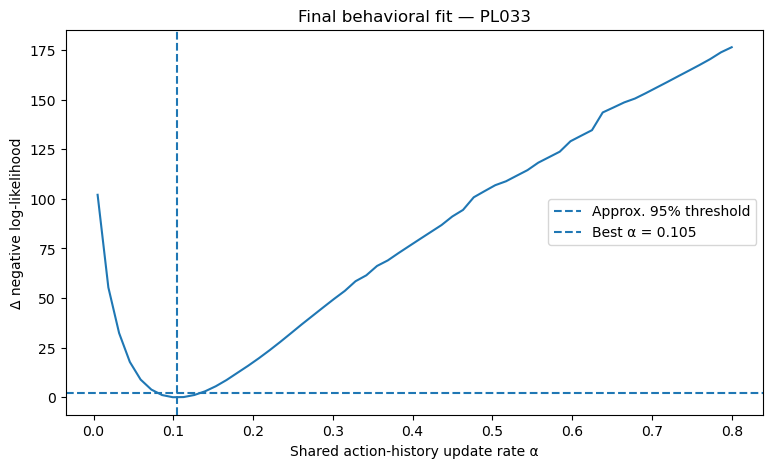

In [92]:
# ============================================================
# STEP 14 — Plot final PL033 mouse profile
# ============================================================

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    pl033_profile["alpha"],
    pl033_profile["delta_nll"]
)

plt.axhline(
    PROFILE_THRESHOLD,
    linestyle="--",
    label="Approx. 95% threshold"
)

plt.axvline(
    pl033_result["alpha"],
    linestyle="--",
    label=(
        f"Best α = "
        f"{pl033_result['alpha']:.3f}"
    )
)

plt.xlabel(
    "Shared action-history update rate α"
)

plt.ylabel(
    "Δ negative log-likelihood"
)

plt.title(
    "Final behavioral fit — PL033"
)

plt.legend()

plt.show()

In [93]:
# ============================================================
# STEP 14 — Inspect session-specific nuisance parameters
# ============================================================

display(
    pl033_nuisance
)

,session_index,date,nll,sensory_noise,lapse_right_stimulus,lapse_left_stimulus
0,0,2022-10-04,111.648723,0.091803,0.000000e+00,0.095194
1,1,2022-10-05,54.904055,0.038310,0.000000e+00,0.081346
2,2,2022-10-06,74.688620,0.057204,0.000000e+00,0.056598
3,3,2022-10-07,38.109215,0.032388,0.000000e+00,0.035044
4,4,2022-10-10,80.249439,0.066086,0.000000e+00,0.095523
5,5,2022-10-11,77.563539,0.087421,1.600648e-02,0.044666
6,6,2022-10-12,66.588550,0.056969,1.241936e-02,0.126407
7,7,2022-10-25,44.380942,0.075680,0.000000e+00,0.015268
8,8,2022-10-26,79.634857,0.051343,0.000000e+00,0.081451
9,9,2022-10-28,77.781629,0.069369,0.000000e+00,0.129689


The pipeline reproduces the result of Step 13 (α = 0.1050, **τ = 9.02 trials, 95 % interval 7.4 – 11.1**) without boundary flags. The nuisance parameters show the day-to-day variability that the model deliberately keeps *out* of α: across sessions, sensory noise ranges from 0.03 to 0.13, λ<sub>R</sub> stays close to zero and λ<sub>L</sub> varies between 0.015 and 0.135.

---

## Part 5 · Fitting the whole population

### Step 15 — Population fit

The population sample is every Brain-Wide Map mouse with at least two sessions: **107 of 139 mice**. Before launching the full run, the pipeline is validated on the next three mice in the list.

In [94]:
# ============================================================
# STEP 15 — Define the population analysis sample
# ============================================================

candidate_mice = (
    mouse_overview
    .loc[
        mouse_overview["n_sessions"] >= 2,
        ["subject", "n_sessions", "n_probes"]
    ]
    .copy()
    .reset_index(drop=True)
)

print("=" * 70)
print("POPULATION ANALYSIS SAMPLE")
print("=" * 70)

print(
    "Total BWM mice:",
    len(mouse_overview)
)

print(
    "Mice with >= 2 sessions:",
    len(candidate_mice)
)

display(
    candidate_mice.head(20)
)

POPULATION ANALYSIS SAMPLE
Total BWM mice: 139
Mice with >= 2 sessions: 107


,subject,n_sessions,n_probes
0,PL033,13,13
1,DY_009,9,9
2,PL050,9,11
3,ibl_witten_29,9,11
4,DY_020,8,16
5,CSH_ZAD_022,8,12
6,PL030,8,8
7,CSH_ZAD_029,7,14
8,SWC_052,7,13
9,CSH_ZAD_025,7,12


In [95]:
# ============================================================
# STEP 15 — Small-batch validation set
# ============================================================

validation_mice = (
    candidate_mice[
        candidate_mice["subject"] != "PL033"
    ]
    .head(3)
    ["subject"]
    .tolist()
)

print(
    "Validation mice:",
    validation_mice
)

Validation mice: ['DY_009', 'PL050', 'ibl_witten_29']


In [96]:
# ============================================================
# STEP 15 — Validate pipeline on a small batch of mice
# ============================================================

validation_results = []

validation_profiles = {}

for i, subject in enumerate(validation_mice):

    print("\n")
    print("#" * 80)

    print(
        f"Validation mouse "
        f"{i+1}/{len(validation_mice)}: "
        f"{subject}"
    )

    print("#" * 80)

    try:

        (
            mouse_result,
            mouse_profile,
            mouse_sessions,
            mouse_nuisance
        ) = fit_mouse_action_kernel(
            one,
            bwm_df,
            subject=subject,
            verbose=True
        )

        validation_results.append(
            mouse_result
        )

        validation_profiles[
            subject
        ] = mouse_profile

    except Exception as error:

        print(
            f"\nERROR while fitting "
            f"{subject}:"
        )

        print(error)

        validation_results.append(
            {
                "subject": subject,
                "fit_success": False,
                "failure_reason": str(error)
            }
        )



################################################################################
Validation mouse 1/3: DY_009
################################################################################
FITTING MOUSE: DY_009
Number of sessions: 9
Total trials: 3907
Valid likelihood trials: 2780

FINAL MOUSE FIT
alpha = 0.2767
tau = 3.087 trials

alpha interval = [0.2475, 0.3149]
tau interval = [2.644, 3.516]

Best near boundary: False
CI hits lower boundary: False
CI hits upper boundary: False


################################################################################
Validation mouse 2/3: PL050
################################################################################
FITTING MOUSE: PL050
Number of sessions: 9
Total trials: 6649
Valid likelihood trials: 4365

FINAL MOUSE FIT
alpha = 0.1616
tau = 5.672 trials

alpha interval = [0.1397, 0.1802]
tau interval = [5.034, 6.643]

Best near boundary: False
CI hits lower boundary: False
CI hits upper boundary: False


######################

In [97]:
# ============================================================
# STEP 15 — Inspect small-batch fitting results
# ============================================================

validation_df = pd.DataFrame(
    validation_results
)

display(
    validation_df
)

,subject,n_sessions,n_trials,n_valid_trials,alpha,tau,best_nll,alpha_ci_low,alpha_ci_high,tau_ci_low,tau_ci_high,fit_success,best_near_boundary,ci_hits_lower_boundary,ci_hits_upper_boundary,profile_width_alpha,profile_width_tau
0,DY_009,9,3907,2780,0.276708,3.086974,717.312429,0.247542,0.314915,2.644015,3.516043,True,False,False,False,0.067373,0.872029
1,PL050,9,6649,4365,0.161634,5.672120,1119.919008,0.139746,0.180169,5.033785,6.643313,True,False,False,False,0.040424,1.609527
2,ibl_witten_29,9,6241,4731,0.142684,6.495672,1109.184101,0.126271,0.166695,5.483795,7.408218,True,False,False,False,0.040424,1.924422


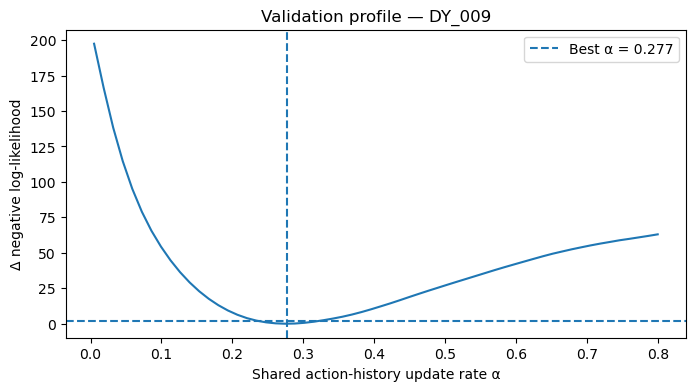

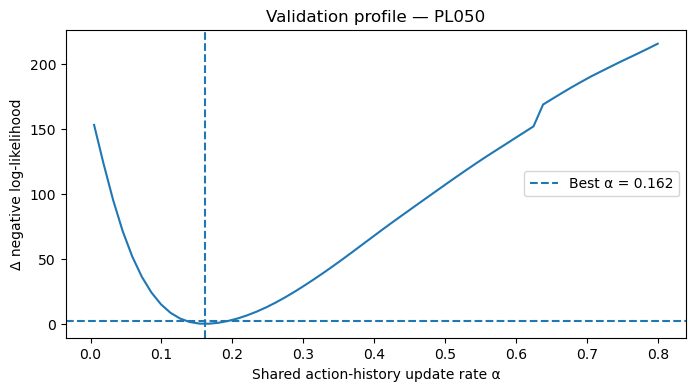

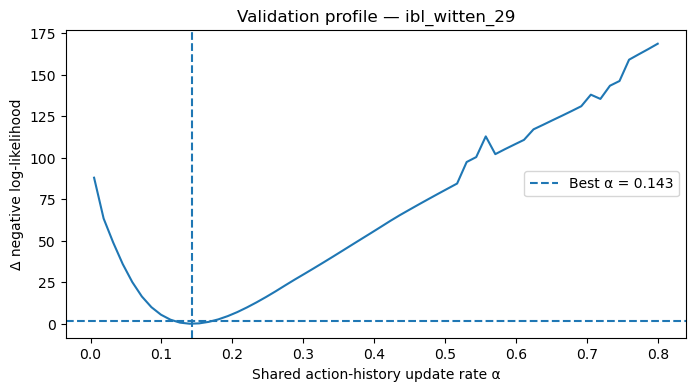

In [98]:
# ============================================================
# STEP 15 — Plot validation profiles
# ============================================================

for subject in validation_mice:

    profile = validation_profiles.get(
        subject
    )

    if profile is None:
        continue

    result_row = validation_df[
        validation_df["subject"] == subject
    ]

    if len(result_row) == 0:
        continue

    if not bool(
        result_row["fit_success"].iloc[0]
    ):
        continue

    alpha_best = (
        result_row["alpha"].iloc[0]
    )

    plt.figure(
        figsize=(8, 4)
    )

    plt.plot(
        profile["alpha"],
        profile["delta_nll"]
    )

    plt.axhline(
        PROFILE_THRESHOLD,
        linestyle="--"
    )

    plt.axvline(
        alpha_best,
        linestyle="--",
        label=(
            f"Best α = "
            f"{alpha_best:.3f}"
        )
    )

    plt.xlabel(
        "Shared action-history update rate α"
    )

    plt.ylabel(
        "Δ negative log-likelihood"
    )

    plt.title(
        f"Validation profile — {subject}"
    )

    plt.legend()

    plt.show()

All three validation mice have a single, well-defined minimum away from the grid edges, and narrow intervals:

| Mouse | Sessions | Valid trials | τ (trials) | 95 % interval |
|---|---|---|---|---|
| DY_009 | 9 | 2,780 | 3.1 | 2.6 – 3.5 |
| PL050 | 9 | 4,365 | 5.7 | 5.0 – 6.6 |
| ibl_witten_29 | 9 | 4,731 | 6.5 | 5.5 – 7.4 |
| *PL033 (Step 14)* | *13* | *4,233* | *9.0* | *7.4 – 11.1* |

The interval of DY_009 does not overlap with any of the others: even this handful of mice already shows **genuine individual differences**, with a three-fold range of timescales. The small kinks at large α again come from the nuisance-parameter optimization, far from the minimum.

#### Saving results safely

Fitting 107 mice takes hours, so results are written to disk as soon as each mouse is done:

* `results/population_behavior_fits.csv` — one row per mouse (estimates, intervals, QC flags, runtime);
* `results/mouse_profiles/<mouse>_profile.csv` — the full α profile of each mouse.

If the notebook is restarted, the existing checkpoint is loaded and mice that were already fitted successfully are skipped.

In [99]:
# ============================================================
# STEP 15 — Create persistent local output directories
# ============================================================

from pathlib import Path

# Current working directory (the cloned paper-brain-wide-map
# folder, see Step 1)
PROJECT_DIR = Path.cwd()

# Main results folder
OUTPUT_DIR = PROJECT_DIR / "results"

# Individual mouse profile curves
PROFILE_DIR = OUTPUT_DIR / "mouse_profiles"

# Main checkpoint file
CHECKPOINT_PATH = OUTPUT_DIR / "population_behavior_fits.csv"

# Create folders if they do not already exist
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

PROFILE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Current working directory:")
print(PROJECT_DIR)

print("\nResults directory:")
print(OUTPUT_DIR)

print("\nMouse-profile directory:")
print(PROFILE_DIR)

print("\nPopulation checkpoint:")
print(CHECKPOINT_PATH)

Current working directory:
/home/omidi/pytopia/paper-brain-wide-map

Results directory:
/home/omidi/pytopia/paper-brain-wide-map/results

Mouse-profile directory:
/home/omidi/pytopia/paper-brain-wide-map/results/mouse_profiles

Population checkpoint:
/home/omidi/pytopia/paper-brain-wide-map/results/population_behavior_fits.csv


In [102]:
# ============================================================
# STEP 15 — Verify that the local results directory is writable
# ============================================================

TEST_FILE = OUTPUT_DIR / "_write_test.txt"

with open(TEST_FILE, "w") as f:
    f.write("IBL project write test")

print("Test file created:")
print(TEST_FILE)

TEST_FILE.unlink()

print("Write permission OK.")

Test file created:
/home/omidi/pytopia/paper-brain-wide-map/results/_write_test.txt
Write permission OK.


In [103]:
# ============================================================
# STEP 15 — Load existing checkpoint / resume previous run
# ============================================================

if CHECKPOINT_PATH.exists():

    population_df_existing = pd.read_csv(
        CHECKPOINT_PATH
    )

    print("Existing checkpoint found.")

    print(
        "Rows currently stored:",
        len(population_df_existing)
    )

    # Only successful fits are considered completed.
    successful_existing = population_df_existing[
        population_df_existing["fit_success"] == True
    ].copy()

    completed_subjects = set(
        successful_existing["subject"]
        .astype(str)
    )

    print(
        "Successfully completed mice:",
        len(completed_subjects)
    )

else:

    population_df_existing = pd.DataFrame()

    completed_subjects = set()

    print("No previous checkpoint found.")
    print("Starting a new population run.")

No previous checkpoint found.
Starting a new population run.


In [104]:
# ============================================================
# STEP 15 — Safely update population checkpoint
# ============================================================

def update_population_checkpoint(
    checkpoint_path,
    new_result
):
    """
    Add or replace one mouse result in the population CSV.
    """

    new_row = pd.DataFrame(
        [new_result]
    )

    if checkpoint_path.exists():

        old_df = pd.read_csv(
            checkpoint_path
        )

        # Remove any older row for this subject
        old_df = old_df[
            old_df["subject"].astype(str)
            != str(new_result["subject"])
        ].copy()

        updated_df = pd.concat(
            [
                old_df,
                new_row
            ],
            ignore_index=True
        )

    else:

        updated_df = new_row

    updated_df.to_csv(
        checkpoint_path,
        index=False
    )

    return updated_df

#### Run the population fit

⚠️ **Slow cell:** the complete run took about **4.4 hours** (1 – 8 minutes per mouse). It is safe to interrupt and re-run, because it resumes from the checkpoint.

In [105]:
# ============================================================
# STEP 15 — FULL POPULATION BEHAVIORAL FIT
# ============================================================
# Fits every candidate mouse and saves each result immediately,
# so an interrupted run can be resumed: mice already stored in
# the checkpoint with fit_success == True are skipped.
# (The complete run took about 4.4 hours.)

import time


subjects_to_fit = (
    candidate_mice["subject"]
    .astype(str)
    .tolist()
)

n_total = len(
    subjects_to_fit
)


for index, subject in enumerate(
    subjects_to_fit,
    start=1
):

    # --------------------------------------------------------
    # Skip successful fits already present in checkpoint
    # --------------------------------------------------------

    if subject in completed_subjects:

        print(
            f"[{index}/{n_total}] "
            f"{subject} already completed — skipping."
        )

        continue

    print("\n" + "=" * 90)

    print(
        f"[{index}/{n_total}] "
        f"FITTING MOUSE: {subject}"
    )

    print("=" * 90)

    start_time = time.time()

    try:

        (
            mouse_result,
            mouse_profile,
            mouse_sessions,
            mouse_nuisance
        ) = fit_mouse_action_kernel(
            one,
            bwm_df,
            subject=subject,
            verbose=False
        )

        runtime_minutes = (
            time.time() - start_time
        ) / 60

        mouse_result[
            "runtime_minutes"
        ] = runtime_minutes

        # ====================================================
        # Save the mouse profile if fitting succeeded
        # ====================================================

        if (
            mouse_result.get(
                "fit_success",
                False
            )
            and
            mouse_profile is not None
        ):

            safe_subject = (
                str(subject)
                .replace("/", "_")
                .replace("\\", "_")
                .replace(" ", "_")
            )

            profile_path = (
                PROFILE_DIR
                / f"{safe_subject}_profile.csv"
            )

            mouse_profile.to_csv(
                profile_path,
                index=False
            )

        # ====================================================
        # Immediately save/update checkpoint
        # ====================================================

        population_df = (
            update_population_checkpoint(
                CHECKPOINT_PATH,
                mouse_result
            )
        )

        # ====================================================
        # Human-readable progress report
        # ====================================================

        if mouse_result.get(
            "fit_success",
            False
        ):

            completed_subjects.add(
                subject
            )

            print(
                f"\nCompleted: {subject}"
            )

            print(
                f"alpha = "
                f"{mouse_result['alpha']:.4f}"
            )

            print(
                f"tau = "
                f"{mouse_result['tau']:.3f} trials"
            )

            print(
                f"tau interval = "
                f"[{mouse_result['tau_ci_low']:.3f}, "
                f"{mouse_result['tau_ci_high']:.3f}]"
            )

            print(
                "Best near boundary:",
                mouse_result[
                    "best_near_boundary"
                ]
            )

            print(
                "CI hits lower boundary:",
                mouse_result[
                    "ci_hits_lower_boundary"
                ]
            )

            print(
                "CI hits upper boundary:",
                mouse_result[
                    "ci_hits_upper_boundary"
                ]
            )

        else:

            print(
                f"\nFit did not succeed for "
                f"{subject}"
            )

            print(
                "Reason:",
                mouse_result.get(
                    "failure_reason",
                    "unknown"
                )
            )

        print(
            f"\nRuntime: "
            f"{runtime_minutes:.2f} minutes"
        )

        print(
            "Checkpoint updated:"
        )

        print(
            CHECKPOINT_PATH
        )

    # ========================================================
    # Catch unexpected errors
    # ========================================================

    except Exception as error:

        runtime_minutes = (
            time.time() - start_time
        ) / 60

        print(
            f"\nERROR while fitting "
            f"{subject}"
        )

        print(
            type(error).__name__,
            ":",
            error
        )

        failure_result = {
            "subject":
                subject,

            "fit_success":
                False,

            "failure_reason":
                (
                    f"{type(error).__name__}: "
                    f"{str(error)}"
                ),

            "runtime_minutes":
                runtime_minutes
        }

        population_df = (
            update_population_checkpoint(
                CHECKPOINT_PATH,
                failure_result
            )
        )

        print(
            "Failure saved to checkpoint."
        )

        print(
            "The run will continue."
        )


[1/107] FITTING MOUSE: PL033



Completed: PL033
alpha = 0.1050
tau = 9.018 trials
tau interval = [7.408, 11.141]
Best near boundary: False
CI hits lower boundary: False
CI hits upper boundary: False

Runtime: 7.56 minutes
Checkpoint updated:
/home/omidi/pytopia/paper-brain-wide-map/results/population_behavior_fits.csv

[2/107] FITTING MOUSE: DY_009

Completed: DY_009
alpha = 0.2767
tau = 3.087 trials
tau interval = [2.644, 3.516]
Best near boundary: False
CI hits lower boundary: False
CI hits upper boundary: False

Runtime: 5.09 minutes
Checkpoint updated:
/home/omidi/pytopia/paper-brain-wide-map/results/population_behavior_fits.csv

[3/107] FITTING MOUSE: PL050

Completed: PL050
alpha = 0.1616
tau = 5.672 trials
tau interval = [5.034, 6.643]
Best near boundary: False
CI hits lower boundary: False
CI hits upper boundary: False

Runtime: 5.70 minutes
Checkpoint updated:
/home/omidi/pytopia/paper-brain-wide-map/results/population_behavior_fits.csv

[4/107] FITTING MOUSE: ibl_witten_29

Completed: ibl_witten_29
alpha 

/home/omidi/miniconda3/envs/pytopia/lib/python3.14/site-packages/one/util.py:464: ALFWarning: Multiple revisions: "", "2024-02-20"
  warnings.warn(f'Multiple revisions: {rev_list}', alferr.ALFWarning)



Completed: CSH_ZAD_029
alpha = 0.2018
tau = 4.438 trials
tau interval = [4.012, 5.034]
Best near boundary: False
CI hits lower boundary: False
CI hits upper boundary: False

Runtime: 5.52 minutes
Checkpoint updated:
/home/omidi/pytopia/paper-brain-wide-map/results/population_behavior_fits.csv

[9/107] FITTING MOUSE: SWC_052

Completed: SWC_052
alpha = 0.0915
tau = 10.420 trials
tau interval = [7.408, 16.473]
Best near boundary: False
CI hits lower boundary: False
CI hits upper boundary: False

Runtime: 4.01 minutes
Checkpoint updated:
/home/omidi/pytopia/paper-brain-wide-map/results/population_behavior_fits.csv

[10/107] FITTING MOUSE: CSH_ZAD_025

Completed: CSH_ZAD_025
alpha = 0.1182
tau = 7.946 trials
tau interval = [6.643, 9.560]
Best near boundary: False
CI hits lower boundary: False
CI hits upper boundary: False

Runtime: 3.96 minutes
Checkpoint updated:
/home/omidi/pytopia/paper-brain-wide-map/results/population_behavior_fits.csv

[11/107] FITTING MOUSE: DY_014

Completed: DY_0

/home/omidi/miniconda3/envs/pytopia/lib/python3.14/site-packages/one/util.py:464: ALFWarning: Multiple revisions: "", "2024-02-22"
  warnings.warn(f'Multiple revisions: {rev_list}', alferr.ALFWarning)



Completed: KS023
alpha = 0.1504
tau = 6.137 trials
tau interval = [4.646, 7.408]
Best near boundary: False
CI hits lower boundary: False
CI hits upper boundary: False

Runtime: 2.68 minutes
Checkpoint updated:
/home/omidi/pytopia/paper-brain-wide-map/results/population_behavior_fits.csv

[47/107] FITTING MOUSE: CSH_ZAD_019

Completed: CSH_ZAD_019
alpha = 0.1331
tau = 6.999 trials
tau interval = [5.484, 9.560]
Best near boundary: False
CI hits lower boundary: False
CI hits upper boundary: False

Runtime: 2.74 minutes
Checkpoint updated:
/home/omidi/pytopia/paper-brain-wide-map/results/population_behavior_fits.csv

[48/107] FITTING MOUSE: ZM_2240

Completed: ZM_2240
alpha = 0.1384
tau = 6.714 trials
tau interval = [5.484, 8.356]
Best near boundary: False
CI hits lower boundary: False
CI hits upper boundary: False

Runtime: 3.29 minutes
Checkpoint updated:
/home/omidi/pytopia/paper-brain-wide-map/results/population_behavior_fits.csv

[49/107] FITTING MOUSE: NYU-46

Completed: NYU-46
alph

/home/omidi/miniconda3/envs/pytopia/lib/python3.14/site-packages/one/util.py:464: ALFWarning: Multiple revisions: "2022-10-31", ""
  warnings.warn(f'Multiple revisions: {rev_list}', alferr.ALFWarning)



Completed: CSH_ZAD_011
alpha = 0.0684
tau = 14.110 trials
tau interval = [7.408, 30.797]
Best near boundary: False
CI hits lower boundary: False
CI hits upper boundary: False

Runtime: 1.57 minutes
Checkpoint updated:
/home/omidi/pytopia/paper-brain-wide-map/results/population_behavior_fits.csv

[75/107] FITTING MOUSE: DY_013

Completed: DY_013
alpha = 0.1016
tau = 9.335 trials
tau interval = [6.013, 13.311]
Best near boundary: False
CI hits lower boundary: False
CI hits upper boundary: False

Runtime: 1.40 minutes
Checkpoint updated:
/home/omidi/pytopia/paper-brain-wide-map/results/population_behavior_fits.csv

[76/107] FITTING MOUSE: SWC_038

Completed: SWC_038
alpha = 0.1778
tau = 5.107 trials
tau interval = [4.012, 6.013]
Best near boundary: False
CI hits lower boundary: False
CI hits upper boundary: False

Runtime: 2.37 minutes
Checkpoint updated:
/home/omidi/pytopia/paper-brain-wide-map/results/population_behavior_fits.csv

[77/107] FITTING MOUSE: SWC_060

Completed: SWC_060
alp

In [106]:
# ============================================================
# STEP 15 — Inspect the most recent checkpoint rows
# ============================================================

current_checkpoint = pd.read_csv(
    CHECKPOINT_PATH
)

display(
    current_checkpoint[
        [
            "subject",
            "n_sessions",
            "n_valid_trials",
            "alpha",
            "tau",
            "tau_ci_low",
            "tau_ci_high",
            "fit_success",
            "best_near_boundary",
            "ci_hits_lower_boundary",
            "ci_hits_upper_boundary",
            "runtime_minutes"
        ]
    ].tail(10)
)

,subject,n_sessions,n_valid_trials,alpha,tau,tau_ci_low,tau_ci_high,fit_success,best_near_boundary,ci_hits_lower_boundary,ci_hits_upper_boundary,runtime_minutes
97,ZFM-02370,2,1011,0.073733,13.056073,7.408218,21.511052,True,False,False,False,1.442369
98,ZFM-04308,2,503,0.023927,41.291151,16.473359,53.626886,True,False,False,False,1.145993
99,SWC_042,2,646,0.185283,4.880078,3.516043,7.408218,True,False,False,False,1.233427
100,UCLA035,2,951,0.163514,5.600813,4.012484,7.408218,True,False,False,False,1.371960
101,KS086,2,698,0.209138,4.261992,2.944383,6.012695,True,False,False,False,1.156336
102,KS055,2,694,0.158836,5.781402,3.516043,9.559544,True,False,False,False,1.163612
103,MFD_08,2,473,0.232209,3.784473,2.644015,5.483795,True,False,False,False,1.184783
104,NR_0031,2,619,0.301927,2.782173,1.674422,5.033785,True,False,False,False,1.209216
105,NYU-21,2,839,0.228397,3.856767,2.644015,6.012695,True,False,False,False,1.435781
106,NYU-11,2,639,0.143436,6.458847,3.750071,13.311070,True,False,False,False,1.163046


In [107]:
# ============================================================
# STEP 15 — Monitor population-fitting progress
# ============================================================

current_checkpoint = pd.read_csv(
    CHECKPOINT_PATH
)

n_attempted = len(current_checkpoint)

n_success = (
    current_checkpoint["fit_success"]
    .fillna(False)
    .sum()
)

n_failed = (
    ~current_checkpoint["fit_success"]
    .fillna(False)
).sum()

print("=" * 70)
print("CURRENT POPULATION FITTING STATUS")
print("=" * 70)

print(
    f"Attempted: {n_attempted} / {len(candidate_mice)}"
)

print(
    f"Successful: {n_success}"
)

print(
    f"Failed: {n_failed}"
)

print(
    f"Remaining: "
    f"{len(candidate_mice) - n_attempted}"
)

print("=" * 70)

CURRENT POPULATION FITTING STATUS
Attempted: 107 / 107
Successful: 107
Failed: 0
Remaining: 0


All **107 / 107** mice were fitted without errors. The `ALFWarning` messages in the log only report that several revisions of a dataset exist on the server; they did not stop any fit.

### Step 16 — Quality control

Before interpreting the estimates, we check:

1. **fit failures** and the integrity of the checkpoint (one row per mouse, no duplicates);
2. **boundary problems** — an estimate at the edge of the α range, or an interval that runs into it, means that τ is not identified on that side;
3. **precision** — the relative interval width (τ<sub>high</sub> − τ<sub>low</sub>) / τ, and how it depends on the amount of data.

In [108]:
# ============================================================
# STEP 16 — Inspect failed population fits
# ============================================================

# Reload from disk so this also works when the fitting loop
# skipped every mouse (i.e. when resuming a finished run).
population_df = pd.read_csv(
    CHECKPOINT_PATH
)

failed_fits = (
    population_df[
        population_df["fit_success"] != True
    ]
    .copy()
    .reset_index(drop=True)
)

print("=" * 70)
print("FAILED MOUSE FITS")
print("=" * 70)

print(
    "Number of failed fits:",
    len(failed_fits)
)

if len(failed_fits) > 0:

    columns_to_show = [
        col for col in [
            "subject",
            "failure_reason",
            "runtime_minutes"
        ]
        if col in failed_fits.columns
    ]

    display(
        failed_fits[
            columns_to_show
        ]
    )

FAILED MOUSE FITS
Number of failed fits: 0


In [109]:
# ============================================================
# STEP 16 — Verify final population checkpoint integrity
# ============================================================

population_df = pd.read_csv(
    CHECKPOINT_PATH
)

n_rows = len(population_df)

n_unique_subjects = (
    population_df["subject"]
    .astype(str)
    .nunique()
)

n_duplicates = (
    population_df["subject"]
    .astype(str)
    .duplicated()
    .sum()
)

n_success = (
    population_df["fit_success"]
    .fillna(False)
    .sum()
)

print("=" * 75)
print("FINAL CHECKPOINT INTEGRITY CHECK")
print("=" * 75)

print(
    f"Rows in checkpoint: "
    f"{n_rows}"
)

print(
    f"Unique subjects: "
    f"{n_unique_subjects}"
)

print(
    f"Duplicate subjects: "
    f"{n_duplicates}"
)

print(
    f"Successful fits: "
    f"{n_success}"
)

print("=" * 75)

FINAL CHECKPOINT INTEGRITY CHECK
Rows in checkpoint: 107
Unique subjects: 107
Duplicate subjects: 0
Successful fits: 107


In [110]:
# ============================================================
# STEP 16 — Save a backup of the completed population fit
# ============================================================

FINAL_BACKUP_PATH = (
    OUTPUT_DIR
    / "population_behavior_fits_COMPLETE_107.csv"
)

population_df.to_csv(
    FINAL_BACKUP_PATH,
    index=False
)

print("Final backup saved to:")
print(FINAL_BACKUP_PATH)

Final backup saved to:
/home/omidi/pytopia/paper-brain-wide-map/results/population_behavior_fits_COMPLETE_107.csv


In [111]:
# ============================================================
# STEP 16 — Successful population fits
# ============================================================

successful_fits = (
    population_df[
        population_df["fit_success"] == True
    ]
    .copy()
    .reset_index(drop=True)
)

print(
    "Successful mouse fits:",
    len(successful_fits)
)

Successful mouse fits: 107


In [112]:
# ============================================================
# STEP 16 — Boundary diagnostics
# ============================================================

n_best_boundary = (
    successful_fits[
        "best_near_boundary"
    ]
    .fillna(True)
    .sum()
)

n_ci_lower = (
    successful_fits[
        "ci_hits_lower_boundary"
    ]
    .fillna(True)
    .sum()
)

n_ci_upper = (
    successful_fits[
        "ci_hits_upper_boundary"
    ]
    .fillna(True)
    .sum()
)


print("=" * 75)
print("BOUNDARY DIAGNOSTICS")
print("=" * 75)

print(
    f"Best alpha near boundary: "
    f"{n_best_boundary}"
)

print(
    f"CI hits lower boundary: "
    f"{n_ci_lower}"
)

print(
    f"CI hits upper boundary: "
    f"{n_ci_upper}"
)

print("=" * 75)

BOUNDARY DIAGNOSTICS
Best alpha near boundary: 1
CI hits lower boundary: 1
CI hits upper boundary: 0


In [113]:
# ============================================================
# STEP 16 — Inspect boundary-flagged mice
# ============================================================

boundary_flagged = successful_fits[
    successful_fits[
        "best_near_boundary"
    ].fillna(True)
    |
    successful_fits[
        "ci_hits_lower_boundary"
    ].fillna(True)
    |
    successful_fits[
        "ci_hits_upper_boundary"
    ].fillna(True)
].copy()


print(
    "Number of boundary-flagged mice:",
    len(boundary_flagged)
)


if len(boundary_flagged) > 0:

    display(
        boundary_flagged[
            [
                "subject",
                "n_sessions",
                "n_valid_trials",
                "alpha",
                "tau",
                "alpha_ci_low",
                "alpha_ci_high",
                "tau_ci_low",
                "tau_ci_high",
                "best_near_boundary",
                "ci_hits_lower_boundary",
                "ci_hits_upper_boundary"
            ]
        ]
        .sort_values("alpha")
    )

Number of boundary-flagged mice: 1


,subject,n_sessions,n_valid_trials,alpha,tau,alpha_ci_low,alpha_ci_high,tau_ci_low,tau_ci_high,best_near_boundary,ci_hits_lower_boundary,ci_hits_upper_boundary
50,NR_0024,4,1462,0.011783,84.365663,0.005,0.031949,30.797029,199.499582,True,True,False


Only **one mouse is flagged: NR_0024** (4 sessions, 1,462 valid trials). Its best α = 0.012 lies at the lower edge of the range and its interval runs into the boundary, so τ has a lower bound (about 31 trials) but no meaningful upper bound: the value 199.5 is simply the edge of the grid. Its profile is inspected below.

In [114]:
# ============================================================
# STEP 16 — Quantify uncertainty
# ============================================================

successful_fits[
    "alpha_ci_width"
] = (
    successful_fits[
        "alpha_ci_high"
    ]
    -
    successful_fits[
        "alpha_ci_low"
    ]
)


successful_fits[
    "tau_ci_width"
] = (
    successful_fits[
        "tau_ci_high"
    ]
    -
    successful_fits[
        "tau_ci_low"
    ]
)


successful_fits[
    "relative_tau_ci_width"
] = (
    successful_fits[
        "tau_ci_width"
    ]
    /
    successful_fits[
        "tau"
    ]
)

In [115]:
# ============================================================
# STEP 16 — Uncertainty summaries
# ============================================================

print("=" * 75)
print("TAU UNCERTAINTY SUMMARY")
print("=" * 75)

display(
    successful_fits[
        "relative_tau_ci_width"
    ]
    .describe()
)

print(
    "\nMedian relative tau uncertainty:"
)

print(
    successful_fits[
        "relative_tau_ci_width"
    ]
    .median()
)

TAU UNCERTAINTY SUMMARY


count    107.000000
mean       0.684429
std        0.298105
min        0.230140
25%        0.464168
50%        0.650507
75%        0.810238
max        1.999659
Name: relative_tau_ci_width, dtype: float64


Median relative tau uncertainty:
0.6505067152352598


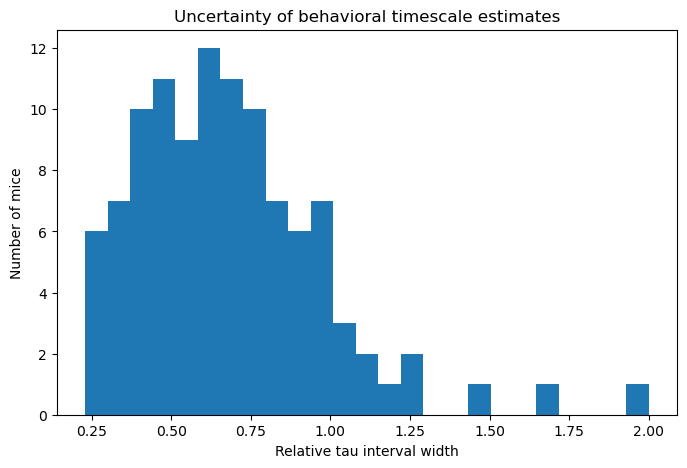

In [116]:
# ============================================================
# STEP 16 — Distribution of parameter uncertainty
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.hist(
    successful_fits[
        "relative_tau_ci_width"
    ].dropna(),
    bins=25
)

plt.xlabel(
    "Relative tau interval width"
)

plt.ylabel(
    "Number of mice"
)

plt.title(
    "Uncertainty of behavioral timescale estimates"
)

plt.show()

In [117]:
# ============================================================
# STEP 16 — Inspect least precise mouse estimates
# ============================================================

least_precise = (
    successful_fits
    .sort_values(
        "relative_tau_ci_width",
        ascending=False
    )
    .head(15)
)

display(
    least_precise[
        [
            "subject",
            "n_sessions",
            "n_valid_trials",
            "alpha",
            "tau",
            "tau_ci_low",
            "tau_ci_high",
            "relative_tau_ci_width",
            "best_near_boundary",
            "ci_hits_lower_boundary",
            "ci_hits_upper_boundary"
        ]
    ]
)

,subject,n_sessions,n_valid_trials,alpha,tau,tau_ci_low,tau_ci_high,relative_tau_ci_width,best_near_boundary,ci_hits_lower_boundary,ci_hits_upper_boundary
50,NR_0024,4,1462,0.011783,84.365663,30.797029,199.499582,1.999659,True,True,False
73,CSH_ZAD_011,3,1421,0.068421,14.109573,7.408218,30.797029,1.657655,False,False,False
106,NYU-11,2,639,0.143436,6.458847,3.750071,13.311070,1.480295,False,False,False
26,CSHL059,5,1786,0.083155,11.518479,6.643313,21.511052,1.290773,False,False,False
61,NYU-45,3,556,0.264519,3.254887,1.899910,6.012695,1.263572,False,False,False
104,NR_0031,2,619,0.301927,2.782173,1.674422,5.033785,1.207460,False,False,False
85,UCLA049,2,535,0.227176,3.880428,2.277745,6.643313,1.125022,False,False,False
97,ZFM-02370,2,1011,0.073733,13.056073,7.408218,21.511052,1.080174,False,False,False
62,NYU-47,3,948,0.133015,7.006054,3.750071,11.141090,1.054947,False,False,False
102,KS055,2,694,0.158836,5.781402,3.516043,9.559544,1.045335,False,False,False


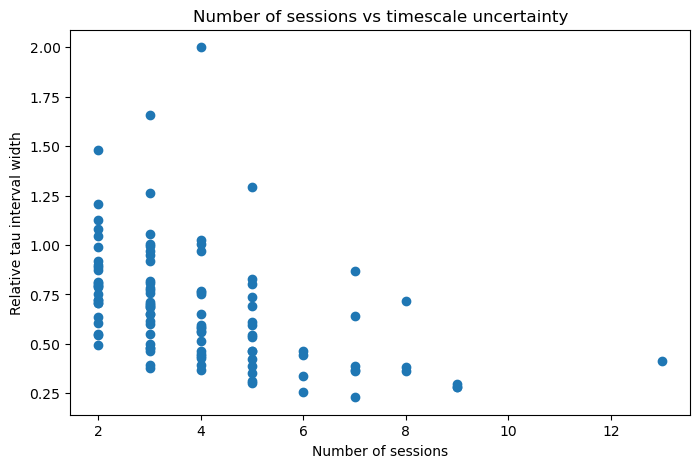

In [118]:
# ============================================================
# STEP 16 — Number of sessions vs uncertainty
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.scatter(
    successful_fits[
        "n_sessions"
    ],
    successful_fits[
        "relative_tau_ci_width"
    ]
)

plt.xlabel(
    "Number of sessions"
)

plt.ylabel(
    "Relative tau interval width"
)

plt.title(
    "Number of sessions vs timescale uncertainty"
)

plt.show()

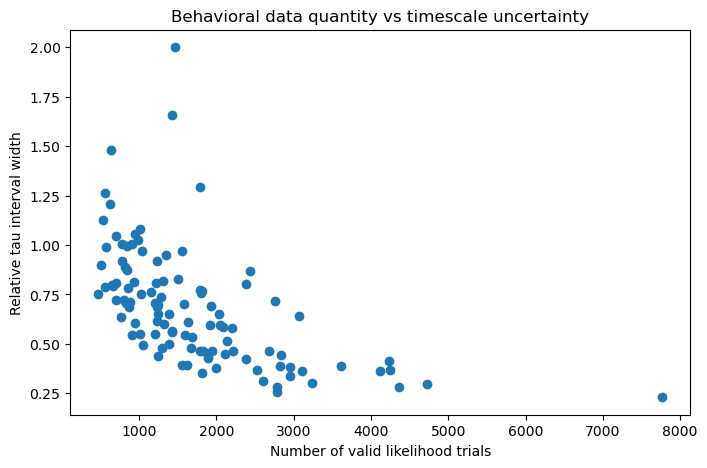

In [119]:
# ============================================================
# STEP 16 — Number of valid trials vs uncertainty
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.scatter(
    successful_fits[
        "n_valid_trials"
    ],
    successful_fits[
        "relative_tau_ci_width"
    ]
)

plt.xlabel(
    "Number of valid likelihood trials"
)

plt.ylabel(
    "Relative tau interval width"
)

plt.title(
    "Behavioral data quantity vs timescale uncertainty"
)

plt.show()

**Precision depends on the amount of data.** The median relative interval width is 0.65, i.e. the 95 % interval spans about 65 % of the estimate. It shrinks as the number of sessions and valid trials grows: the 15 least precise estimates all come from mice with 2 – 5 sessions and fewer than 1,800 valid trials, whereas mice with many sessions have consistently narrow intervals. Uncertainty is therefore mainly a matter of data quantity. Rather than discarding imprecise mice, their uncertainty is carried forward explicitly in Step 19.

In [120]:
# ============================================================
# STEP 16 — Basic structural QC
# ============================================================

successful_fits[
    "qc_pass_basic"
] = (
    (~successful_fits[
        "best_near_boundary"
    ].fillna(True))
    &
    (~successful_fits[
        "ci_hits_lower_boundary"
    ].fillna(True))
    &
    (~successful_fits[
        "ci_hits_upper_boundary"
    ].fillna(True))
    &
    np.isfinite(
        successful_fits["alpha"]
    )
    &
    np.isfinite(
        successful_fits["tau"]
    )
)


n_qc_pass = (
    successful_fits[
        "qc_pass_basic"
    ].sum()
)


print("=" * 75)
print("BASIC POPULATION QC")
print("=" * 75)

print(
    "Successful fits:",
    len(successful_fits)
)

print(
    "Pass basic QC:",
    n_qc_pass
)

print(
    "Fail basic QC:",
    len(successful_fits) - n_qc_pass
)

BASIC POPULATION QC
Successful fits: 107
Pass basic QC: 106
Fail basic QC: 1


In [121]:
# ============================================================
# STEP 16 — Basic-QC population sample
# ============================================================

qc_fits = (
    successful_fits[
        successful_fits[
            "qc_pass_basic"
        ]
    ]
    .copy()
    .reset_index(drop=True)
)

print(
    "Mice available after basic QC:",
    len(qc_fits)
)

Mice available after basic QC: 106


In [122]:
# ============================================================
# STEP 16 — Diagnostic high-uncertainty flag
# NOT an exclusion criterion
# ============================================================

uncertainty_cutoff = (
    qc_fits[
        "relative_tau_ci_width"
    ]
    .quantile(0.80)
)

qc_fits[
    "high_uncertainty_flag"
] = (
    qc_fits[
        "relative_tau_ci_width"
    ]
    >
    uncertainty_cutoff
)


print(
    "80th-percentile relative "
    "uncertainty cutoff:"
)

print(
    uncertainty_cutoff
)

print(
    "\nNumber of mice flagged "
    "as relatively high uncertainty:"
)

print(
    qc_fits[
        "high_uncertainty_flag"
    ].sum()
)

80th-percentile relative uncertainty cutoff:
0.8734467290634994

Number of mice flagged as relatively high uncertainty:
21


In [123]:
# ============================================================
# STEP 16 — Final QC summary
# ============================================================

print("=" * 78)
print("STEP 16 — POPULATION QUALITY CONTROL SUMMARY")
print("=" * 78)

print(
    f"Candidate mice: "
    f"{len(candidate_mice)}"
)

print(
    f"Successful fits: "
    f"{len(successful_fits)}"
)

print(
    f"Failed fits: "
    f"{len(candidate_mice) - len(successful_fits)}"
)

print(
    f"Basic-QC passing mice: "
    f"{len(qc_fits)}"
)

print("\nBoundary diagnostics:")

print(
    f"  Best alpha near boundary: "
    f"{n_best_boundary}"
)

print(
    f"  CI hits lower boundary: "
    f"{n_ci_lower}"
)

print(
    f"  CI hits upper boundary: "
    f"{n_ci_upper}"
)

print(
    "\nMedian relative tau uncertainty:"
)

print(
    qc_fits[
        "relative_tau_ci_width"
    ].median()
)

print("=" * 78)

STEP 16 — POPULATION QUALITY CONTROL SUMMARY
Candidate mice: 107
Successful fits: 107
Failed fits: 0
Basic-QC passing mice: 106

Boundary diagnostics:
  Best alpha near boundary: 1
  CI hits lower boundary: 1
  CI hits upper boundary: 0

Median relative tau uncertainty:
0.6496489717329417


**QC summary:** 107 successful fits, of which 106 pass the structural check. The 21 mice above the 80th percentile of relative interval width (> 0.87) are flagged as *high-uncertainty* for reference only — they are **not excluded**. Exclusion is reserved for structural problems, i.e. a τ that is not identified. The single structural failure is inspected next.

In [124]:
# ============================================================
# STEP 16 — Identify the structural-QC failure
# ============================================================

qc_failed = successful_fits[
    ~successful_fits["qc_pass_basic"]
].copy()

display(
    qc_failed[
        [
            "subject",
            "n_sessions",
            "n_valid_trials",
            "alpha",
            "tau",
            "alpha_ci_low",
            "alpha_ci_high",
            "tau_ci_low",
            "tau_ci_high",
            "best_near_boundary",
            "ci_hits_lower_boundary",
            "ci_hits_upper_boundary"
        ]
    ]
)

,subject,n_sessions,n_valid_trials,alpha,tau,alpha_ci_low,alpha_ci_high,tau_ci_low,tau_ci_high,best_near_boundary,ci_hits_lower_boundary,ci_hits_upper_boundary
50,NR_0024,4,1462,0.011783,84.365663,0.005,0.031949,30.797029,199.499582,True,True,False


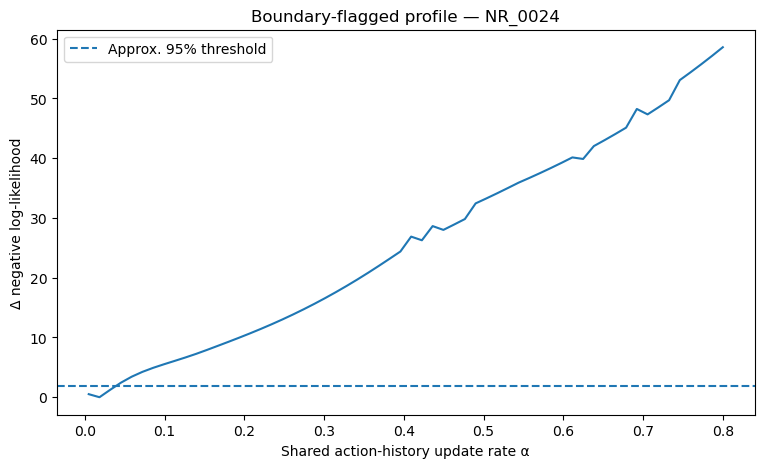

Flagged mouse: NR_0024


In [125]:
# ============================================================
# STEP 16 — Inspect the flagged mouse profile
# ============================================================

flagged_subject = qc_failed["subject"].iloc[0]

safe_subject = (
    str(flagged_subject)
    .replace("/", "_")
    .replace("\\", "_")
    .replace(" ", "_")
)

flagged_profile_path = (
    PROFILE_DIR
    / f"{safe_subject}_profile.csv"
)

flagged_profile = pd.read_csv(
    flagged_profile_path
)

plt.figure(figsize=(9, 5))

plt.plot(
    flagged_profile["alpha"],
    flagged_profile["delta_nll"]
)

plt.axhline(
    PROFILE_THRESHOLD,
    linestyle="--",
    label="Approx. 95% threshold"
)

plt.xlabel(
    "Shared action-history update rate α"
)

plt.ylabel(
    "Δ negative log-likelihood"
)

plt.title(
    f"Boundary-flagged profile — {flagged_subject}"
)

plt.legend()

plt.show()

print("Flagged mouse:", flagged_subject)

The profile of NR_0024 stays below the 95 % threshold all the way down to the smallest α tested (0.005). Its best-fitting kernel is so slow (τ ≈ 84 trials) that it acts almost like a constant bias: the data cannot distinguish very slow updating from no block-by-block updating at all. Because its τ is not identified, NR_0024 is excluded from the primary analysis, which leaves **106 mice**.

In [126]:
# ============================================================
# STEP 16 — Primary analysis sample (mice passing basic QC)
# ============================================================

analysis_fits = (
    successful_fits[
        successful_fits["qc_pass_basic"]
    ]
    .copy()
    .reset_index(drop=True)
)

print(
    "Mice entering primary population analysis:",
    len(analysis_fits)
)

Mice entering primary population analysis: 106


---

## Part 6 · Discrete groups or a continuum?

### Step 17 — How much do mice differ? (H3)

In [127]:
# ============================================================
# STEP 17 — Population summary of tau
# ============================================================

print("=" * 70)
print("POPULATION BEHAVIORAL TIMESCALE SUMMARY")
print("=" * 70)

print(
    analysis_fits["tau"]
    .describe(
        percentiles=[
            0.10,
            0.25,
            0.50,
            0.75,
            0.90
        ]
    )
)

POPULATION BEHAVIORAL TIMESCALE SUMMARY
count    106.000000
mean       6.665353
std        4.710575
min        2.677147
10%        3.554001
25%        4.234929
50%        5.500122
75%        6.992868
90%       10.405842
max       41.291151
Name: tau, dtype: float64


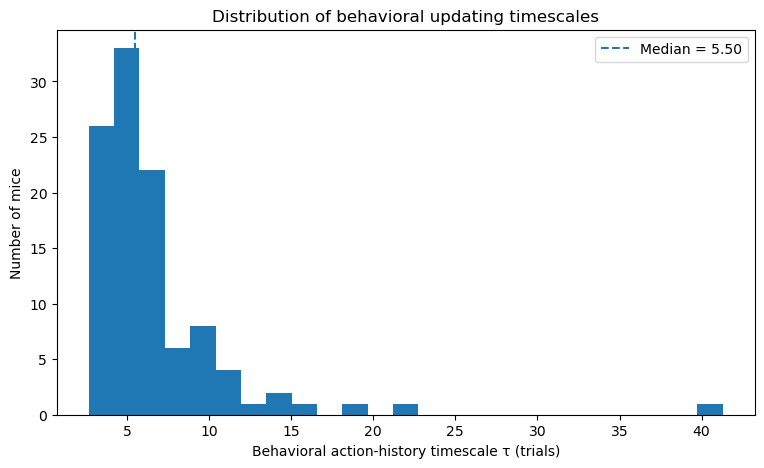

In [128]:
# ============================================================
# STEP 17 — Raw tau distribution
# ============================================================

plt.figure(figsize=(9, 5))

plt.hist(
    analysis_fits["tau"],
    bins=25
)

plt.axvline(
    analysis_fits["tau"].median(),
    linestyle="--",
    label=(
        f"Median = "
        f"{analysis_fits['tau'].median():.2f}"
    )
)

plt.xlabel(
    "Behavioral action-history timescale τ (trials)"
)

plt.ylabel(
    "Number of mice"
)

plt.title(
    "Distribution of behavioral updating timescales"
)

plt.legend()

plt.show()

**H3 is supported: mice differ substantially.** Across the 106 mice, τ ranges from 2.7 to 41 trials (median 5.5, IQR 4.2 – 7.0, 10th – 90th percentile 3.6 – 10.4). The prior of a typical mouse therefore reflects roughly its last five or six choices, but some mice integrate over windows two to three times longer. The fastest updater (KS044) has τ ≈ 2.7 trials; the slowest (ZFM-04308) has τ ≈ 41 trials, although with only two sessions its interval is wide (16 – 54 trials). These differences are large compared with the precision of well-measured mice (e.g. DY_009: 2.6 – 3.5 trials vs PL033: 7.4 – 11.1 trials).

**External check.** Findling et al. (2025) report a median action-kernel decay constant of **5.45 trials** across IBL mice. Our median of **5.50 trials**, obtained with a different fitting procedure (maximum likelihood per mouse with sessions pooled), is in close agreement.

The distribution is strongly right-skewed. Because timescales act multiplicatively, the analysis continues with **log τ**.

In [129]:
# ============================================================
# STEP 17 — Log-transform behavioral timescale
# ============================================================

analysis_fits["log_tau"] = np.log(
    analysis_fits["tau"]
)

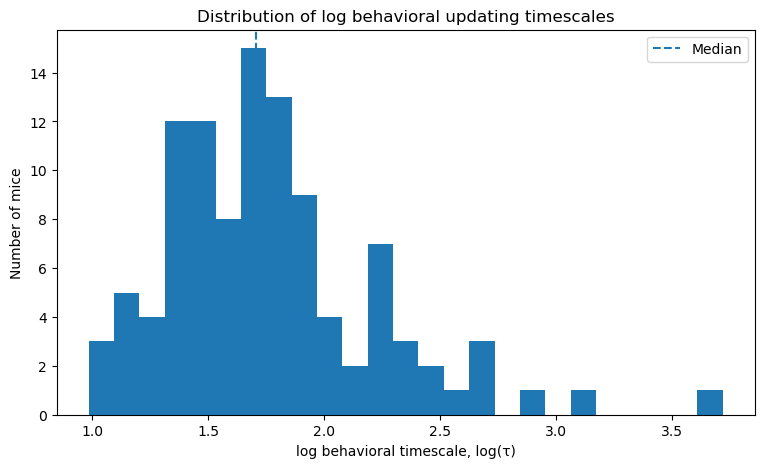

In [130]:
# ============================================================
# STEP 17 — Distribution of log(tau)
# ============================================================

plt.figure(figsize=(9, 5))

plt.hist(
    analysis_fits["log_tau"],
    bins=25
)

plt.axvline(
    analysis_fits["log_tau"].median(),
    linestyle="--",
    label="Median"
)

plt.xlabel(
    "log behavioral timescale, log(τ)"
)

plt.ylabel(
    "Number of mice"
)

plt.title(
    "Distribution of log behavioral updating timescales"
)

plt.legend()

plt.show()

On the log scale, most mice form a single peak around log τ ≈ 1.7 (τ ≈ 5.5 trials), followed by a long right tail. There is no visible gap that would separate groups — but visual inspection is not a test, so mixture models are fitted next.

### Step 18 — Gaussian mixture models on log τ (H4)

If mice fall into discrete strategy types, log τ should look like a mixture of separate groups. Gaussian mixture models with K = 1 – 4 components (100 random initializations each) are compared with the **Bayesian Information Criterion**, BIC = −2 log L + k log n, which penalizes extra components more strongly than AIC. BIC differences are read on the scale of Kass & Raftery (1995): 0 – 2 not worth more than a bare mention, 2 – 6 positive, 6 – 10 strong and > 10 very strong evidence.

In [131]:
# ============================================================
# STEP 18 — Prepare population data for mixture modeling
# ============================================================

from sklearn.mixture import GaussianMixture

X = (
    analysis_fits["log_tau"]
    .to_numpy()
    .reshape(-1, 1)
)

print("Number of mice:")
print(len(X))

print("\nShape used by GMM:")
print(X.shape)

Number of mice:
106

Shape used by GMM:
(106, 1)


In [133]:
# ============================================================
# STEP 18 — Fit 1-to-4 component Gaussian mixture models
# ============================================================

gmm_models = {}

gmm_rows = []

for k in range(1, 5):

    gmm = GaussianMixture(
        n_components=k,
        covariance_type="full",
        n_init=100,
        random_state=42
    )

    gmm.fit(X)

    gmm_models[k] = gmm

    bic = gmm.bic(X)
    aic = gmm.aic(X)

    weights = gmm.weights_

    gmm_rows.append(
        {
            "n_components": k,
            "BIC": bic,
            "AIC": aic,
            "converged": gmm.converged_,
            "min_component_weight": weights.min()
        }
    )


gmm_comparison = pd.DataFrame(
    gmm_rows
)

display(
    gmm_comparison
)

,n_components,BIC,AIC,converged,min_component_weight
0,1,145.770638,140.443760,True,1.000000
1,2,141.124522,127.807327,True,0.237784
2,3,152.920588,131.613075,True,0.029706
3,4,159.377169,130.079339,True,0.099986


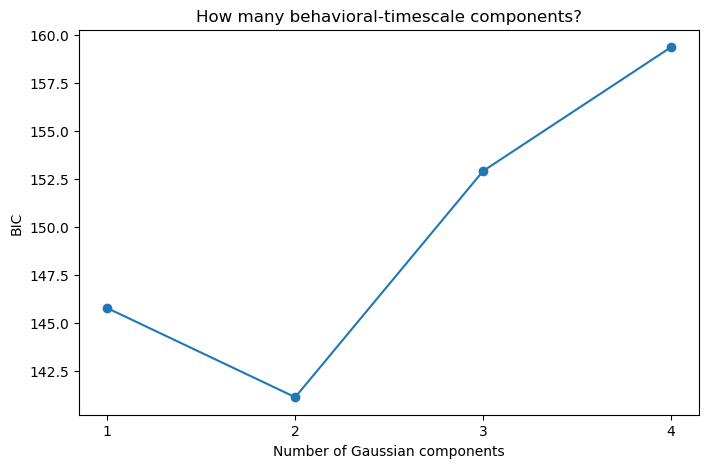

In [134]:
# ============================================================
# STEP 18 — Compare model complexity using BIC
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    gmm_comparison["n_components"],
    gmm_comparison["BIC"],
    marker="o"
)

plt.xticks(
    gmm_comparison["n_components"]
)

plt.xlabel(
    "Number of Gaussian components"
)

plt.ylabel(
    "BIC"
)

plt.title(
    "How many behavioral-timescale components?"
)

plt.show()

In [135]:
# ============================================================
# STEP 18 — Delta BIC
# ============================================================

best_bic = (
    gmm_comparison["BIC"]
    .min()
)

gmm_comparison["delta_BIC"] = (
    gmm_comparison["BIC"]
    - best_bic
)

display(
    gmm_comparison[
        [
            "n_components",
            "BIC",
            "delta_BIC",
            "AIC",
            "min_component_weight",
            "converged"
        ]
    ]
)

,n_components,BIC,delta_BIC,AIC,min_component_weight,converged
0,1,145.770638,4.646116,140.443760,1.000000,True
1,2,141.124522,0.000000,127.807327,0.237784,True
2,3,152.920588,11.796065,131.613075,0.029706,True
3,4,159.377169,18.252647,130.079339,0.099986,True


In [136]:
# ============================================================
# STEP 18 — Identify BIC-preferred model
# ============================================================

best_k = int(
    gmm_comparison.loc[
        gmm_comparison["BIC"].idxmin(),
        "n_components"
    ]
)

best_gmm = gmm_models[
    best_k
]

print("=" * 70)
print("BIC-PREFERRED MIXTURE MODEL")
print("=" * 70)

print(
    "Preferred number of components:",
    best_k
)

print(
    "BIC:",
    best_gmm.bic(X)
)

print(
    "AIC:",
    best_gmm.aic(X)
)

BIC-PREFERRED MIXTURE MODEL
Preferred number of components: 2
BIC: 141.12452248798587
AIC: 127.80732701742552


BIC is lowest for **K = 2**, but only by **4.6** relative to K = 1: *positive*, not strong, evidence. K = 3 and K = 4 are clearly worse. AIC, which penalizes complexity less, also prefers K = 2.

In [137]:
# ============================================================
# STEP 18 — Inspect the preferred mixture components
# ============================================================

component_means_log = (
    best_gmm.means_
    .flatten()
)

component_sd_log = np.sqrt(
    best_gmm.covariances_
    .reshape(best_k)
)

component_weights = (
    best_gmm.weights_
)

# Convert log-space centers back to tau scale
component_tau_centers = np.exp(
    component_means_log
)

component_summary = pd.DataFrame({
    "component":
        np.arange(best_k),

    "weight":
        component_weights,

    "mean_log_tau":
        component_means_log,

    "sd_log_tau":
        component_sd_log,

    "tau_geometric_center":
        component_tau_centers
})

component_summary = (
    component_summary
    .sort_values(
        "tau_geometric_center"
    )
    .reset_index(drop=True)
)

display(
    component_summary
)

,component,weight,mean_log_tau,sd_log_tau,tau_geometric_center
0,0,0.762216,1.599914,0.285649,4.952609
1,1,0.237784,2.299314,0.507558,9.967344


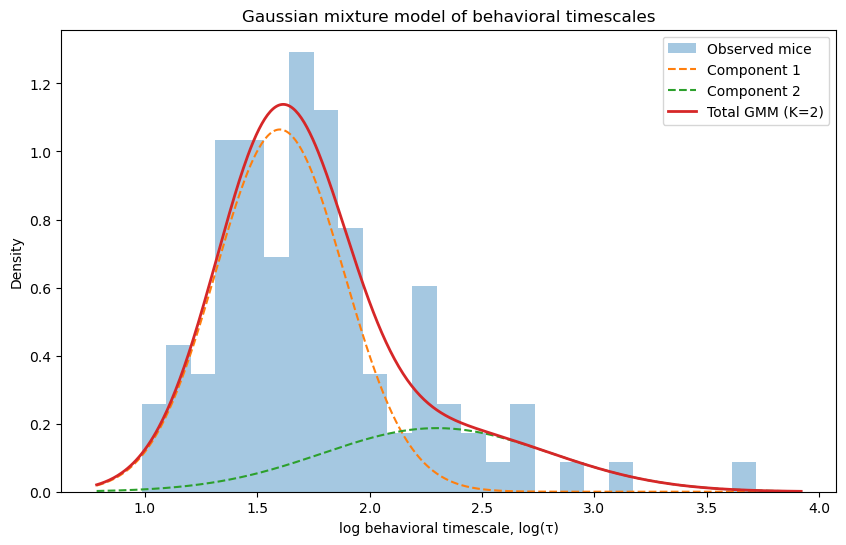

In [138]:
# ============================================================
# STEP 18 — Visualize preferred GMM on log(tau)
# ============================================================

from scipy.stats import norm


x_grid = np.linspace(
    analysis_fits["log_tau"].min() - 0.2,
    analysis_fits["log_tau"].max() + 0.2,
    500
)

plt.figure(figsize=(10, 6))

# Density-normalized histogram
plt.hist(
    analysis_fits["log_tau"],
    bins=25,
    density=True,
    alpha=0.4,
    label="Observed mice"
)

total_density = np.zeros_like(
    x_grid
)

for j in range(best_k):

    mu = (
        best_gmm.means_[j, 0]
    )

    sd = np.sqrt(
        best_gmm.covariances_[j, 0, 0]
    )

    weight = (
        best_gmm.weights_[j]
    )

    component_density = (
        weight
        *
        norm.pdf(
            x_grid,
            loc=mu,
            scale=sd
        )
    )

    total_density += (
        component_density
    )

    plt.plot(
        x_grid,
        component_density,
        linestyle="--",
        label=f"Component {j+1}"
    )


plt.plot(
    x_grid,
    total_density,
    linewidth=2,
    label=f"Total GMM (K={best_k})"
)

plt.xlabel(
    "log behavioral timescale, log(τ)"
)

plt.ylabel(
    "Density"
)

plt.title(
    "Gaussian mixture model of behavioral timescales"
)

plt.legend()

plt.show()

The two components are a dominant **short-timescale component** (76 % of mice, centered at τ ≈ 5.0 trials) and a broad, low-weight **long-timescale component** (24 %, centered at τ ≈ 10.0 trials).

Note that the total density (red) has **a single peak with a right shoulder**. The second component is modeling the **heavy right tail** of the distribution rather than a separate cluster. A Gaussian mixture can win on BIC simply because the data are skewed, so a lower BIC on its own is not evidence for discrete groups. Step 19 tests the two-component solution directly.

### Step 19 — Is the two-group solution robust?

Five checks ask whether the "two groups" would survive closer inspection:

| Check | Question |
|---|---|
| **Separation** | Are the two components actually separated? |
| **Membership** | Are mice assigned to a component with confidence, or do many sit in between? |
| **Bootstrap** | Is K = 2 still selected when the mice are resampled with replacement (500 resamples)? |
| **Measurement uncertainty** | Is K = 2 still selected when each log τ is redrawn according to its own estimation error (500 simulations)? |
| **Leave-one-out** | Does the preference depend on any single mouse? |

Separation is measured with the standardized distance between the component means,

$$D = \frac{\lvert \mu_1 - \mu_2 \rvert}{\sqrt{(\sigma_1^2 + \sigma_2^2)/2}}$$

A clean separation between two modes requires D > 2, and a two-mode split with D < 2 is not meaningful (Ashman et al., 1994; Muratov & Gnedin, 2010).

In [139]:
# ============================================================
# STEP 19 — Order the two components by timescale
# ============================================================

means = best_gmm.means_.flatten()

sds = np.sqrt(
    best_gmm.covariances_[:, 0, 0]
)

weights = best_gmm.weights_

order = np.argsort(means)

short_idx = order[0]
long_idx = order[1]

mu_short = means[short_idx]
mu_long = means[long_idx]

sd_short = sds[short_idx]
sd_long = sds[long_idx]

weight_short = weights[short_idx]
weight_long = weights[long_idx]


# Standardized separation of the two components
# (D > 2 is needed for a clean separation of two modes)
separation_D = (
    abs(mu_long - mu_short)
    /
    np.sqrt(
        (
            sd_short**2
            +
            sd_long**2
        ) / 2
    )
)


print("=" * 70)
print("TWO-COMPONENT SEPARATION")
print("=" * 70)

print(
    f"Short-timescale center: "
    f"{np.exp(mu_short):.3f} trials"
)

print(
    f"Long-timescale center: "
    f"{np.exp(mu_long):.3f} trials"
)

print(
    f"\nShort component weight: "
    f"{weight_short:.3f}"
)

print(
    f"Long component weight: "
    f"{weight_long:.3f}"
)

print(
    f"\nStandardized separation D: "
    f"{separation_D:.3f}"
)

TWO-COMPONENT SEPARATION
Short-timescale center: 4.953 trials
Long-timescale center: 9.967 trials

Short component weight: 0.762
Long component weight: 0.238

Standardized separation D: 1.698


**Separation: D = 1.70 < 2.** The two components overlap substantially, so they do not describe two well-separated populations.

In [140]:
# ============================================================
# STEP 19 — Posterior component-membership probabilities
# ============================================================

posterior = best_gmm.predict_proba(
    X
)

analysis_fits[
    "p_short_component"
] = posterior[
    :,
    short_idx
]

analysis_fits[
    "p_long_component"
] = posterior[
    :,
    long_idx
]


analysis_fits[
    "mixture_group"
] = np.where(
    analysis_fits[
        "p_short_component"
    ]
    >=
    analysis_fits[
        "p_long_component"
    ],
    "short-timescale",
    "long-timescale"
)


analysis_fits[
    "membership_confidence"
] = np.maximum(
    analysis_fits[
        "p_short_component"
    ],
    analysis_fits[
        "p_long_component"
    ]
)


print(
    analysis_fits[
        "mixture_group"
    ].value_counts()
)


print(
    "\nMembership-confidence summary:"
)

print(
    analysis_fits[
        "membership_confidence"
    ].describe()
)

mixture_group
short-timescale    86
long-timescale     20
Name: count, dtype: int64

Membership-confidence summary:
count    106.000000
mean       0.888680
std        0.100366
min        0.547033
25%        0.864119
50%        0.926326
75%        0.954156
max        1.000000
Name: membership_confidence, dtype: float64


In [141]:
# ============================================================
# STEP 19 — Diagnostic ambiguity counts
# ============================================================

n_below_80 = (
    analysis_fits[
        "membership_confidence"
    ]
    < 0.80
).sum()

n_below_90 = (
    analysis_fits[
        "membership_confidence"
    ]
    < 0.90
).sum()


print(
    "Mice with membership confidence < 0.80:",
    n_below_80
)

print(
    "Mice with membership confidence < 0.90:",
    n_below_90
)

Mice with membership confidence < 0.80: 18
Mice with membership confidence < 0.90: 38


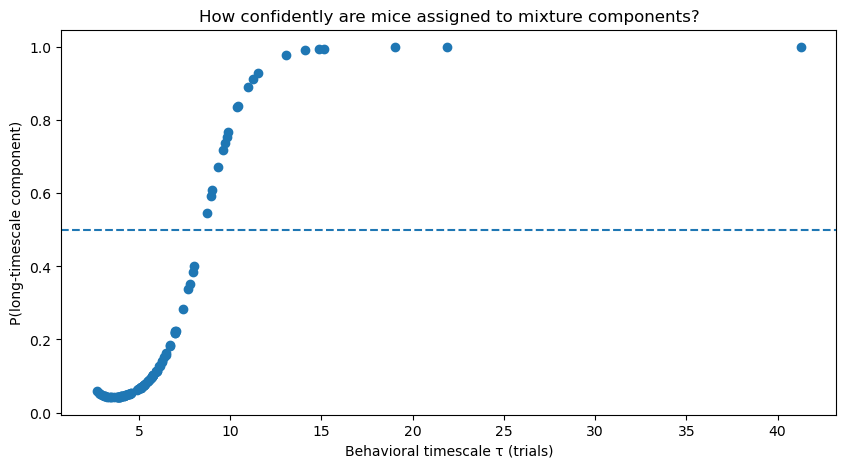

In [142]:
# ============================================================
# STEP 19 — Visualize component membership
# ============================================================

sorted_fits = (
    analysis_fits
    .sort_values("tau")
    .reset_index(drop=True)
)

plt.figure(
    figsize=(10, 5)
)

plt.scatter(
    sorted_fits["tau"],
    sorted_fits[
        "p_long_component"
    ]
)

plt.axhline(
    0.5,
    linestyle="--"
)

plt.xlabel(
    "Behavioral timescale τ (trials)"
)

plt.ylabel(
    "P(long-timescale component)"
)

plt.title(
    "How confidently are mice assigned to mixture components?"
)

plt.show()

In [143]:
# ============================================================
# STEP 19 — Approximate mixture decision boundary
# ============================================================

boundary_grid = np.linspace(
    mu_short,
    mu_long,
    10000
)

boundary_probs = (
    best_gmm
    .predict_proba(
        boundary_grid.reshape(-1, 1)
    )
)

difference = np.abs(
    boundary_probs[:, short_idx]
    -
    boundary_probs[:, long_idx]
)

boundary_index = (
    np.argmin(difference)
)

boundary_log_tau = (
    boundary_grid[
        boundary_index
    ]
)

boundary_tau = np.exp(
    boundary_log_tau
)


print(
    "Approximate equal-membership boundary:"
)

print(
    f"log(tau) = "
    f"{boundary_log_tau:.3f}"
)

print(
    f"tau = "
    f"{boundary_tau:.3f} trials"
)

Approximate equal-membership boundary:
log(tau) = 2.140
tau = 8.501 trials


**Membership: a smooth transition, not a gap.** 86 mice are assigned to the short and 20 to the long component, but the probability of belonging to the long component rises smoothly with τ and crosses 0.5 at **τ ≈ 8.5 trials**. 18 mice have a membership confidence below 0.8, and 38 below 0.9. The "groups" amount to a threshold placed on a continuum rather than a natural boundary in the data.

In [144]:
# ============================================================
# STEP 19 — Bootstrap stability of number of components
# ============================================================

N_BOOT = 500

rng = np.random.default_rng(
    42
)

bootstrap_rows = []


for b in range(N_BOOT):

    indices = rng.integers(
        0,
        len(X),
        size=len(X)
    )

    X_boot = X[
        indices
    ]

    bic_values = {}

    fitted_models = {}

    for k in range(1, 5):

        gmm_b = GaussianMixture(
            n_components=k,
            covariance_type="full",
            n_init=20,
            reg_covar=1e-5,
            random_state=b
        )

        gmm_b.fit(
            X_boot
        )

        bic_values[k] = (
            gmm_b.bic(X_boot)
        )

        fitted_models[k] = gmm_b

    preferred_k = min(
        bic_values,
        key=bic_values.get
    )

    row = {
        "bootstrap": b,
        "preferred_k": preferred_k,
        "bic_1": bic_values[1],
        "bic_2": bic_values[2],
        "bic_3": bic_values[3],
        "bic_4": bic_values[4],

        # Positive means K=2 beats K=1
        "bic_advantage_2_vs_1":
            bic_values[1]
            -
            bic_values[2]
    }

    # Record the structure of the K=2 solution
    gmm2 = fitted_models[2]

    means2 = (
        gmm2.means_
        .flatten()
    )

    sds2 = np.sqrt(
        gmm2.covariances_[
            :, 0, 0
        ]
    )

    weights2 = (
        gmm2.weights_
    )

    order2 = np.argsort(
        means2
    )

    a = order2[0]
    c = order2[1]

    row[
        "short_center_tau"
    ] = np.exp(
        means2[a]
    )

    row[
        "long_center_tau"
    ] = np.exp(
        means2[c]
    )

    row[
        "short_weight"
    ] = weights2[a]

    row[
        "long_weight"
    ] = weights2[c]

    row[
        "separation_D"
    ] = (
        abs(
            means2[c]
            -
            means2[a]
        )
        /
        np.sqrt(
            (
                sds2[a]**2
                +
                sds2[c]**2
            ) / 2
        )
    )

    bootstrap_rows.append(
        row
    )


bootstrap_gmm = pd.DataFrame(
    bootstrap_rows
)

In [145]:
# ============================================================
# STEP 19 — Bootstrap summary
# ============================================================

print("=" * 70)
print("BOOTSTRAP MODEL-SELECTION STABILITY")
print("=" * 70)

print(
    bootstrap_gmm[
        "preferred_k"
    ]
    .value_counts(
        normalize=True
    )
    .sort_index()
)

print(
    "\nBIC advantage of K=2 over K=1:"
)

print(
    bootstrap_gmm[
        "bic_advantage_2_vs_1"
    ]
    .describe()
)

print(
    "\nTwo-component separation D:"
)

print(
    bootstrap_gmm[
        "separation_D"
    ]
    .describe()
)

BOOTSTRAP MODEL-SELECTION STABILITY
preferred_k
1    0.208
2    0.460
3    0.188
4    0.144
Name: proportion, dtype: float64

BIC advantage of K=2 over K=1:
count    500.000000
mean       7.620979
std       11.179032
min      -11.395737
25%       -0.232059
50%        6.086895
75%       13.365811
max       68.446371
Name: bic_advantage_2_vs_1, dtype: float64

Two-component separation D:
count    500.000000
mean       2.282931
std        1.218140
min        0.115102
25%        1.637006
50%        1.948005
75%        2.461242
max        8.535049
Name: separation_D, dtype: float64


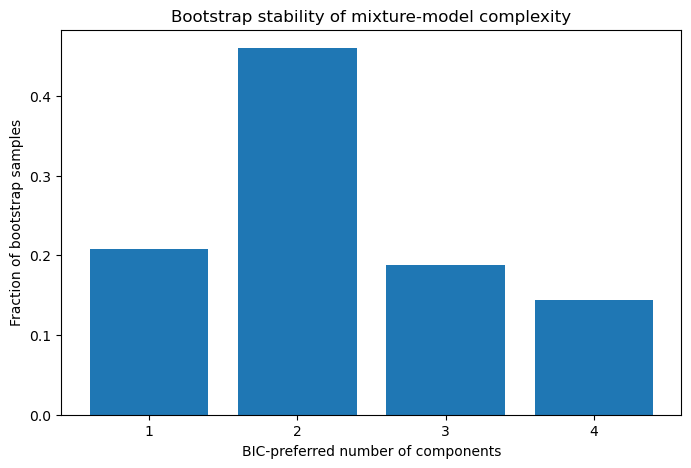

In [146]:
# ============================================================
# STEP 19 — Visualize bootstrap model-selection stability
# ============================================================

bootstrap_k_frequency = (
    bootstrap_gmm[
        "preferred_k"
    ]
    .value_counts(
        normalize=True
    )
    .sort_index()
)

plt.figure(
    figsize=(8, 5)
)

plt.bar(
    bootstrap_k_frequency.index,
    bootstrap_k_frequency.values
)

plt.xticks(
    [1, 2, 3, 4]
)

plt.xlabel(
    "BIC-preferred number of components"
)

plt.ylabel(
    "Fraction of bootstrap samples"
)

plt.title(
    "Bootstrap stability of mixture-model complexity"
)

plt.show()

**Bootstrap: K = 2 is not stable.** Across 500 resamples, K = 2 is selected only **46 %** of the time (K = 1: 21 %, K = 3: 19 %, K = 4: 14 %). The BIC advantage of K = 2 over K = 1 has a median of 6.1 but is negative — favoring a single component — in about a quarter of the resamples. The median separation of the bootstrapped two-component solutions (D = 1.95) also stays below 2.

Resampling with replacement creates duplicated points, which can favor spurious narrow components and partly explains the K = 3 – 4 selections; the key observation is that K = 2 is not consistently selected.

In [147]:
# ============================================================
# STEP 19 — Approximate propagation of tau uncertainty
# ============================================================

log_tau_mean = np.log(
    analysis_fits["tau"]
    .to_numpy()
)

# Approximate standard error of log(tau) from the 95% profile
# interval: (log(high) - log(low)) / (2 * 1.96)
log_tau_se = (
    np.log(
        analysis_fits[
            "tau_ci_high"
        ].to_numpy()
    )
    -
    np.log(
        analysis_fits[
            "tau_ci_low"
        ].to_numpy()
    )
) / (2 * 1.96)


N_MC = 500

rng_unc = np.random.default_rng(
    123
)

uncertainty_rows = []


for sim in range(N_MC):

    sampled_log_tau = rng_unc.normal(
        loc=log_tau_mean,
        scale=log_tau_se
    )

    X_sim = (
        sampled_log_tau
        .reshape(-1, 1)
    )

    bic_values = {}

    for k in range(1, 5):

        model = GaussianMixture(
            n_components=k,
            covariance_type="full",
            n_init=20,
            reg_covar=1e-5,
            random_state=sim
        )

        model.fit(
            X_sim
        )

        bic_values[k] = (
            model.bic(
                X_sim
            )
        )

    preferred_k = min(
        bic_values,
        key=bic_values.get
    )

    uncertainty_rows.append(
        {
            "simulation": sim,
            "preferred_k": preferred_k,

            "bic_advantage_2_vs_1":
                bic_values[1]
                -
                bic_values[2]
        }
    )


uncertainty_gmm = pd.DataFrame(
    uncertainty_rows
)

In [148]:
# ============================================================
# STEP 19 — Uncertainty-propagation summary
# ============================================================

print("=" * 70)
print("MEASUREMENT-UNCERTAINTY SENSITIVITY")
print("=" * 70)

print(
    uncertainty_gmm[
        "preferred_k"
    ]
    .value_counts(
        normalize=True
    )
    .sort_index()
)

print(
    "\nBIC advantage K=2 over K=1:"
)

print(
    uncertainty_gmm[
        "bic_advantage_2_vs_1"
    ]
    .describe()
)

MEASUREMENT-UNCERTAINTY SENSITIVITY
preferred_k
1    0.412
2    0.538
3    0.050
Name: proportion, dtype: float64

BIC advantage K=2 over K=1:
count    500.000000
mean       1.566071
std        5.641100
min      -12.832052
25%       -2.603670
50%        1.082254
75%        5.494277
max       21.875417
Name: bic_advantage_2_vs_1, dtype: float64


**Measurement uncertainty: the preference nearly disappears.** Each mouse's log τ is itself uncertain. Its standard error is approximated from the 95 % profile interval as (log τ<sub>high</sub> − log τ<sub>low</sub>) / (2 × 1.96), and all 106 values are redrawn 500 times. **K = 1 then wins in 41 %** and K = 2 in 54 % of the simulations, with a median BIC advantage of only **1.1** — not worth more than a bare mention. Estimation noise alone is enough to blur the putative two-group structure.

In [149]:
# ============================================================
# STEP 19 — Leave-one-mouse-out model-selection sensitivity
# ============================================================

loo_rows = []


for i in range(len(X)):

    X_loo = np.delete(
        X,
        i,
        axis=0
    )

    bic_values = {}

    # Compare K = 1, 2, 3 on each leave-one-out sample
    for k in range(1, 4):

        model = GaussianMixture(
            n_components=k,
            covariance_type="full",
            n_init=30,
            reg_covar=1e-5,
            random_state=42
        )

        model.fit(
            X_loo
        )

        bic_values[k] = (
            model.bic(
                X_loo
            )
        )

    preferred_k = min(
        bic_values,
        key=bic_values.get
    )

    loo_rows.append(
        {
            "removed_subject":
                analysis_fits[
                    "subject"
                ].iloc[i],

            "removed_tau":
                analysis_fits[
                    "tau"
                ].iloc[i],

            "preferred_k":
                preferred_k,

            "bic_advantage_2_vs_1":
                bic_values[1]
                -
                bic_values[2]
        }
    )


loo_gmm = pd.DataFrame(
    loo_rows
)

In [150]:
# ============================================================
# STEP 19 — Leave-one-mouse-out summary
# ============================================================

print("=" * 70)
print("LEAVE-ONE-MOUSE-OUT STABILITY")
print("=" * 70)

print(
    loo_gmm[
        "preferred_k"
    ]
    .value_counts()
    .sort_index()
)

print(
    "\nBIC advantage K=2 vs K=1:"
)

print(
    loo_gmm[
        "bic_advantage_2_vs_1"
    ]
    .describe()
)

LEAVE-ONE-MOUSE-OUT STABILITY
preferred_k
1      1
2    105
Name: count, dtype: int64

BIC advantage K=2 vs K=1:
count    106.000000
mean       4.579836
std        0.952506
min       -2.119570
25%        4.164135
50%        4.430775
75%        5.024055
max        5.970865
Name: bic_advantage_2_vs_1, dtype: float64


**Leave-one-out: no single influential mouse.** Removing any one mouse (and comparing K = 1 – 3) leaves K = 2 preferred in 105 of 106 cases, with a BIC advantage that stays around 4 – 5. The modest preference for K = 2 in the full sample is therefore not caused by a single outlier — but it is small, and it does not survive resampling or measurement uncertainty.

#### Verdict on H4

| Evidence | Supports discrete groups? |
|---|---|
| BIC on the full sample | Weakly — ΔBIC = 4.6 in favor of K = 2 |
| Shape of the fitted mixture | No — single-peaked density, D = 1.70 < 2 |
| Component membership | No — smooth transition around τ ≈ 8.5 trials; 18 mice ambiguous (confidence < 0.8) |
| Bootstrap | No — K = 2 selected in only 46 % of resamples |
| Measurement uncertainty | No — K = 1 vs K = 2 selected in 41 % vs 54 % of simulations; median ΔBIC = 1.1 |
| Leave-one-out | The weak preference for K = 2 is not driven by a single mouse |

**There is insufficient evidence for discrete behavioral classes.** The prior-updating timescale is best treated as a **continuous phenotype**, and log τ is used as such from here on.

---

## Part 7 · Output

### Step 20 — Freeze the behavioral phenotype table

The final table has one row per mouse (106 mice), sorted from the fastest to the slowest updater:

| Column(s) | Content |
|---|---|
| `subject`, `n_sessions`, `n_trials`, `n_valid_trials` | mouse identity and amount of data |
| `alpha`, `tau` and their 95 % interval limits | maximum-likelihood estimates and profile intervals |
| `relative_tau_ci_width` | precision of the estimate |
| `behavioral_log_tau` | **primary continuous phenotype**, log τ |
| `behavioral_update_speed` | −log τ (larger = faster updating), a convenient direction for correlations |
| `p_short_component`, `p_long_component`, `mixture_group`, `membership_confidence` | mixture-model results, kept for **secondary, exploratory** use only |

The table is saved to `results/behavioral_phenotypes_final.csv`, the input for the next stage of the project: relating behavioral timescales to neural activity recorded in the same mice.

In [151]:
# ============================================================
# STEP 20 — Freeze final behavioral phenotype table
# ============================================================

behavioral_phenotypes = (
    analysis_fits
    .copy()
)

# Primary continuous phenotype (input to the planned neural analysis)
behavioral_phenotypes[
    "behavioral_log_tau"
] = np.log(
    behavioral_phenotypes["tau"]
)

# Convenient direction:
# larger value = faster updating
behavioral_phenotypes[
    "behavioral_update_speed"
] = (
    -behavioral_phenotypes[
        "behavioral_log_tau"
    ]
)

columns_to_keep = [
    "subject",
    "n_sessions",
    "n_trials",
    "n_valid_trials",

    "alpha",
    "tau",

    "alpha_ci_low",
    "alpha_ci_high",
    "tau_ci_low",
    "tau_ci_high",

    "relative_tau_ci_width",

    "behavioral_log_tau",
    "behavioral_update_speed",

    # Secondary / exploratory mixture information
    "p_short_component",
    "p_long_component",
    "mixture_group",
    "membership_confidence"
]

behavioral_phenotypes = (
    behavioral_phenotypes[
        columns_to_keep
    ]
    .sort_values("tau")
    .reset_index(drop=True)
)

display(
    behavioral_phenotypes.head(20)
)

,subject,n_sessions,n_trials,n_valid_trials,alpha,tau,alpha_ci_low,alpha_ci_high,tau_ci_low,tau_ci_high,relative_tau_ci_width,behavioral_log_tau,behavioral_update_speed,p_short_component,p_long_component,mixture_group,membership_confidence
0,KS044,2,1257,804,0.311701,2.677147,0.234068,0.422712,1.820122,3.750071,0.720898,0.984752,-0.984752,0.941298,0.058702,short-timescale,0.941298
1,NR_0031,2,893,619,0.301927,2.782173,0.180169,0.449661,1.674422,5.033785,1.207460,1.023232,-1.023232,0.945953,0.054047,short-timescale,0.945953
2,ZFM-02372,2,1068,829,0.293566,2.877492,0.220593,0.395763,1.984961,4.012484,0.704615,1.056919,-1.056919,0.949252,0.050748,short-timescale,0.949252
3,ibl_witten_19,3,1688,1232,0.284415,2.988153,0.220593,0.368814,2.173186,4.012484,0.615530,1.094656,-1.094656,0.952210,0.047790,short-timescale,0.952210
4,DY_009,9,3907,2780,0.276708,3.086974,0.247542,0.314915,2.644015,3.516043,0.282487,1.127191,-1.127191,0.954212,0.045788,short-timescale,0.954212
5,UCLA033,3,2143,1249,0.274700,3.113617,0.207119,0.355339,2.277745,4.308828,0.652323,1.135785,-1.135785,0.954664,0.045336,short-timescale,0.954664
6,PL030,8,3872,2755,0.272639,3.141369,0.193644,0.341864,2.390376,4.646192,0.718100,1.144659,-1.144659,0.955097,0.044903,short-timescale,0.955097
7,NYU-45,3,1415,556,0.264519,3.254887,0.153220,0.409237,1.899910,6.012695,1.263572,1.180158,-1.180158,0.956520,0.043480,short-timescale,0.956520
8,ZFM-01577,3,1899,1388,0.258453,3.344290,0.207119,0.314915,2.644015,4.308828,0.497808,1.207254,-1.207254,0.957287,0.042713,short-timescale,0.957287
9,KS096,5,3460,2600,0.252375,3.438149,0.220593,0.287966,2.944383,4.012484,0.310662,1.234933,-1.234933,0.957802,0.042198,short-timescale,0.957802


In [152]:
# ============================================================
# STEP 20 — Save frozen behavioral phenotype table
# ============================================================

BEHAVIORAL_PHENOTYPE_PATH = (
    OUTPUT_DIR
    / "behavioral_phenotypes_final.csv"
)

behavioral_phenotypes.to_csv(
    BEHAVIORAL_PHENOTYPE_PATH,
    index=False
)

print(
    "Saved final behavioral phenotype table:"
)

print(
    BEHAVIORAL_PHENOTYPE_PATH
)

print(
    "\nNumber of mice:",
    len(behavioral_phenotypes)
)

Saved final behavioral phenotype table:
/home/omidi/pytopia/paper-brain-wide-map/results/behavioral_phenotypes_final.csv

Number of mice: 106


---

## Conclusions

### Main findings

1. **Mice use the hidden block prior (H1).** In the example session, the block shifted choices most where the stimulus was uninformative (P(right) at 0 % contrast: 0.93 vs 0.41), and adding it to a stimulus-only logistic model improved the fit by ΔAIC = −19.1.
2. **An action-kernel observer yields interpretable, well-identified timescales.** Pooling sessions narrowed the 95 % interval about four-fold compared with a single session (PL033: τ = 9.0 trials, interval 7.4 – 11.1).
3. **The timescale behaves like a stable trait (H2).** For PL033, one α shared across 13 sessions beat session-specific values (ΔAIC = −13.4), and every session estimate was compatible with the shared value.
4. **Mice differ substantially (H3).** Across 106 mice, τ spans 2.7 – 41 trials (median 5.5; 10th – 90th percentile 3.6 – 10.4). The median closely matches the 5.45 trials reported by Findling et al. (2025).
5. **The differences are continuous, not categorical (H4).** A two-component mixture is only weakly preferred, its components overlap (D = 1.7), and the preference is unstable under resampling (K = 2 in 46 % of bootstraps) and under measurement uncertainty (K = 1 in 41 % of simulations).

> **Bottom line.** Behavioral updating timescales show substantial inter-individual variability across mice. Although a two-component Gaussian mixture provided a modest improvement over a single-component model, the inferred components were not robust to resampling and overlapped strongly once parameter uncertainty was considered. We therefore find insufficient evidence for discrete behavioral classes and treat the prior-updating timescale as a **continuous computational phenotype**.

### Discussion

Most mice base their expectations on roughly their last five or six choices. Findling et al. (2025) note that this typical value is close to the action-kernel timescale that maximizes the fraction of correct responses in the task. Individual mice, however, sit at clearly different points around it. A mouse with τ ≈ 3 trials reacts quickly to a block switch, but its prior is pushed around by every chance choice; a mouse with τ ≈ 10 – 15 trials has a steadier prior that lags behind switches. Individual differences in τ may therefore reflect different positions on this **flexibility–stability trade-off** rather than qualitatively different strategies, which is consistent with the continuous distribution found here.

### Limitations

* **Model dependence.** τ is defined within the action-kernel model. Alternative prior models (for example a stimulus kernel or Bayes-optimal block inference) were not compared at the population level, and the decision model has no static side-bias term; asymmetric lapse rates and the prior partly absorb such biases.
* **Session boundaries.** The prior is reset to 0.5 at the start of every session, and the 90 unbiased trials contribute to its updates.
* **Approximate intervals.** Profile intervals rely on Wilks' approximation and on the 60-point α grid, so their limits are quantized: identical limits such as 7.41 or 11.14 trials recur across mice.
* **Sample.** Only Brain-Wide Map recording sessions of trained mice with at least two sessions were used (106 mice after QC). Many mice contribute only two or three sessions, which limits precision.
* **Lab effects.** The mice come from 12 laboratories. Part of the variability in τ could be related to lab, rig or protocol differences, which were not modeled.
* **Power of mixture tests.** One-dimensional Gaussian mixtures fitted to about 100 values are sensitive to skewness and outliers, and the uncertainty propagation assumes Gaussian errors on log τ derived from the profile intervals.

### Next steps

1. **Link behavior to the brain.** Relate each mouse's τ to neural data from the same Brain-Wide Map sessions — for example, test whether the timescale of the prior decoded from pre-stimulus activity (as in Findling et al., 2025) tracks the behavioral τ across mice, and in which brain regions.
2. **Hierarchical modeling.** Fit τ in a hierarchical (mixed-effects) model with mouse and lab levels, to separate lab effects and to shrink noisy estimates from mice with few sessions.
3. **Model comparison.** Compare the action kernel with alternative prior models and add a static bias term, to make sure that individual differences in τ are not an artifact of the chosen model.
4. **Stability over time.** Test whether τ changes across a mouse's sessions (for example early vs late sessions) and whether it relates to task performance.

## References

* Ashman, K. M., Bird, C. M., & Zepf, S. E. (1994). Detecting bimodality in astronomical datasets. *The Astronomical Journal*, 108, 2348–2361. https://doi.org/10.1086/117248
* Findling, C., Hubert, F., International Brain Laboratory, Acerbi, L., Benson, B., Benson, J., et al. (2025). Brain-wide representations of prior information in mouse decision-making. *Nature*, 645, 192–200. https://doi.org/10.1038/s41586-025-09226-1
* International Brain Laboratory et al. (2021). Standardized and reproducible measurement of decision-making in mice. *eLife*, 10, e63711. https://doi.org/10.7554/eLife.63711
* International Brain Laboratory et al. (2025). A brain-wide map of neural activity during complex behaviour. *Nature*, 645, 177–191. https://doi.org/10.1038/s41586-025-09235-0
* Kass, R. E., & Raftery, A. E. (1995). Bayes factors. *Journal of the American Statistical Association*, 90(430), 773–795.
* Muratov, A. L., & Gnedin, O. Y. (2010). Modeling the metallicity distribution of globular clusters. *The Astrophysical Journal*, 718, 1266.
* Wilks, S. S. (1938). The large-sample distribution of the likelihood ratio for testing composite hypotheses. *The Annals of Mathematical Statistics*, 9(1), 60–62.

**Data and code:** [IBL Brain-Wide Map](https://www.internationalbrainlab.com/brainwide-map) · [paper-brain-wide-map](https://github.com/int-brain-lab/paper-brain-wide-map) · [ONE API](https://int-brain-lab.github.io/ONE/)

## Acknowledgements

This project was carried out during [Neuromatch Academy: Computational Neuroscience](https://compneuro.neuromatch.io/). The data and analysis tools are openly provided by the [International Brain Laboratory](https://www.internationalbrainlab.com/).